# Notebook 04 — EDA and Research Scope
**Khảo sát dữ liệu khám phá và xác định phạm vi nghiên cứu**

## 1. Mục tiêu

Thực hiện phân tích khám phá dữ liệu (Exploratory Data Analysis — EDA) nhằm khảo sát đặc điểm, phân bố, chất lượng và khả năng khai thác của bộ dữ liệu CBIS-DDSM.

Kết quả phân tích được sử dụng làm căn cứ để xác định phạm vi nghiên cứu phù hợp, bao gồm Mass, Calcification hoặc kết hợp cả hai, đồng thời đánh giá khả năng sử dụng ROI Mask và Bounding Box cho bài toán phát hiện, định vị tổn thương.

## 2. Dữ liệu đầu vào

Kế thừa kết quả từ các Notebook trước:

- Notebook 01 — Data Inventory.
- Notebook 02 — Data Quality and Linkage.
- Notebook 03 — Lesion Dataset Construction.

Dữ liệu đã xử lý được lưu tại:

`C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb03_lesion_dataset`

Dữ liệu DICOM gốc được bảo toàn trong thư mục `Data\rawdata`.

## 3. Nội dung thực hiện

- Khảo sát quy mô và phân bố Mass, Calcification.
- Phân tích phân bố pathology và các thuộc tính mô tả tổn thương.
- Khảo sát số lượng bệnh nhân, annotation, candidate và ảnh.
- Phân tích bên vú và góc chụp CC/MLO.
- Khảo sát kích thước ảnh DICOM và ROI Mask.
- Phân tích diện tích, hình dạng và Bounding Box của ROI.
- Trực quan hóa Full Image, Cropped Image và ROI Mask.
- Đánh giá khả năng khai thác dữ liệu cho bài toán phát hiện và định vị.
- So sánh tính khả thi của các phạm vi nghiên cứu Mass, Calcification và kết hợp cả hai.

## 4. Nguyên tắc thực hiện

- Chỉ sử dụng dataset CBIS-DDSM.
- Không tự suy diễn hoặc tạo số liệu chưa được thống kê.
- Phân biệt rõ patient, annotation, candidate và image.
- Bảo toàn các nhãn pathology gốc.
- Không tự ý resize ROI Mask hoặc giả định Bounding Box đã cùng hệ tọa độ với Full Image.
- Kiểm soát patient-level data leakage.
- Chưa lựa chọn kiến trúc mô hình khi chưa hoàn thành khảo sát dữ liệu.

## 5. Kết quả đầu ra

- Các bảng thống kê EDA.
- Các biểu đồ phân tích phân bố dữ liệu.
- Hình ảnh minh họa Full Image, Cropped Image và ROI Mask.
- Báo cáo chất lượng và khả năng sử dụng annotation cho localization.
- Đánh giá ưu, nhược điểm của từng phạm vi nghiên cứu.
- Đề xuất phạm vi nghiên cứu chính thức cho các giai đoạn tiếp theo.

## 6. Phạm vi chưa thực hiện

Notebook này chưa triển khai xây dựng pipeline huấn luyện, lựa chọn kiến trúc học sâu cụ thể hoặc huấn luyện mô hình.

### 04.1 — Kiểm tra và nạp dữ liệu đầu vào

**Mục tiêu:** Nạp lại các bảng dữ liệu đã được xây dựng và kiểm định ở Notebook 03, đảm bảo dữ liệu sẵn sàng cho quá trình EDA.

**Đầu vào:** Các file CSV và báo cáo trong thư mục `nb03_lesion_dataset`.

In [1]:
# KHÔI PHỤC ANNOTATION MASTER KHI KERNEL CHƯA CÓ DỮ LIỆU

from pathlib import Path
import pandas as pd

detail_fields = [
    "pathology",
    "assessment",
    "subtlety",
    "mass_shape",
    "mass_margins",
    "calc_type",
    "calc_distribution"
]


def normalize_annotation_column(column_name):
    name = str(column_name).strip().lower()

    while name.startswith("raw__"):
        name = name[5:]

    return name

# 1. Kiểm tra các DataFrame đang tồn tại trong Kernel

if "annotation_master_df" not in globals():

    candidate_frames = []

    for frame_name, frame in list(globals().items()):

        if not isinstance(frame, pd.DataFrame):
            continue

        if "annotation_id" not in frame.columns:
            continue

        normalized_columns = {
            normalize_annotation_column(col): col
            for col in frame.columns
        }

        if "pathology" not in normalized_columns:
            continue

        available_fields = [
            field for field in detail_fields
            if field in normalized_columns
        ]

        candidate_frames.append({
            "name": frame_name,
            "frame": frame,
            "field_count": len(available_fields),
            "annotation_count": frame["annotation_id"].nunique()
        })

    # Ưu tiên DataFrame có nhiều trường metadata
    # và số annotation đầy đủ hơn.
    candidate_frames.sort(
        key=lambda item: (
            item["field_count"],
            item["annotation_count"]
        ),
        reverse=True
    )

    if candidate_frames:

        selected = candidate_frames[0]

        annotation_master_df = selected["frame"]

        print(
            "[OK] Khôi phục annotation_master_df "
            f"từ DataFrame: {selected['name']}"
        )

    else:

        # 2. Nếu Kernel không có DataFrame phù hợp, tìm CSV đã lưu từ Notebook 03.

        project_roots = []

        for variable_name in ["PROJECT_ROOT", "project_root"]:

            if variable_name in globals():

                try:
                    project_roots.append(
                        Path(str(globals()[variable_name]))
                    )
                except (TypeError, ValueError):
                    pass

        project_roots.extend([
            Path.cwd(),
            Path.cwd().parent
        ])

        unique_roots = []

        for root in project_roots:

            if root not in unique_roots:
                unique_roots.append(root)

        possible_paths = []

        for root in unique_roots:

            for folder_name in ["Data", "data"]:

                possible_paths.append(
                    root
                    / folder_name
                    / "processed"
                    / "nb03_lesion_dataset"
                    / "lesion_annotation_mapping.csv"
                )

        annotation_file = next(
            (
                path for path in possible_paths
                if path.is_file()
            ),
            None
        )

        if annotation_file is None:

            raise FileNotFoundError(
                "Không tìm thấy lesion_annotation_mapping.csv.\n"
                "Hãy kiểm tra thư mục:\n"
                "Data/processed/nb03_lesion_dataset/"
            )

        annotation_master_df = pd.read_csv(
            annotation_file,
            low_memory=False
        )

        print(
            "[OK] Đã đọc lại annotation_master_df từ:\n",
            annotation_file
        )
        
# 3. Kiểm tra cấu trúc dữ liệu sau khi khôi phục

if "annotation_id" not in annotation_master_df.columns:
    raise KeyError(
        "Nguồn annotation không có annotation_id."
    )

if annotation_master_df["annotation_id"].duplicated().any():
    raise ValueError(
        "annotation_master_df có annotation_id trùng."
    )

normalized_columns = {
    normalize_annotation_column(col): col
    for col in annotation_master_df.columns
}

if "pathology" not in normalized_columns:
    raise KeyError(
        "Không tìm thấy pathology trong nguồn annotation."
    )

print("\n=== KIỂM TRA ANNOTATION MASTER ===")
print("Kích thước:", annotation_master_df.shape)
print(
    "Unique annotation:",
    annotation_master_df["annotation_id"].nunique()
)

print("\nCác trường metadata tìm thấy:")

display(
    pd.DataFrame([
        {
            "field": field,
            "source_column": normalized_columns.get(field),
            "available": field in normalized_columns
        }
        for field in detail_fields
    ])
)

print("\n[PASS] Annotation metadata đã sẵn sàng cho 04.8.")


[OK] Đã đọc lại annotation_master_df từ:
 c:\Breast-Cancer-CBIS-DDSM\Data\processed\nb03_lesion_dataset\lesion_annotation_mapping.csv

=== KIỂM TRA ANNOTATION MASTER ===
Kích thước: (3568, 51)
Unique annotation: 3568

Các trường metadata tìm thấy:


,field,source_column,available
0,pathology,raw__pathology,True
1,assessment,raw__assessment,True
2,subtlety,raw__subtlety,True
3,mass_shape,mass_shape,True
4,mass_margins,mass_margins,True
5,calc_type,calc_type,True
6,calc_distribution,calc_distribution,True



[PASS] Annotation metadata đã sẵn sàng cho 04.8.


In [2]:
# 4.1.1. Thiết lập đường dẫn và nạp dữ liệu

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
INPUT_DIR = PROJECT_ROOT / "Data" / "processed" / "nb03_lesion_dataset"

FILES = {
    "lesion_master": "lesion_master.csv",
    "review_groups": "lesion_review_groups.csv",
    "annotation_mapping": "lesion_annotation_mapping.csv",
    "image_mapping": "lesion_image_mapping.csv",
    "image_catalog": "image_path_catalog.csv",
    "roi_mapping": "lesion_roi_mapping.csv",
    "integrity_check": "nb03_integrity_check.csv",
    "summary_report": "nb03_summary_report.txt",
}

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"Không tìm thấy dự án: {PROJECT_ROOT}")

if not INPUT_DIR.is_dir():
    raise FileNotFoundError(f"Không tìm thấy dữ liệu: {INPUT_DIR}")

missing_files = [
    filename
    for filename in FILES.values()
    if not (INPUT_DIR / filename).is_file()
]

if missing_files:
    raise FileNotFoundError(f"Các file bị thiếu: {missing_files}")

print(f"[ĐẠT] Tìm thấy đầy đủ {len(FILES)} file đầu vào.")
print(f"Thư mục dữ liệu: {INPUT_DIR}")

nb04_tables = {
    name: pd.read_csv(
        INPUT_DIR / filename,
        encoding="utf-8-sig",
        low_memory=False,
    )
    for name, filename in FILES.items()
    if filename.endswith(".csv")
}

nb04_summary_report = (
    INPUT_DIR / FILES["summary_report"]
).read_text(encoding="utf-8-sig")

# Gán DataFrame cho các biến sử dụng trong Notebook 04

nb04_lesion_master_df = nb04_tables["lesion_master"]
nb04_lesion_review_groups_df = nb04_tables["review_groups"]
nb04_lesion_annotation_mapping_df = nb04_tables["annotation_mapping"]
nb04_lesion_image_mapping_df = nb04_tables["image_mapping"]
nb04_image_path_catalog_df = nb04_tables["image_catalog"]
nb04_lesion_roi_mapping_df = nb04_tables["roi_mapping"]
nb04_integrity_check_df = nb04_tables["integrity_check"]

print(f"[ĐẠT] Đã nạp {len(nb04_tables)} bảng CSV và 1 báo cáo TXT.")

[ĐẠT] Tìm thấy đầy đủ 8 file đầu vào.
Thư mục dữ liệu: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb03_lesion_dataset
[ĐẠT] Đã nạp 7 bảng CSV và 1 báo cáo TXT.


In [3]:
# 4.1.2. Kiểm tra quy mô và kích thước bảng
dataframe_objects = {
    "lesion_master_df": nb04_lesion_master_df,
    "lesion_review_groups_df": nb04_lesion_review_groups_df,
    "lesion_annotation_mapping_df": nb04_lesion_annotation_mapping_df,
    "lesion_image_mapping_df": nb04_lesion_image_mapping_df,
    "image_path_catalog_df": nb04_image_path_catalog_df,
    "lesion_roi_mapping_df": nb04_lesion_roi_mapping_df,
    "nb03_integrity_check_df": nb04_integrity_check_df,
}

expected_shapes = {
    "lesion_master_df": (1989, 42),
    "lesion_review_groups_df": (140, 36),
    "lesion_annotation_mapping_df": (3568, 51),
    "lesion_image_mapping_df": (7136, 17),
    "image_path_catalog_df": (6671, 4),
    "lesion_roi_mapping_df": (3568, 87),
    "nb03_integrity_check_df": (54, 5),
}

shape_rows = []

for name, df in dataframe_objects.items():

    expected = expected_shapes[name]
    actual = df.shape

    shape_rows.append({
        "dataframe": name,
        "so_dong": actual[0],
        "so_cot": actual[1],
        "kich_thuoc_ky_vong": str(expected),
        "ket_qua": "ĐẠT" if actual == expected else "KHÔNG ĐẠT",
        "dung_luong_MB": round(
            df.memory_usage(deep=True).sum() / (1024 ** 2), 3
        ),
    })

nb04_shape_check_df = pd.DataFrame(shape_rows)

display(nb04_shape_check_df)

,dataframe,so_dong,so_cot,kich_thuoc_ky_vong,ket_qua,dung_luong_MB
0,lesion_master_df,1989,42,"(1989, 42)",ĐẠT,3.915
1,lesion_review_groups_df,140,36,"(140, 36)",ĐẠT,0.262
2,lesion_annotation_mapping_df,3568,51,"(3568, 51)",ĐẠT,11.964
3,lesion_image_mapping_df,7136,17,"(7136, 17)",ĐẠT,9.021
4,image_path_catalog_df,6671,4,"(6671, 4)",ĐẠT,3.795
5,lesion_roi_mapping_df,3568,87,"(3568, 87)",ĐẠT,17.980
6,nb03_integrity_check_df,54,5,"(54, 5)",ĐẠT,0.019


In [4]:
# 4.1.3. Kiểm tra khóa định danh

key_definitions = {
    "lesion_master_df": ["lesion_candidate_id"],
    "lesion_review_groups_df": ["review_group_id"],
    "lesion_annotation_mapping_df": ["annotation_id"],
    "lesion_image_mapping_df": ["annotation_id", "image_role"],
    "image_path_catalog_df": ["image_role", "image_path_key"],
    "lesion_roi_mapping_df": ["annotation_id"],
}

key_rows = []

for table_name, columns in key_definitions.items():

    df = dataframe_objects[table_name]

    key_data = (
        df[columns]
        .astype("string")
        .apply(lambda col: col.str.strip())
        .replace("", pd.NA)
    )

    missing_count = int(key_data.isna().any(axis=1).sum())

    valid_data = key_data.dropna()

    duplicate_count = int(
        valid_data.duplicated().sum()
    )

    key_rows.append({
        "dataframe": table_name,
        "khoa_dinh_danh": " + ".join(columns),
        "gia_tri_thieu": missing_count,
        "khoa_trung": duplicate_count,
        "ket_qua": (
            "ĐẠT"
            if missing_count == 0 and duplicate_count == 0
            else "KHÔNG ĐẠT"
        ),
    })

nb04_key_check_df = pd.DataFrame(key_rows)

display(nb04_key_check_df)

,dataframe,khoa_dinh_danh,gia_tri_thieu,khoa_trung,ket_qua
0,lesion_master_df,lesion_candidate_id,0,0,ĐẠT
1,lesion_review_groups_df,review_group_id,0,0,ĐẠT
2,lesion_annotation_mapping_df,annotation_id,0,0,ĐẠT
3,lesion_image_mapping_df,annotation_id + image_role,0,0,ĐẠT
4,image_path_catalog_df,image_role + image_path_key,0,0,ĐẠT
5,lesion_roi_mapping_df,annotation_id,0,0,ĐẠT


In [5]:
# 4.1.4. Tổng hợp kết quả và kết luận

shape_passed = nb04_shape_check_df["ket_qua"].eq("ĐẠT").all()
key_passed = nb04_key_check_df["ket_qua"].eq("ĐẠT").all()

qa_counts = (
    nb04_integrity_check_df["ket_qua"]
    .value_counts()
    .to_dict()
)

nb03_qa_passed = qa_counts == {"ĐẠT": 54}
report_passed = bool(nb04_summary_report.strip())
nb04_input_ready = (
    shape_passed
    and key_passed
    and nb03_qa_passed
    and report_passed
)

print("=" * 65)
print("KẾT LUẬN PHẦN 04.1")
print("=" * 65)

print(f"Kích thước các bảng: {'ĐẠT' if shape_passed else 'CHƯA ĐẠT'}")
print(f"Khóa định danh: {'ĐẠT' if key_passed else 'CHƯA ĐẠT'}")
print(f"Kiểm định Notebook 03: {'ĐẠT' if nb03_qa_passed else 'CHƯA ĐẠT'}")
print(f"Báo cáo đầu vào: {'ĐẠT' if report_passed else 'CHƯA ĐẠT'}")

if not nb04_input_ready:
    raise ValueError("Dữ liệu đầu vào chưa đáp ứng điều kiện EDA.")

print("\n[ĐẠT] Dữ liệu đã sẵn sàng cho Notebook 04.")
print(f"Số Candidate: {len(nb04_lesion_master_df):,}")
print(f"Số Review Group: {len(nb04_lesion_review_groups_df):,}")
print(f"Số Annotation: {len(nb04_lesion_annotation_mapping_df):,}")
print(f"Số ROI Mapping: {len(nb04_lesion_roi_mapping_df):,}")


KẾT LUẬN PHẦN 04.1
Kích thước các bảng: ĐẠT
Khóa định danh: ĐẠT
Kiểm định Notebook 03: ĐẠT
Báo cáo đầu vào: ĐẠT

[ĐẠT] Dữ liệu đã sẵn sàng cho Notebook 04.
Số Candidate: 1,989
Số Review Group: 140
Số Annotation: 3,568
Số ROI Mapping: 3,568


### 04.2 — Khảo sát quy mô và thành phần dữ liệu

**Mục tiêu:** Khảo sát quy mô và thành phần của bộ dữ liệu CBIS-DDSM sau khi đã xây dựng các bảng liên kết ở Notebook 03.

**Nội dung thực hiện:**
- Thống kê tổng số bệnh nhân, annotation, candidate và review group.
- Phân tích phân bố Mass và Calcification.
- Thống kê số candidate và review group theo loại tổn thương.
- Khảo sát số lượng annotation theo bên vú và góc chụp.
- Thống kê ảnh Full Image, Cropped Image và số đường dẫn ảnh duy nhất.
- Đối chiếu các số liệu giữa Annotation Mapping, Image Mapping và Image Catalog.

**Nguyên tắc:** Phân biệt số bệnh nhân, annotation, candidate và đường dẫn ảnh. Các đơn vị này không được xem là tương đương.

In [6]:
# 4.2.1. Chuẩn bị dữ liệu khảo sát

# 1. KIỂM TRA DỮ LIỆU ĐẦU VÀO

if not nb04_input_ready:
    raise ValueError("Dữ liệu đầu vào chưa sẵn sàng.")

annotation_eda_df = nb04_lesion_annotation_mapping_df.copy()

required_columns = [
    "annotation_id",
    "patient_id",
    "lesion_type",
    "lesion_candidate_id",
    "review_group_id",
]

missing = [
    col for col in required_columns
    if col not in annotation_eda_df.columns
]

if missing:
    raise ValueError(f"Annotation Mapping thiếu cột: {missing}")


# 2. CHUẨN HÓA GIÁ TRỊ DÙNG CHO EDA

annotation_eda_df["_lesion_type"] = (
    annotation_eda_df["lesion_type"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("[ĐẠT] Dữ liệu khảo sát đã sẵn sàng.")
print(f"Số annotation: {len(annotation_eda_df):,}")

# 3. THỐNG KÊ QUY MÔ DỮ LIỆU

nb04_dataset_scale_df = pd.DataFrame([
    {
        "don_vi": "Patient",
        "so_luong": annotation_eda_df["patient_id"].nunique(),
    },
    {
        "don_vi": "Annotation",
        "so_luong": annotation_eda_df["annotation_id"].nunique(),
    },
    {
        "don_vi": "Candidate",
        "so_luong": nb04_lesion_master_df["lesion_candidate_id"].nunique(),
    },
    {
        "don_vi": "Review Group",
        "so_luong": nb04_lesion_review_groups_df["review_group_id"].nunique(),
    },
    {
        "don_vi": "Image Mapping",
        "so_luong": len(nb04_lesion_image_mapping_df),
    },
    {
        "don_vi": "ROI Mapping",
        "so_luong": len(nb04_lesion_roi_mapping_df),
    },
    {
        "don_vi": "Image Path Catalog",
        "so_luong": len(nb04_image_path_catalog_df),
    },
])

display(nb04_dataset_scale_df)

# 4. PHÂN BỐ THEO LOẠI TỔN THƯƠNG

annotation_type_summary = (
    annotation_eda_df
    .groupby("_lesion_type", dropna=False)
    .agg(
        so_annotation=("annotation_id", "nunique"),
        so_patient=("patient_id", "nunique"),
    )
    .reset_index()
    .rename(columns={"_lesion_type": "lesion_type"})
)

candidate_eda_df = annotation_eda_df.loc[
    annotation_eda_df["lesion_candidate_id"].notna()
].copy()

candidate_type_summary = (
    candidate_eda_df
    .groupby("_lesion_type", dropna=False)
    .agg(
        so_candidate=("lesion_candidate_id", "nunique"),
        so_patient=("patient_id", "nunique"),
    )
    .reset_index()
    .rename(columns={"_lesion_type": "lesion_type"})
)

review_eda_df = annotation_eda_df.loc[
    annotation_eda_df["review_group_id"].notna()
].copy()

review_type_summary = (
    review_eda_df
    .groupby("_lesion_type", dropna=False)
    .agg(
        so_review_group=("review_group_id", "nunique"),
    )
    .reset_index()
    .rename(columns={"_lesion_type": "lesion_type"})
)

nb04_lesion_type_summary_df = (
    annotation_type_summary
    .merge(candidate_type_summary, on="lesion_type", how="outer")
    .merge(review_type_summary, on="lesion_type", how="outer")
)

display(nb04_lesion_type_summary_df)

# 5. KIỂM TRA LOẠI TỔN THƯƠNG TRONG CANDIDATE

candidate_type_consistency_df = (
    candidate_eda_df
    .groupby("lesion_candidate_id")
    .agg(
        so_loai_ton_thuong=("_lesion_type", "nunique"),
        cac_loai_ton_thuong=(
            "_lesion_type",
            lambda x: ", ".join(sorted(x.dropna().unique())),
        ),
    )
    .reset_index()
)

candidate_type_conflicts_df = (
    candidate_type_consistency_df.loc[
        candidate_type_consistency_df["so_loai_ton_thuong"] > 1
    ]
    .copy()
)

print("Số Candidate:", len(candidate_type_consistency_df))
print("Candidate có nhiều loại tổn thương:", len(candidate_type_conflicts_df))

display(candidate_type_conflicts_df.head(20))

[ĐẠT] Dữ liệu khảo sát đã sẵn sàng.
Số annotation: 3,568


,don_vi,so_luong
0,Patient,1566
1,Annotation,3568
2,Candidate,1989
3,Review Group,140
4,Image Mapping,7136
5,ROI Mapping,3568
6,Image Path Catalog,6671


,lesion_type,so_annotation,so_patient_x,so_candidate,so_patient_y,so_review_group
0,calcification,1872,753,837,704,108
1,mass,1696,892,1152,874,32


Số Candidate: 1989
Candidate có nhiều loại tổn thương: 0


,lesion_candidate_id,so_loai_ton_thuong,cac_loai_ton_thuong


### Lưu ý: 
Tổng số bệnh nhân ở đây là số patient_id duy nhất trong Annotation Mapping. Một bệnh nhân có thể xuất hiện ở cả Mass và Calcification.

In [7]:
 # 6. PHÂN BỐ BÊN VÚ VÀ GÓC CHỤP

def summarize_annotation_category(df, column):

    temp = df.copy()

    temp[column] = (
        temp[column]
        .astype("string")
        .str.strip()
        .fillna("MISSING")
    )

    return (
        temp.groupby(column)
        .agg(
            so_annotation=("annotation_id", "nunique"),
            so_patient=("patient_id", "nunique"),
        )
        .reset_index()
        .sort_values("so_annotation", ascending=False)
    )


for column in ["laterality", "image_view"]:

    if column in annotation_eda_df.columns:

        print(f"\nPhân bố {column}:")

        display(
            summarize_annotation_category(
                annotation_eda_df,
                column,
            )
        )

    else:
        print(f"[THIẾU] Không tìm thấy cột {column}.")

# 7. PHÂN BỐ THEO NGUỒN DỮ LIỆU

for column in ["source_split", "source_table"]:

    if column in annotation_eda_df.columns:

        print(f"\nPhân bố {column}:")

        display(
            summarize_annotation_category(
                annotation_eda_df,
                column,
            )
        )

    else:
        print(f"[THÔNG TIN] Không có cột {column} trong dữ liệu.")

# 8. THỐNG KÊ CÁC VAI TRÒ ẢNH

image_mapping_summary = (
    nb04_lesion_image_mapping_df
    .groupby("image_role")
    .agg(
        so_quan_he=("annotation_id", "size"),
        so_annotation=("annotation_id", "nunique"),
        so_duong_dan=("image_path_key", "nunique"),
    )
    .reset_index()
)

catalog_summary = (
    nb04_image_path_catalog_df
    .groupby("image_role")
    .agg(
        so_path_trong_catalog=("image_path_key", "nunique"),
    )
    .reset_index()
)

nb04_image_summary_df = image_mapping_summary.merge(
    catalog_summary,
    on="image_role",
    how="outer",
)

display(nb04_image_summary_df)


Phân bố laterality:


,laterality,so_annotation,so_patient
0,LEFT,1819,874
1,RIGHT,1749,834



Phân bố image_view:


,image_view,so_annotation,so_patient
1,MLO,1896,1473
0,CC,1672,1312



Phân bố source_split:


,source_split,so_annotation,so_patient
1,train,2864,1248
0,test,704,349



Phân bố source_table:


,source_table,so_annotation,so_patient
1,calc_train,1546,602
3,mass_train,1318,691
2,mass_test,378,201
0,calc_test,326,151


,image_role,so_quan_he,so_annotation,so_duong_dan,so_path_trong_catalog
0,cropped_image,3568,3568,3568,3568
1,full_image,3568,3568,3103,3103


In [8]:
# 9. KẾT LUẬN KHẢO SÁT QUY MÔ DỮ LIỆU

print("=" * 65)
print("KẾT LUẬN PHẦN 04.2")
print("=" * 65)

print(f"Tổng số bệnh nhân: {annotation_eda_df['patient_id'].nunique():,}")
print(f"Tổng số annotation: {annotation_eda_df['annotation_id'].nunique():,}")
print(f"Tổng số candidate: {len(nb04_lesion_master_df):,}")
print(f"Tổng số review group: {len(nb04_lesion_review_groups_df):,}")

print("\nPhân bố loại tổn thương:")
display(nb04_lesion_type_summary_df)

print("\nPhân bố vai trò ảnh:")
display(nb04_image_summary_df)

print("\nCandidate có loại tổn thương không nhất quán:",
      len(candidate_type_conflicts_df))

KẾT LUẬN PHẦN 04.2
Tổng số bệnh nhân: 1,566
Tổng số annotation: 3,568
Tổng số candidate: 1,989
Tổng số review group: 140

Phân bố loại tổn thương:


,lesion_type,so_annotation,so_patient_x,so_candidate,so_patient_y,so_review_group
0,calcification,1872,753,837,704,108
1,mass,1696,892,1152,874,32



Phân bố vai trò ảnh:


,image_role,so_quan_he,so_annotation,so_duong_dan,so_path_trong_catalog
0,cropped_image,3568,3568,3568,3568
1,full_image,3568,3568,3103,3103



Candidate có loại tổn thương không nhất quán: 0


### Tổng hợp kết quả kiểm tra loại tổn thương (Lesion Type Consistency)

| Hạng mục kiểm tra | Kết quả | Nhận xét |
| :--- | :---: | :--- |
| **Bệnh nhân duy nhất** | 1.566 | Tổng số lượng bệnh nhân độc lập trong tập dữ liệu |
| **Annotation Calcification** | 1.872 | Số lượng annotation thuộc nhóm tổn thương vi vôi hóa |
| **Annotation Mass** | 1.696 | Số lượng annotation thuộc nhóm tổn thương khối (mass) |
| **Candidate có loại tổn thương không nhất quán** | **0** | **Tuyệt đối nhất quán**, không phát hiện trường hợp lệch loại tổn thương giữa annotation và catalog |
| **Quan hệ ảnh tìm thấy trong catalog** | 7.136 / 7.136 | **Đạt 100%**, toàn bộ các quan hệ ánh xạ ảnh đã được xác lập thành công |

### 04.3 — Khảo sát phân bố Pathology và đặc điểm tổn thương

**Mục tiêu:** Phân tích phân bố nhãn pathology và các thuộc tính mô tả tổn thương trong CBIS-DDSM, đồng thời đánh giá mức độ đầy đủ và tính nhất quán của thông tin annotation.

**Nội dung thực hiện:**
- Khảo sát phân bố BENIGN, MALIGNANT và BENIGN_WITHOUT_CALLBACK.
- So sánh pathology giữa Mass và Calcification.
- Phân tích pathology ở cấp annotation và candidate.
- Kiểm tra các trường hợp pathology bất nhất.
- Khảo sát assessment và subtlety.
- Phân tích mass_shape và mass_margins.
- Phân tích calc_type và calc_distribution.
- Thống kê giá trị thiếu và mức độ đa dạng của các thuộc tính.

In [9]:
# 4.3.1 — Chuẩn bị dữ liệu và xác định các cột

# 1. CHUẨN BỊ DỮ LIỆU

pathology_eda_df = nb04_lesion_annotation_mapping_df.copy()

def find_column(df, candidates):
    return next((c for c in candidates if c in df.columns), None)

pathology_col = find_column(
    pathology_eda_df,
    ["pathology", "raw__pathology"]
)

if pathology_col is None:
    raise ValueError("Không tìm thấy cột pathology.")

if "lesion_type" not in pathology_eda_df.columns:
    raise ValueError("Không tìm thấy cột lesion_type.")

pathology_eda_df["_lesion_type"] = (
    pathology_eda_df["lesion_type"]
    .astype("string")
    .str.strip()
    .str.lower()
)

pathology_eda_df["_pathology"] = (
    pathology_eda_df[pathology_col]
    .astype("string")
    .str.strip()
    .str.upper()
)

pathology_eda_df["_pathology"] = (
    pathology_eda_df["_pathology"]
    .replace("", pd.NA)
)

print("[ĐẠT] Đã chuẩn bị dữ liệu pathology.")
print("Cột pathology sử dụng:", pathology_col)

display(
    pathology_eda_df[
        ["annotation_id", "lesion_type", pathology_col]
    ].head()
)

[ĐẠT] Đã chuẩn bị dữ liệu pathology.
Cột pathology sử dụng: pathology


,annotation_id,lesion_type,pathology
0,calc_train__00001,calcification,MALIGNANT
1,calc_train__00002,calcification,MALIGNANT
2,calc_train__00003,calcification,BENIGN
3,calc_train__00004,calcification,BENIGN
4,calc_train__00005,calcification,BENIGN_WITHOUT_CALLBACK


In [10]:
# 2. PHÂN BỐ PATHOLOGY Ở CẤP ANNOTATION

pathology_annotation_summary_df = (
    pathology_eda_df
    .assign(
        pathology_label=pathology_eda_df["_pathology"].fillna("MISSING")
    )
    .groupby(
        ["_lesion_type", "pathology_label"],
        dropna=False,
    )
    .agg(
        so_annotation=("annotation_id", "nunique"),
        so_patient=("patient_id", "nunique"),
    )
    .reset_index()
    .rename(columns={"_lesion_type": "lesion_type"})
)

pathology_annotation_summary_df["ty_le_pct"] = (
    pathology_annotation_summary_df
    .groupby("lesion_type")["so_annotation"]
    .transform(lambda x: x / x.sum() * 100)
    .round(2)
)

display(pathology_annotation_summary_df)

,lesion_type,pathology_label,so_annotation,so_patient,ty_le_pct
0,calcification,BENIGN,658,328,35.15
1,calcification,BENIGN_WITHOUT_CALLBACK,541,99,28.90
2,calcification,MALIGNANT,673,343,35.95
3,mass,BENIGN,771,405,45.46
4,mass,BENIGN_WITHOUT_CALLBACK,141,74,8.31
5,mass,MALIGNANT,784,431,46.23


In [11]:
# 3. PHÂN BỐ PATHOLOGY Ở CẤP CANDIDATE

candidate_pathology_eda_df = nb04_lesion_master_df.copy()

required_cols = [
    "lesion_candidate_id",
    "pathology_consensus",
    "pathology_status",
]

missing_cols = [
    c for c in required_cols
    if c not in candidate_pathology_eda_df.columns
]

if missing_cols:
    raise ValueError(f"Candidate Master thiếu cột: {missing_cols}")


candidate_pathology_eda_df["_pathology"] = (
    candidate_pathology_eda_df["pathology_consensus"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace("", pd.NA)
)

candidate_pathology_eda_df["_pathology"] = (
    candidate_pathology_eda_df["_pathology"]
    .fillna("CHUA_CO_CONSENSUS")
)

candidate_pathology_summary_df = (
    candidate_pathology_eda_df
    .groupby(
        ["candidate_status", "_pathology"],
        dropna=False,
    )
    .agg(
        so_candidate=("lesion_candidate_id", "nunique")
    )
    .reset_index()
)

display(candidate_pathology_summary_df)

,candidate_status,_pathology,so_candidate
0,Cap_CC_MLO_can_ra_soat,BENIGN,15
1,Cap_CC_MLO_can_ra_soat,BENIGN_WITHOUT_CALLBACK,77
2,Cap_CC_MLO_can_ra_soat,CHUA_CO_CONSENSUS,2
3,Cap_CC_MLO_can_ra_soat,MALIGNANT,12
4,Cap_CC_MLO_nhat_quan,BENIGN,418
5,Cap_CC_MLO_nhat_quan,BENIGN_WITHOUT_CALLBACK,12
6,Cap_CC_MLO_nhat_quan,MALIGNANT,420
7,Ung_vien_don_annotation,BENIGN,467
8,Ung_vien_don_annotation,BENIGN_WITHOUT_CALLBACK,106
9,Ung_vien_don_annotation,MALIGNANT,460


In [12]:
# 4. KIỂM TRA TÍNH NHẤT QUÁN PATHOLOGY

pathology_status_summary_df = (
    candidate_pathology_eda_df
    .groupby(
        "pathology_status",
        dropna=False,
    )
    .agg(
        so_candidate=("lesion_candidate_id", "nunique")
    )
    .reset_index()
)

display(pathology_status_summary_df)


# Hiển thị các candidate có pathology bất nhất.

pathology_exception_df = (
    candidate_pathology_eda_df.loc[
        candidate_pathology_eda_df["pathology_status"]
        == "Bat_nhat"
    ]
    .copy()
)

print(
    "Số candidate có pathology bất nhất:",
    len(pathology_exception_df),
)

display(pathology_exception_df)

,pathology_status,so_candidate
0,Bat_nhat,2
1,Chi_co_mot_goc,1033
2,Nhat_quan,954


Số candidate có pathology bất nhất: 2


,lesion_candidate_id,_patient_key,_laterality_key,_lesion_type_key,_descriptor_signature,so_annotation_CC,abnormality_id_CC,pathology_CC,dong_nguon_CC,so_dac_trung_thieu_CC,...,abnormality_id_relation,needs_review,is_verified_lesion,so_source_split,danh_sach_source_split,so_bang_nguon,danh_sach_bang_nguon,source_split_status,descriptor_summary,_pathology
1239,LCAND_001240,P_01200,LEFT,calcification,"(('assessment', '2'), ('subtlety', '5'), ('cal...",1,1.0,BENIGN_WITHOUT_CALLBACK,939.0,1.0,...,Cung_abnormality_id,True,False,1,train,1,calc_train,Nhat_quan,assessment=2 | subtlety=5 | calc_type=COARSE |...,CHUA_CO_CONSENSUS
1661,LCAND_001662,P_01623,RIGHT,mass,"(('assessment', '5'), ('subtlety', '2'), ('mas...",1,1.0,MALIGNANT,329.0,0.0,...,Cung_abnormality_id,True,False,1,test,1,mass_test,Nhat_quan,assessment=5 | subtlety=2 | mass_shape=IRREGUL...,CHUA_CO_CONSENSUS


In [13]:
# 5. KHẢO SÁT CÁC DESCRIPTOR

descriptor_groups = {
    "mass": [
        "assessment",
        "subtlety",
        "mass_shape",
        "mass_margins",
    ],
    "calcification": [
        "assessment",
        "subtlety",
        "calc_type",
        "calc_distribution",
    ],
}

descriptor_rows = []
descriptor_distribution_rows = []

for lesion_type, columns in descriptor_groups.items():

    subset = pathology_eda_df.loc[
        pathology_eda_df["_lesion_type"] == lesion_type
    ]

    for column in columns:

        if column not in subset.columns:
            continue

        values = subset[column].astype("string").str.strip()
        values = values.replace("", pd.NA)

        descriptor_rows.append({
            "lesion_type": lesion_type,
            "descriptor": column,
            "so_annotation": len(subset),
            "so_thieu": int(values.isna().sum()),
            "ty_le_thieu_pct": round(
                values.isna().mean() * 100, 2
            ),
            "so_gia_tri_khac_nhau": values.nunique(),
        })

        counts = (
            values.fillna("MISSING")
            .value_counts(dropna=False)
        )

        for value, count in counts.items():
            descriptor_distribution_rows.append({
                "lesion_type": lesion_type,
                "descriptor": column,
                "gia_tri": value,
                "so_annotation": int(count),
            })


nb04_descriptor_missing_df = pd.DataFrame(descriptor_rows)

nb04_descriptor_distribution_df = pd.DataFrame(
    descriptor_distribution_rows
)

print("TỔNG HỢP GIÁ TRỊ THIẾU")
display(nb04_descriptor_missing_df)

print("PHÂN BỐ CÁC GIÁ TRỊ DESCRIPTOR")
display(nb04_descriptor_distribution_df)

TỔNG HỢP GIÁ TRỊ THIẾU


,lesion_type,descriptor,so_annotation,so_thieu,ty_le_thieu_pct,so_gia_tri_khac_nhau
0,mass,assessment,1696,0,0.00,6
1,mass,subtlety,1696,0,0.00,6
2,mass,mass_shape,1696,4,0.24,20
3,mass,mass_margins,1696,60,3.54,19
4,calcification,assessment,1872,0,0.00,5
5,calcification,subtlety,1872,0,0.00,5
6,calcification,calc_type,1872,24,1.28,47
7,calcification,calc_distribution,1872,439,23.45,9


PHÂN BỐ CÁC GIÁ TRỊ DESCRIPTOR


,lesion_type,descriptor,gia_tri,so_annotation
0,mass,assessment,4,702
1,mass,assessment,5,374
2,mass,assessment,3,364
3,mass,assessment,0,162
4,mass,assessment,2,91
...,...,...,...,...
116,calcification,calc_distribution,DIFFUSELY_SCATTERED,40
117,calcification,calc_distribution,CLUSTERED-LINEAR,29
118,calcification,calc_distribution,LINEAR-SEGMENTAL,7
119,calcification,calc_distribution,CLUSTERED-SEGMENTAL,5


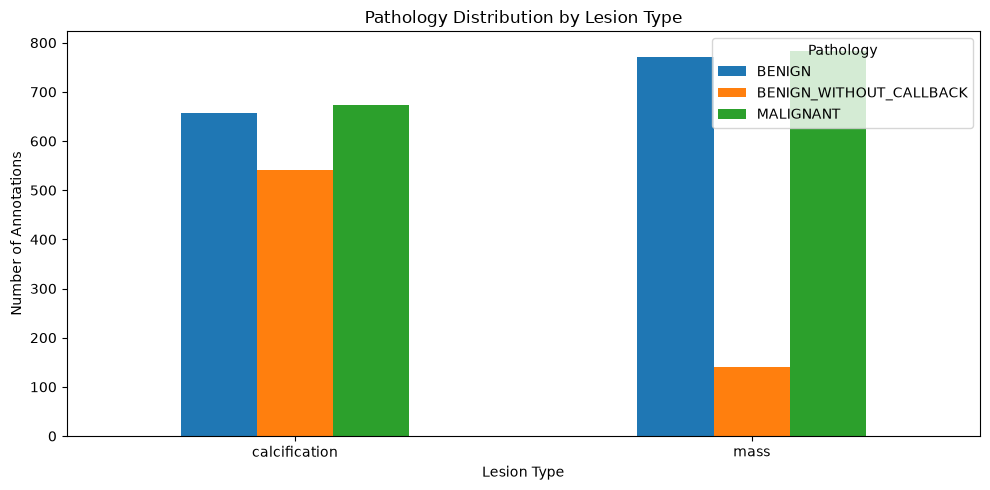

In [14]:
# 6. BIỂU ĐỒ PHÂN BỐ PATHOLOGY

import matplotlib.pyplot as plt

pathology_plot_df = (
    pathology_annotation_summary_df
    .pivot(
        index="lesion_type",
        columns="pathology_label",
        values="so_annotation",
    )
    .fillna(0)
)

ax = pathology_plot_df.plot(
    kind="bar",
    figsize=(10, 5),
)

ax.set_title("Pathology Distribution by Lesion Type")
ax.set_xlabel("Lesion Type")
ax.set_ylabel("Number of Annotations")
ax.tick_params(axis="x", rotation=0)

plt.legend(title="Pathology")
plt.tight_layout()
plt.show()

In [15]:
# 7. KẾT LUẬN PHẦN 04.3

print("=" * 65)
print("KẾT LUẬN PHẦN 04.3")
print("=" * 65)

print("Tổng số annotation:", len(pathology_eda_df))

print(
    "Tổng số candidate:",
    candidate_pathology_eda_df["lesion_candidate_id"].nunique()
)

print(
    "Số candidate có pathology bất nhất:",
    len(pathology_exception_df)
)

print("\nPhân bố pathology theo annotation:")
display(pathology_annotation_summary_df)

print("\nPhân bố pathology theo candidate:")
display(candidate_pathology_summary_df)

print("\nTình trạng thiếu descriptor:")
display(nb04_descriptor_missing_df)

KẾT LUẬN PHẦN 04.3
Tổng số annotation: 3568
Tổng số candidate: 1989
Số candidate có pathology bất nhất: 2

Phân bố pathology theo annotation:


,lesion_type,pathology_label,so_annotation,so_patient,ty_le_pct
0,calcification,BENIGN,658,328,35.15
1,calcification,BENIGN_WITHOUT_CALLBACK,541,99,28.90
2,calcification,MALIGNANT,673,343,35.95
3,mass,BENIGN,771,405,45.46
4,mass,BENIGN_WITHOUT_CALLBACK,141,74,8.31
5,mass,MALIGNANT,784,431,46.23



Phân bố pathology theo candidate:


,candidate_status,_pathology,so_candidate
0,Cap_CC_MLO_can_ra_soat,BENIGN,15
1,Cap_CC_MLO_can_ra_soat,BENIGN_WITHOUT_CALLBACK,77
2,Cap_CC_MLO_can_ra_soat,CHUA_CO_CONSENSUS,2
3,Cap_CC_MLO_can_ra_soat,MALIGNANT,12
4,Cap_CC_MLO_nhat_quan,BENIGN,418
5,Cap_CC_MLO_nhat_quan,BENIGN_WITHOUT_CALLBACK,12
6,Cap_CC_MLO_nhat_quan,MALIGNANT,420
7,Ung_vien_don_annotation,BENIGN,467
8,Ung_vien_don_annotation,BENIGN_WITHOUT_CALLBACK,106
9,Ung_vien_don_annotation,MALIGNANT,460



Tình trạng thiếu descriptor:


,lesion_type,descriptor,so_annotation,so_thieu,ty_le_thieu_pct,so_gia_tri_khac_nhau
0,mass,assessment,1696,0,0.00,6
1,mass,subtlety,1696,0,0.00,6
2,mass,mass_shape,1696,4,0.24,20
3,mass,mass_margins,1696,60,3.54,19
4,calcification,assessment,1872,0,0.00,5
5,calcification,subtlety,1872,0,0.00,5
6,calcification,calc_type,1872,24,1.28,47
7,calcification,calc_distribution,1872,439,23.45,9


### 04.4 — Khảo sát đặc điểm ảnh

**Mục tiêu:** Phân tích kích thước ảnh X-quang tuyến vú và khảo sát mối liên hệ giữa kích thước ảnh với loại tổn thương, bên vú và góc chụp.

**Nội dung thực hiện:**
- Khảo sát kích thước Full Image thông qua Rows và Columns.
- Thống kê kích thước ảnh theo số đường dẫn ảnh duy nhất.
- Phân tích kích thước ảnh theo Mass, Calcification và góc chụp CC/MLO.
- Kiểm tra tính nhất quán kích thước của các annotation cùng tham chiếu một ảnh.
- Khảo sát phân bố các độ phân giải ảnh.

**Dữ liệu đầu vào:**
- Annotation Mapping.
- Image Mapping.
- ROI Mapping.
- Kích thước Full Image đã được trích xuất từ DICOM header ở Notebook 02.

In [16]:
#  4.4.1 — Chuẩn bị dữ liệu khảo sát ảnh
#  1. CHUẨN BỊ DỮ LIỆU

required_columns = {
    "annotation": [
        "annotation_id", "patient_id", "lesion_type",
        "laterality", "image_view"
    ],
    "image": [
        "annotation_id", "image_role", "image_path_key"
    ],
    "roi": [
        "annotation_id", "full_image_shape",
        "mask_shape", "mask_quality_status"
    ],
}

for name, columns in required_columns.items():
    df = {
        "annotation": nb04_lesion_annotation_mapping_df,
        "image": nb04_lesion_image_mapping_df,
        "roi": nb04_lesion_roi_mapping_df,
    }[name]

    missing = [c for c in columns if c not in df.columns]

    if missing:
        raise ValueError(f"Bảng {name} thiếu cột: {missing}")


# 2. LẤY LIÊN KẾT FULL IMAGE

full_image_links_df = (
    nb04_lesion_image_mapping_df.loc[
        nb04_lesion_image_mapping_df["image_role"].eq("full_image"),
        ["annotation_id", "image_path_key"]
    ].copy()
)

if full_image_links_df["annotation_id"].duplicated().any():
    raise ValueError("Một annotation có nhiều liên kết Full Image.")


# 3. GHÉP THÔNG TIN

image_dimension_eda_df = (
    nb04_lesion_roi_mapping_df[
        [
            "annotation_id",
            "full_image_shape",
            "mask_shape",
            "mask_quality_status",
        ]
    ]
    .merge(
        full_image_links_df,
        on="annotation_id",
        validate="one_to_one",
    )
    .merge(
        nb04_lesion_annotation_mapping_df[
            [
                "annotation_id",
                "patient_id",
                "lesion_type",
                "laterality",
                "image_view",
            ]
        ],
        on="annotation_id",
        validate="one_to_one",
    )
)

print("[ĐẠT] Đã liên kết thông tin kích thước ảnh.")
print("Số annotation:", f"{len(image_dimension_eda_df):,}")

display(image_dimension_eda_df.head())

[ĐẠT] Đã liên kết thông tin kích thước ảnh.
Số annotation: 3,568


,annotation_id,full_image_shape,mask_shape,mask_quality_status,image_path_key,patient_id,lesion_type,laterality,image_view
0,calc_train__00001,"(5056, 2761)","(5056, 2761)",structurally_valid,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...,P_00005,calcification,RIGHT,CC
1,calc_train__00002,"(5386, 2836)","(5386, 2836)",structurally_valid,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...,P_00005,calcification,RIGHT,MLO
2,calc_train__00003,"(5356, 2986)","(5356, 2986)",structurally_valid,Calc-Training_P_00007_LEFT_CC/1.3.6.1.4.1.9590...,P_00007,calcification,LEFT,CC
3,calc_train__00004,"(5491, 3166)","(5491, 3166)",structurally_valid,Calc-Training_P_00007_LEFT_MLO/1.3.6.1.4.1.959...,P_00007,calcification,LEFT,MLO
4,calc_train__00005,"(4568, 3064)","(4568, 3064)",structurally_valid,Calc-Training_P_00008_LEFT_CC/1.3.6.1.4.1.9590...,P_00008,calcification,LEFT,CC


In [17]:
# 4.4.2 — Trích xuất Rows và Columns
# 4. CHUẨN HÓA THÔNG TIN KÍCH THƯỚC

import ast
import numpy as np


def parse_image_shape(value):

    try:
        if isinstance(value, str):
            value = ast.literal_eval(value.strip())

        if isinstance(value, np.ndarray):
            value = value.tolist()

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            rows, columns = int(value[0]), int(value[1])

            if rows > 0 and columns > 0:
                return rows, columns

    except (ValueError, TypeError, SyntaxError, IndexError):
        pass

    return pd.NA, pd.NA


parsed_shapes = image_dimension_eda_df[
    "full_image_shape"
].apply(parse_image_shape)

image_dimension_eda_df[
    ["Rows", "Columns"]
] = pd.DataFrame(
    parsed_shapes.tolist(),
    index=image_dimension_eda_df.index,
)

shape_missing_count = int(
    image_dimension_eda_df[["Rows", "Columns"]]
    .isna()
    .any(axis=1)
    .sum()
)

print("Số annotation không phân tích được kích thước:", shape_missing_count)

display(
    image_dimension_eda_df[
        [
            "annotation_id",
            "image_path_key",
            "full_image_shape",
            "Rows",
            "Columns",
        ]
    ].head()
)

# 5. KIỂM TRA KÍCH THƯỚC THEO ĐƯỜNG DẪN ẢNH

full_image_path_audit_df = (
    image_dimension_eda_df
    .groupby("image_path_key", dropna=False)
    .agg(
        so_annotation=("annotation_id", "nunique"),
        so_gia_tri_rows=("Rows", "nunique"),
        so_gia_tri_columns=("Columns", "nunique"),
    )
    .reset_index()
)

full_image_shape_conflicts_df = (
    full_image_path_audit_df.loc[
        (full_image_path_audit_df["so_gia_tri_rows"] > 1)
        | (full_image_path_audit_df["so_gia_tri_columns"] > 1)
    ]
    .copy()
)

shared_full_image_df = (
    full_image_path_audit_df.loc[
        full_image_path_audit_df["so_annotation"] > 1
    ]
    .copy()
)

print("Số đường dẫn Full Image:", len(full_image_path_audit_df))
print("Số đường dẫn được nhiều annotation sử dụng:", len(shared_full_image_df))
print("Số đường dẫn có kích thước không nhất quán:", len(full_image_shape_conflicts_df))

display(full_image_shape_conflicts_df.head(20))

Số annotation không phân tích được kích thước: 0


,annotation_id,image_path_key,full_image_shape,Rows,Columns
0,calc_train__00001,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...,"(5056, 2761)",5056,2761
1,calc_train__00002,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...,"(5386, 2836)",5386,2836
2,calc_train__00003,Calc-Training_P_00007_LEFT_CC/1.3.6.1.4.1.9590...,"(5356, 2986)",5356,2986
3,calc_train__00004,Calc-Training_P_00007_LEFT_MLO/1.3.6.1.4.1.959...,"(5491, 3166)",5491,3166
4,calc_train__00005,Calc-Training_P_00008_LEFT_CC/1.3.6.1.4.1.9590...,"(4568, 3064)",4568,3064


Số đường dẫn Full Image: 3103
Số đường dẫn được nhiều annotation sử dụng: 293
Số đường dẫn có kích thước không nhất quán: 0


,image_path_key,so_annotation,so_gia_tri_rows,so_gia_tri_columns


In [18]:
# 6. THỐNG KÊ KÍCH THƯỚC FULL IMAGE

valid_dimension_mask = (
    image_dimension_eda_df["Rows"].notna()
    & image_dimension_eda_df["Columns"].notna()
    & image_dimension_eda_df["image_path_key"].notna()
)

unique_full_image_df = (
    image_dimension_eda_df.loc[valid_dimension_mask]
    .sort_values("annotation_id")
    .drop_duplicates("image_path_key")
    .copy()
)

image_dimension_summary_df = (
    unique_full_image_df[["Rows", "Columns"]]
    .agg(["count", "min", "median", "mean", "max"])
    .round(2)
    .rename_axis("thong_ke")
)

print("Số Full Image có kích thước hợp lệ:", len(unique_full_image_df))
display(image_dimension_summary_df)


# 7. PHÂN BỐ ĐỘ PHÂN GIẢI ẢNH

unique_full_image_df["resolution"] = (
    unique_full_image_df["Rows"].astype(int).astype(str)
    + " x "
    + unique_full_image_df["Columns"].astype(int).astype(str)
)

nb04_resolution_summary_df = (
    unique_full_image_df["resolution"]
    .value_counts()
    .rename_axis("resolution")
    .reset_index(name="so_image")
)

display(nb04_resolution_summary_df.head(20))

Số Full Image có kích thước hợp lệ: 3103


,Rows,Columns
thong_ke,,
count,3103.00,3103.00
min,3256.00,1531.00
median,5221.00,3008.00
mean,5247.01,3106.91
max,7111.00,5431.00


,resolution,so_image
0,5491 x 2926,9
1,5491 x 2911,9
2,5491 x 2776,8
3,5491 x 2671,7
4,5491 x 2941,6
5,5491 x 2971,6
6,5491 x 2836,5
7,5491 x 2761,5
8,5491 x 2806,5
9,5491 x 3121,5


In [19]:
# 8. KÍCH THƯỚC ẢNH THEO LOẠI TỔN THƯƠNG VÀ GÓC CHỤP

group_columns = [
    "lesion_type",
    "image_view",
    "laterality",
]

# 1. KIỂM TRA CỘT ĐẦU VÀO

required_columns = [
    "annotation_id",
    "patient_id",
    "lesion_type",
    "image_view",
    "laterality",
    "image_path_key",
    "Rows",
    "Columns",
]

missing_columns = [
    col for col in required_columns
    if col not in image_dimension_eda_df.columns
]

if missing_columns:
    raise ValueError(f"Thiếu cột dữ liệu: {missing_columns}")

# 2. CHUẨN BỊ DỮ LIỆU

dimension_df = image_dimension_eda_df.copy()
dimension_df["image_path_key"] = (
    dimension_df["image_path_key"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

dimension_df["Rows"] = pd.to_numeric(
    dimension_df["Rows"],
    errors="coerce",
)

dimension_df["Columns"] = pd.to_numeric(
    dimension_df["Columns"],
    errors="coerce",
)

# 3. KIỂM TRA DỮ LIỆU BẤT THƯỜNG

duplicate_annotation_df = dimension_df.loc[
    dimension_df["annotation_id"].duplicated(keep=False)
].copy()

missing_path_df = dimension_df.loc[
    dimension_df["image_path_key"].isna()
].copy()

invalid_dimension_df = dimension_df.loc[
    dimension_df[["Rows", "Columns"]].isna().any(axis=1)
    | dimension_df["Rows"].le(0)
    | dimension_df["Columns"].le(0)
].copy()


# Kiểm tra một đường dẫn ảnh có nhiều kích thước khác nhau hay không.

path_dimension_audit_df = (
    dimension_df
    .dropna(subset=["image_path_key"])
    .groupby("image_path_key")
    .agg(
        so_annotation=("annotation_id", "nunique"),
        so_gia_tri_rows=("Rows", "nunique"),
        so_gia_tri_columns=("Columns", "nunique"),
    )
    .reset_index()
)

full_image_shape_conflicts_df = (
    path_dimension_audit_df.loc[
        (path_dimension_audit_df["so_gia_tri_rows"] > 1)
        | (path_dimension_audit_df["so_gia_tri_columns"] > 1)
    ].copy()
)


print("KIỂM TRA DỮ LIỆU KÍCH THƯỚC ẢNH")

print("Annotation ID bị trùng:",
      len(duplicate_annotation_df))

print("Đường dẫn ảnh bị thiếu:",
      len(missing_path_df))

print("Kích thước ảnh không hợp lệ:",
      len(invalid_dimension_df))

print("Đường dẫn có kích thước không nhất quán:",
      len(full_image_shape_conflicts_df))


# Hiển thị các trường hợp bất thường nếu có.

if not duplicate_annotation_df.empty:
    display(duplicate_annotation_df.head(20))
if not missing_path_df.empty:
    display(missing_path_df.head(20))
if not invalid_dimension_df.empty:
    display(invalid_dimension_df.head(20))
if not full_image_shape_conflicts_df.empty:
    display(full_image_shape_conflicts_df.head(20))

# Không tiếp tục tính thống kê nếu dữ liệu có vấn đề.

if (
    not duplicate_annotation_df.empty
    or not missing_path_df.empty
    or not invalid_dimension_df.empty
    or not full_image_shape_conflicts_df.empty
):
    raise ValueError(
        "Dữ liệu kích thước ảnh có trường hợp bất thường. "
        "Cần kiểm tra trước khi tính thống kê."
    )

print("\n[ĐẠT] Dữ liệu kích thước ảnh nhất quán.")


# 4. THỐNG KÊ Ở CẤP ANNOTATION

annotation_group_summary_df = (
    dimension_df
    .groupby(
        group_columns,
        dropna=False,
    )
    .agg(
        so_annotation=("annotation_id", "nunique"),
        so_patient=("patient_id", "nunique"),
    )
    .reset_index()
)

# 5. TẠO BẢNG Ở CẤP FULL IMAGE DUY NHẤT
image_level_group_df = (
    dimension_df
    .sort_values("annotation_id")
    .drop_duplicates(
        subset=group_columns + ["image_path_key"]
    )
    .copy()
)

# 6. THỐNG KÊ KÍCH THƯỚC TRÊN ẢNH DUY NHẤT
image_dimension_group_summary_df = (
    image_level_group_df
    .groupby(
        group_columns,
        dropna=False,
    )
    .agg(
        so_full_image=("image_path_key", "nunique"),
        Rows_min=("Rows", "min"),
        Rows_median=("Rows", "median"),
        Rows_max=("Rows", "max"),
        Columns_min=("Columns", "min"),
        Columns_median=("Columns", "median"),
        Columns_max=("Columns", "max"),
    )
    .reset_index()
)

# 7. KẾT HỢP KẾT QUẢ
nb04_dimension_by_group_df = (
    annotation_group_summary_df
    .merge(
        image_dimension_group_summary_df,
        on=group_columns,
        how="left",
        validate="one_to_one",
    )
    .sort_values(group_columns)
    .reset_index(drop=True)
)

# 8. HIỂN THỊ KẾT QUẢ

print("\nPHÂN BỐ KÍCH THƯỚC ẢNH THEO NHÓM")
display(nb04_dimension_by_group_df)
print("\nTỔNG SỐ ANNOTATION:",
      dimension_df["annotation_id"].nunique())

print("TỔNG SỐ FULL IMAGE DUY NHẤT:",
      dimension_df["image_path_key"].nunique())

KIỂM TRA DỮ LIỆU KÍCH THƯỚC ẢNH
Annotation ID bị trùng: 0
Đường dẫn ảnh bị thiếu: 0
Kích thước ảnh không hợp lệ: 0
Đường dẫn có kích thước không nhất quán: 0

[ĐẠT] Dữ liệu kích thước ảnh nhất quán.

PHÂN BỐ KÍCH THƯỚC ẢNH THEO NHÓM


,lesion_type,image_view,laterality,so_annotation,so_patient,so_full_image,Rows_min,Rows_median,Rows_max,Columns_min,Columns_median,Columns_max
0,calcification,CC,LEFT,478,395,395,3721,5071.0,6871,1531,2992.0,4951
1,calcification,CC,RIGHT,410,322,322,3256,4793.0,6841,1546,3024.0,4891
2,calcification,MLO,LEFT,524,427,427,3880,5341.0,7111,1861,3024.0,5251
3,calcification,MLO,RIGHT,460,367,367,3944,5251.0,7021,1816,3016.0,4966
4,mass,CC,LEFT,384,365,365,4006,5168.0,6871,1846,3008.0,4816
5,mass,CC,RIGHT,400,378,378,3920,5176.0,6916,1786,2952.0,5386
6,mass,MLO,LEFT,433,405,405,4280,5386.0,6871,2011,3061.0,5431
7,mass,MLO,RIGHT,479,444,444,4144,5281.0,6931,2131,2993.0,4501



TỔNG SỐ ANNOTATION: 3568
TỔNG SỐ FULL IMAGE DUY NHẤT: 3103


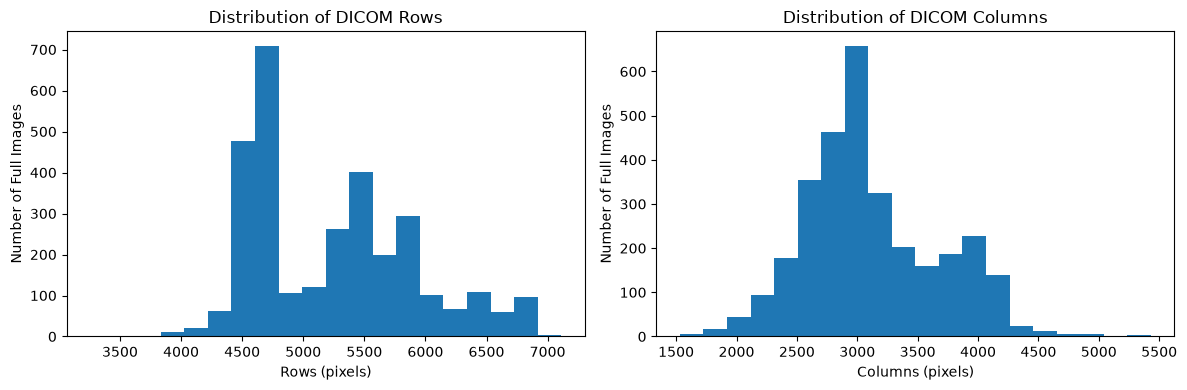

In [20]:
# 9. BIỂU ĐỒ PHÂN BỐ KÍCH THƯỚC ẢNH

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    unique_full_image_df["Rows"],
    bins=20,
)

axes[0].set_title("Distribution of DICOM Rows")
axes[0].set_xlabel("Rows (pixels)")
axes[0].set_ylabel("Number of Full Images")

axes[1].hist(
    unique_full_image_df["Columns"],
    bins=20,
)

axes[1].set_title("Distribution of DICOM Columns")
axes[1].set_xlabel("Columns (pixels)")
axes[1].set_ylabel("Number of Full Images")

plt.tight_layout()
plt.show()

### Kết luận phần 04.4

Kết quả khảo sát kích thước ảnh Full Image cho thấy:

- Toàn bộ 3.568 annotation đều liên kết được với thông tin kích thước ảnh.
- Có 3.103 đường dẫn Full Image duy nhất.
- Không phát hiện annotation ID trùng, đường dẫn ảnh thiếu hoặc kích thước ảnh không hợp lệ.
- Không phát hiện trường hợp cùng một đường dẫn ảnh có nhiều giá trị Rows hoặc Columns khác nhau.
- Kích thước ảnh có sự biến thiên đáng kể giữa các ảnh.
- Trong các nhóm khảo sát, Rows median của ảnh MLO cao hơn ảnh CC.
- Columns median ít biến động hơn Rows giữa các nhóm.

**Nhận định:** Dữ liệu Full Image có tính đa dạng về độ phân giải. Đây là yếu tố cần được xem xét khi thiết kế quy trình tiền xử lý ảnh và lựa chọn kích thước đầu vào cho mô hình học sâu.

### 04.5 — Khảo sát ROI Mask và hình học tổn thương

**Mục tiêu:** Khảo sát đặc điểm cấu trúc, diện tích và hình học của ROI Mask trong CBIS-DDSM, đánh giá khả năng khai thác mask và bounding box cho bài toán định vị tổn thương.

**Nội dung thực hiện:**
- Thống kê chất lượng và kích thước ROI Mask.
- Phân tích số pixel foreground và tỷ lệ diện tích mask.
- Khảo sát số lượng connected components.
- Phân tích Bounding Box: tọa độ, chiều rộng, chiều cao và diện tích.
- So sánh các đặc điểm ROI giữa Mass và Calcification.
- Đánh giá các trường hợp sai khác kích thước và giới hạn về hệ tọa độ.

In [21]:
#  4.5.1 — Chuẩn bị dữ liệu ROI
#  1. CHUẨN BỊ DỮ LIỆU ROI

import ast
roi_eda_df = nb04_lesion_roi_mapping_df.copy()

# Bổ sung lesion_type từ Annotation Mapping nếu chưa có.
if "lesion_type" not in roi_eda_df.columns:

    annotation_type_df = (
        nb04_lesion_annotation_mapping_df[
            ["annotation_id", "lesion_type"]
        ].copy()
    )

    roi_eda_df = roi_eda_df.merge(
        annotation_type_df,
        on="annotation_id",
        how="left",
        validate="one_to_one",
    )

required_columns = [
    "annotation_id",
    "lesion_type",
    "mask_shape",
    "full_image_shape",
    "mask_quality_status",
    "mask_read_status",
    "is_empty",
    "nonzero_pixel_count",
    "mask_area_ratio",
    "mask_foreground_fraction",
    "connected_components",
    "bbox_x_min",
    "bbox_y_min",
    "bbox_x_max",
    "bbox_y_max",
    "bbox_coordinate_space",
    "bbox_full_image_coordinate_eligible",
    "spatial_alignment_verified",
]

missing_columns = [
    c for c in required_columns
    if c not in roi_eda_df.columns
]

if missing_columns:
    raise ValueError(f"ROI Mapping thiếu cột: {missing_columns}")

if roi_eda_df["annotation_id"].duplicated().any():
    raise ValueError("Annotation ID bị trùng trong ROI Mapping.")

print("[ĐẠT] Đã chuẩn bị dữ liệu ROI.")
print("Số annotation:", f"{len(roi_eda_df):,}")

display(roi_eda_df.head())

[ĐẠT] Đã chuẩn bị dữ liệu ROI.
Số annotation: 3,568


,patient_id,breast_density,laterality,image_view,abnormality_id,abnormality_type,calc_type,calc_distribution,assessment,pathology,...,mask_quality_status,error_message,mask_foreground_fraction,mask_values_binary,bbox_coordinate_space,bbox_full_image_coordinate_eligible,coordinate_note,_roi_merge_status,roi_mapping_status,spatial_alignment_verified
0,P_00005,3,RIGHT,CC,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,...,structurally_valid,NaN,0.020246,True,roi_mask_pixel_coordinates,True,Same matrix shape; spatial alignment still req...,both,ROI_hop_le_ve_cau_truc,False
1,P_00005,3,RIGHT,MLO,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,...,structurally_valid,NaN,0.015563,True,roi_mask_pixel_coordinates,True,Same matrix shape; spatial alignment still req...,both,ROI_hop_le_ve_cau_truc,False
2,P_00007,4,LEFT,CC,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,...,structurally_valid,NaN,0.016234,True,roi_mask_pixel_coordinates,True,Same matrix shape; spatial alignment still req...,both,ROI_hop_le_ve_cau_truc,False
3,P_00007,4,LEFT,MLO,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,...,structurally_valid,NaN,0.019921,True,roi_mask_pixel_coordinates,True,Same matrix shape; spatial alignment still req...,both,ROI_hop_le_ve_cau_truc,False
4,P_00008,1,LEFT,CC,1,calcification,NaN,REGIONAL,2,BENIGN_WITHOUT_CALLBACK,...,structurally_valid,NaN,0.000753,True,roi_mask_pixel_coordinates,True,Same matrix shape; spatial alignment still req...,both,ROI_hop_le_ve_cau_truc,False


In [22]:
# 2. PHÂN TÍCH KÍCH THƯỚC ROI MASK

def parse_shape(value):
    try:
        if value is None or pd.isna(value):
            return pd.NA, pd.NA

        if isinstance(value, str):
            value = ast.literal_eval(value.strip())

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            rows, cols = int(value[0]), int(value[1])

            if rows > 0 and cols > 0:
                return rows, cols

    except (ValueError, TypeError, SyntaxError):
        pass

    return pd.NA, pd.NA


mask_dimensions = roi_eda_df["mask_shape"].apply(parse_shape)
full_dimensions = roi_eda_df["full_image_shape"].apply(parse_shape)

roi_eda_df[["mask_rows", "mask_columns"]] = pd.DataFrame(
    mask_dimensions.tolist(),
    index=roi_eda_df.index,
)

roi_eda_df[["full_rows", "full_columns"]] = pd.DataFrame(
    full_dimensions.tolist(),
    index=roi_eda_df.index,
)

roi_eda_df["mask_pixels"] = (
    roi_eda_df["mask_rows"]
    * roi_eda_df["mask_columns"]
)

shape_missing_count = int(
    roi_eda_df[
        ["mask_rows", "mask_columns", "full_rows", "full_columns"]
    ].isna().any(axis=1).sum()
)

roi_eda_df["shape_match_recomputed"] = (
    roi_eda_df["mask_rows"].eq(roi_eda_df["full_rows"])
    & roi_eda_df["mask_columns"].eq(roi_eda_df["full_columns"])
)

print("Số annotation không phân tích được shape:", shape_missing_count)

display(
    roi_eda_df[
        [
            "annotation_id",
            "lesion_type",
            "mask_shape",
            "full_image_shape",
            "mask_rows",
            "mask_columns",
            "shape_match_recomputed",
        ]
    ].head()
)

Số annotation không phân tích được shape: 0


,annotation_id,lesion_type,mask_shape,full_image_shape,mask_rows,mask_columns,shape_match_recomputed
0,calc_train__00001,calcification,"(5056, 2761)","(5056, 2761)",5056,2761,True
1,calc_train__00002,calcification,"(5386, 2836)","(5386, 2836)",5386,2836,True
2,calc_train__00003,calcification,"(5356, 2986)","(5356, 2986)",5356,2986,True
3,calc_train__00004,calcification,"(5491, 3166)","(5491, 3166)",5491,3166,True
4,calc_train__00005,calcification,"(4568, 3064)","(4568, 3064)",4568,3064,True


In [23]:
# 3. TỔNG HỢP CHẤT LƯỢNG ROI MASK

def parse_bool(series):
    return (
        series.astype("string")
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False,
        })
    )

roi_eda_df["is_empty_bool"] = parse_bool(
    roi_eda_df["is_empty"]
)

roi_eda_df["mask_binary_bool"] = parse_bool(
    roi_eda_df["mask_values_binary"]
)

roi_eda_df["bbox_eligible_bool"] = parse_bool(
    roi_eda_df["bbox_full_image_coordinate_eligible"]
)

roi_eda_df["spatial_alignment_bool"] = parse_bool(
    roi_eda_df["spatial_alignment_verified"]
)

# Phân bố trạng thái mask.

roi_quality_summary_df = (
    roi_eda_df
    .groupby(
        ["lesion_type", "mask_quality_status"],
        dropna=False,
    )
    .agg(
        so_annotation=("annotation_id", "nunique"),
    )
    .reset_index()
)

display(roi_quality_summary_df)


# Kiểm tra các tiêu chí cơ bản.

print("ROI mask rỗng:", int(roi_eda_df["is_empty_bool"].eq(True).sum()))

print(
    "ROI mask không nhị phân:",
    int(roi_eda_df["mask_binary_bool"].eq(False).sum()),)

print(
    "ROI mask thiếu trạng thái kiểm tra:",
    int(roi_eda_df["mask_read_status"].isna().sum()),)

print(
    "ROI chưa xác minh spatial alignment:",
    int(roi_eda_df["spatial_alignment_bool"].ne(True).sum()),)

,lesion_type,mask_quality_status,so_annotation
0,calcification,shape_mismatch,2
1,calcification,structurally_valid,1870
2,mass,shape_mismatch,78
3,mass,structurally_valid,1618


ROI mask rỗng: 0
ROI mask không nhị phân: 0
ROI mask thiếu trạng thái kiểm tra: 0
ROI chưa xác minh spatial alignment: 3568


In [24]:
# 4. PHÂN TÍCH DIỆN TÍCH VÀ FOREGROUND

numeric_columns = [
    "nonzero_pixel_count",
    "mask_area_ratio",
    "mask_foreground_fraction",
    "connected_components",
]

for col in numeric_columns:
    roi_eda_df[col] = pd.to_numeric(
        roi_eda_df[col],
        errors="coerce",
    )

# Tính lại foreground fraction từ số pixel.

roi_eda_df["calculated_foreground_fraction"] = (
    roi_eda_df["nonzero_pixel_count"]
    / roi_eda_df["mask_pixels"]
)

# So sánh với giá trị đã lưu.

fraction_valid = (
    roi_eda_df["calculated_foreground_fraction"].notna()
    & roi_eda_df["mask_foreground_fraction"].notna()
)

fraction_match = np.isclose(
    roi_eda_df.loc[fraction_valid, "calculated_foreground_fraction"],
    roi_eda_df.loc[fraction_valid, "mask_foreground_fraction"],
    rtol=1e-5,
    atol=1e-8,
)

print("Số trường hợp đối chiếu foreground fraction:", int(fraction_valid.sum()))
print("Số trường hợp không khớp:", int((~fraction_match).sum()))

# Thống kê theo loại tổn thương và chất lượng mask.

roi_area_summary_df = (
    roi_eda_df
    .groupby(
        ["lesion_type", "mask_quality_status"],
        dropna=False,
    )
    .agg(
        so_annotation=("annotation_id", "nunique"),
        nonzero_pixels_median=("nonzero_pixel_count", "median"),
        nonzero_pixels_mean=("nonzero_pixel_count", "mean"),
        mask_area_ratio_median=("mask_area_ratio", "median"),
        foreground_fraction_median=("mask_foreground_fraction", "median"),
        connected_components_median=("connected_components", "median"),
    )
    .round(6)
    .reset_index()
)

display(roi_area_summary_df)

Số trường hợp đối chiếu foreground fraction: 3568
Số trường hợp không khớp: 0


,lesion_type,mask_quality_status,so_annotation,nonzero_pixels_median,nonzero_pixels_mean,mask_area_ratio_median,foreground_fraction_median,connected_components_median
0,calcification,shape_mismatch,2,24453.0,24453.000000,NaN,0.001704,1.0
1,calcification,structurally_valid,1870,58095.5,213054.831551,0.003695,0.003695,1.0
2,mass,shape_mismatch,78,50193.0,60373.371795,NaN,0.004089,5.0
3,mass,structurally_valid,1618,57545.5,80070.041409,0.003551,0.003551,11.0


In [25]:
# 5. PHÂN TÍCH BOUNDING BOX

bbox_columns = [
    "bbox_x_min",
    "bbox_y_min",
    "bbox_x_max",
    "bbox_y_max",
]

for col in bbox_columns:
    roi_eda_df[col] = pd.to_numeric(
        roi_eda_df[col],
        errors="coerce",
    )


bbox_missing_mask = roi_eda_df[bbox_columns].isna().any(axis=1)

bbox_invalid_mask = (
    (roi_eda_df["bbox_x_max"] < roi_eda_df["bbox_x_min"])
    | (roi_eda_df["bbox_y_max"] < roi_eda_df["bbox_y_min"])
)

bbox_valid_mask = (
    ~bbox_missing_mask
    & ~bbox_invalid_mask
)

roi_eda_df["bbox_width"] = np.where(
    bbox_valid_mask,
    roi_eda_df["bbox_x_max"] - roi_eda_df["bbox_x_min"] + 1,
    np.nan,
)

roi_eda_df["bbox_height"] = np.where(
    bbox_valid_mask,
    roi_eda_df["bbox_y_max"] - roi_eda_df["bbox_y_min"] + 1,
    np.nan,
)

roi_eda_df["bbox_area"] = (
    roi_eda_df["bbox_width"]
    * roi_eda_df["bbox_height"]
)

print("BBox thiếu tọa độ:", int(bbox_missing_mask.sum()))
print("BBox có tọa độ không hợp lệ:", int(bbox_invalid_mask.sum()))
print("BBox có thể tính hình học:", int(bbox_valid_mask.sum()))

# Phân bố hệ tọa độ bbox.

bbox_coordinate_summary_df = (
    roi_eda_df["bbox_coordinate_space"]
    .value_counts(dropna=False)
    .rename_axis("bbox_coordinate_space")
    .reset_index(name="so_annotation")
)

display(bbox_coordinate_summary_df)

# Thống kê kích thước bbox.

bbox_geometry_summary_df = (
    roi_eda_df.loc[bbox_valid_mask]
    .groupby(
        ["lesion_type", "mask_quality_status"],
        dropna=False,
    )
    .agg(
        so_annotation=("annotation_id", "nunique"),
        bbox_width_median=("bbox_width", "median"),
        bbox_height_median=("bbox_height", "median"),
        bbox_area_median=("bbox_area", "median"),
        bbox_width_max=("bbox_width", "max"),
        bbox_height_max=("bbox_height", "max"),
    )
    .round(2)
    .reset_index())

display(bbox_geometry_summary_df)

# Phân biệt điều kiện kích thước và xác minh căn chỉnh không gian.

bbox_alignment_summary_df = (
    roi_eda_df
    .groupby("mask_quality_status")
    .agg(
        so_annotation=("annotation_id", "nunique"),
        bbox_full_image_eligible=("bbox_eligible_bool", lambda x: x.eq(True).sum()),
        spatial_alignment_verified=("spatial_alignment_bool", lambda x: x.eq(True).sum()),
    )
    .reset_index())

display(bbox_alignment_summary_df)

BBox thiếu tọa độ: 0
BBox có tọa độ không hợp lệ: 0
BBox có thể tính hình học: 3568


,bbox_coordinate_space,so_annotation
0,roi_mask_pixel_coordinates,3568


,lesion_type,mask_quality_status,so_annotation,bbox_width_median,bbox_height_median,bbox_area_median,bbox_width_max,bbox_height_max
0,calcification,shape_mismatch,2,174.0,194.0,33564.0,186.0,210.0
1,calcification,structurally_valid,1870,290.0,274.0,81033.0,2874.0,3802.0
2,mass,shape_mismatch,78,300.5,275.5,83788.0,695.0,897.0
3,mass,structurally_valid,1618,302.0,302.0,91402.5,1366.0,1330.0


,mask_quality_status,so_annotation,bbox_full_image_eligible,spatial_alignment_verified
0,shape_mismatch,80,0,0
1,structurally_valid,3488,3488,0


<Figure size 640x480 with 0 Axes>

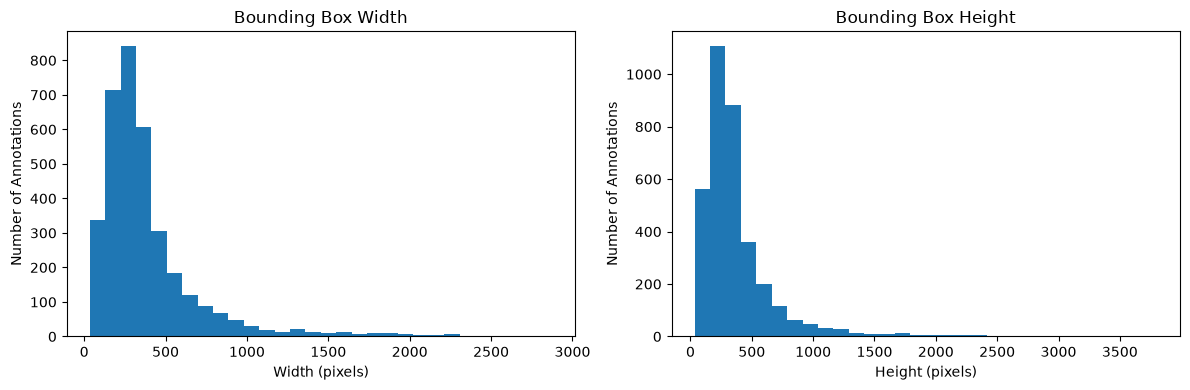

In [26]:
# 6. TRỰC QUAN HÓA ROI MASK

valid_roi_df = roi_eda_df.loc[
    roi_eda_df["mask_quality_status"].eq("structurally_valid")
].copy()


for lesion_type, subset in valid_roi_df.groupby("lesion_type"):

    axes[0].hist(
        subset["mask_foreground_fraction"].dropna(),
        bins=30,
        alpha=0.6,
        label=lesion_type,
    )

    axes[1].hist(
        subset["connected_components"].dropna(),
        bins=20,
        alpha=0.6,
        label=lesion_type,
    )

axes[0].set_title("ROI Mask Foreground Fraction")
axes[0].set_xlabel("Foreground Fraction")
axes[0].set_ylabel("Number of Annotations")
axes[0].legend()
axes[1].set_title("ROI Mask Connected Components")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Number of Annotations")
axes[1].legend()
plt.tight_layout()
plt.show()

# Biểu đồ phân bố chiều rộng và chiều cao bbox.

valid_bbox_df = roi_eda_df.loc[
    bbox_valid_mask
    & roi_eda_df["mask_quality_status"].eq("structurally_valid")
].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(
    valid_bbox_df["bbox_width"].dropna(),
    bins=30,
)

axes[0].set_title("Bounding Box Width")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Number of Annotations")

axes[1].hist(
    valid_bbox_df["bbox_height"].dropna(),
    bins=30,
)
axes[1].set_title("Bounding Box Height")
axes[1].set_xlabel("Height (pixels)")
axes[1].set_ylabel("Number of Annotations")
plt.tight_layout()
plt.show()

In [27]:
# 7. KẾT LUẬN PHẦN 04.5

print("=" * 65)
print("KẾT LUẬN PHẦN 04.5")
print("=" * 65)

print("Tổng số ROI:", f"{len(roi_eda_df):,}")
print("\nPhân bố chất lượng mask:")
display(
    roi_eda_df["mask_quality_status"]
    .value_counts(dropna=False)
    .rename_axis("mask_quality_status")
    .reset_index(name="so_annotation")
)

print("\nKích thước ROI Mask:")
display(
    roi_eda_df.groupby("mask_quality_status").agg(
        so_annotation=("annotation_id", "nunique"),
        mask_rows_median=("mask_rows", "median"),
        mask_columns_median=("mask_columns", "median"),
    ).reset_index()
)

print("\nTổng hợp diện tích và foreground:")
display(roi_area_summary_df)
print("\nTổng hợp hình học Bounding Box:")
display(bbox_geometry_summary_df)
print("\nTình trạng xác minh tọa độ:")
display(bbox_alignment_summary_df)
print("\nLưu ý:")
print("- Chưa resize các ROI mask sai khác kích thước.")
print("- Chưa xác minh spatial alignment với Full Image.")
print("- Chưa sử dụng bbox làm ground truth trên Full Image.")

KẾT LUẬN PHẦN 04.5
Tổng số ROI: 3,568

Phân bố chất lượng mask:


,mask_quality_status,so_annotation
0,structurally_valid,3488
1,shape_mismatch,80



Kích thước ROI Mask:


,mask_quality_status,so_annotation,mask_rows_median,mask_columns_median
0,shape_mismatch,80,4621.0,2664.0
1,structurally_valid,3488,5146.0,3040.0



Tổng hợp diện tích và foreground:


,lesion_type,mask_quality_status,so_annotation,nonzero_pixels_median,nonzero_pixels_mean,mask_area_ratio_median,foreground_fraction_median,connected_components_median
0,calcification,shape_mismatch,2,24453.0,24453.000000,NaN,0.001704,1.0
1,calcification,structurally_valid,1870,58095.5,213054.831551,0.003695,0.003695,1.0
2,mass,shape_mismatch,78,50193.0,60373.371795,NaN,0.004089,5.0
3,mass,structurally_valid,1618,57545.5,80070.041409,0.003551,0.003551,11.0



Tổng hợp hình học Bounding Box:


,lesion_type,mask_quality_status,so_annotation,bbox_width_median,bbox_height_median,bbox_area_median,bbox_width_max,bbox_height_max
0,calcification,shape_mismatch,2,174.0,194.0,33564.0,186.0,210.0
1,calcification,structurally_valid,1870,290.0,274.0,81033.0,2874.0,3802.0
2,mass,shape_mismatch,78,300.5,275.5,83788.0,695.0,897.0
3,mass,structurally_valid,1618,302.0,302.0,91402.5,1366.0,1330.0



Tình trạng xác minh tọa độ:


,mask_quality_status,so_annotation,bbox_full_image_eligible,spatial_alignment_verified
0,shape_mismatch,80,0,0
1,structurally_valid,3488,3488,0



Lưu ý:
- Chưa resize các ROI mask sai khác kích thước.
- Chưa xác minh spatial alignment với Full Image.
- Chưa sử dụng bbox làm ground truth trên Full Image.


In [28]:
# 8. KIỂM TRA GIỚI HẠN TỌA ĐỘ BOUNDING BOX

bbox_audit_df = roi_eda_df.copy()

bbox_cols = [
    "bbox_x_min",
    "bbox_y_min",
    "bbox_x_max",
    "bbox_y_max",
    "mask_rows",
    "mask_columns",
]

bbox_audit_df[bbox_cols] = bbox_audit_df[
    bbox_cols
].apply(pd.to_numeric, errors="coerce")

bbox_audit_df["nonzero_pixel_count"] = pd.to_numeric(
    bbox_audit_df["nonzero_pixel_count"],
    errors="coerce",
)

# Kiểm tra tọa độ có đầy đủ hay không.

bbox_known = (
    bbox_audit_df[bbox_cols].notna().all(axis=1)
    & bbox_audit_df["nonzero_pixel_count"].notna()
)

# Kiểm tra tọa độ nằm trong giới hạn ROI Mask.

bbox_out_of_bounds = (
    (bbox_audit_df["bbox_x_min"] < 0)
    | (bbox_audit_df["bbox_y_min"] < 0)
    | (bbox_audit_df["bbox_x_max"] >= bbox_audit_df["mask_columns"])
    | (bbox_audit_df["bbox_y_max"] >= bbox_audit_df["mask_rows"])
)

bbox_invalid_bounds_df = bbox_audit_df.loc[
    bbox_known & bbox_out_of_bounds
].copy()

# Kiểm tra diện tích bbox không nhỏ hơn số pixel foreground.

bbox_area_smaller = (
    bbox_audit_df["bbox_area"]
    < bbox_audit_df["nonzero_pixel_count"]
)

bbox_area_exception_df = bbox_audit_df.loc[
    bbox_known & bbox_area_smaller
].copy()

# Tổng hợp kết quả.

bbox_bounds_summary_df = pd.DataFrame([
    {
        "noi_dung": "BBox có đủ thông tin kiểm tra",
        "so_luong": int(bbox_known.sum()),
    },
    {
        "noi_dung": "BBox nằm ngoài giới hạn ROI Mask",
        "so_luong": len(bbox_invalid_bounds_df),
    },
    {
        "noi_dung": "Diện tích bbox nhỏ hơn foreground pixels",
        "so_luong": len(bbox_area_exception_df),
    },
])

display(bbox_bounds_summary_df)

if not bbox_invalid_bounds_df.empty:
    display(
        bbox_invalid_bounds_df[
            ["annotation_id"] + bbox_cols
        ].head(20)
    )

if not bbox_area_exception_df.empty:
    display(
        bbox_area_exception_df[
            [
                "annotation_id",
                "bbox_area",
                "nonzero_pixel_count",
            ]
        ].head(20)
    )


# Xem 15 Bounding Box có diện tích lớn nhất trong nhóm hợp lệ.

bbox_extreme_df = (
    bbox_audit_df.loc[
        bbox_audit_df["mask_quality_status"].eq("structurally_valid")
    ]
    .nlargest(15, "bbox_area")
    [
        [
            "annotation_id",
            "patient_id",
            "lesion_type",
            "image_view",
            "bbox_width",
            "bbox_height",
            "bbox_area",
            "nonzero_pixel_count",
            "connected_components",
            "mask_foreground_fraction",
        ]
    ]
    .copy()
)

print("\n15 BOUNDING BOX CÓ DIỆN TÍCH LỚN NHẤT")
display(bbox_extreme_df)

if bbox_invalid_bounds_df.empty and bbox_area_exception_df.empty:
    print("\n[ĐẠT] Không phát hiện bbox vượt giới hạn hoặc có diện tích bất hợp lý.")
else:
    print("\n[CẦN RÀ SOÁT] Có trường hợp bbox cần kiểm tra thêm.")

,noi_dung,so_luong
0,BBox có đủ thông tin kiểm tra,3568
1,BBox nằm ngoài giới hạn ROI Mask,35
2,Diện tích bbox nhỏ hơn foreground pixels,0


,annotation_id,bbox_x_min,bbox_y_min,bbox_x_max,bbox_y_max,mask_rows,mask_columns
599,calc_train__00600,2095,3516,2281,3661,5386,2281
768,calc_train__00769,902,1887,1846,3588,4306,1846
1468,calc_train__01469,1549,1598,1981,2283,4831,1981
1739,calc_test__00194,2025,3018,2521,3619,5266,2521
1968,mass_train__00097,2181,1346,2806,2203,5611,2806
1984,mass_train__00113,3365,1223,3784,1878,5864,3784
1996,mass_train__00125,2537,2278,2872,2731,4592,2872
2010,mass_train__00139,3403,2303,3736,2911,5856,3736
2039,mass_train__00168,2207,1385,2568,2020,4712,2568
2074,mass_train__00203,2657,2233,2944,2564,4592,2944



15 BOUNDING BOX CÓ DIỆN TÍCH LỚN NHẤT


,annotation_id,patient_id,lesion_type,image_view,bbox_width,bbox_height,bbox_area,nonzero_pixel_count,connected_components,mask_foreground_fraction
179,calc_train__00180,P_00266,calcification,MLO,2754.0,3778.0,10404612.0,8876129,1,0.403157
1061,calc_train__01062,P_01359,calcification,CC,2874.0,3274.0,9409476.0,7444549,1,0.364360
1062,calc_train__01063,P_01359,calcification,MLO,2834.0,3098.0,8779732.0,7027313,1,0.342318
178,calc_train__00179,P_00266,calcification,CC,2778.0,2994.0,8317332.0,6619385,1,0.308537
558,calc_train__00559,P_00693,calcification,CC,2290.0,2930.0,6709700.0,3965047,1,0.176324
868,calc_train__00869,P_01099,calcification,MLO,1562.0,3802.0,5938724.0,500941,1,0.022538
559,calc_train__00560,P_00693,calcification,MLO,2290.0,2122.0,4859380.0,2824393,1,0.149326
473,calc_train__00474,P_00591,calcification,MLO,1786.0,2362.0,4218532.0,2272809,1,0.117203
864,calc_train__00865,P_01099,calcification,CC,1794.0,2330.0,4180020.0,400857,1,0.017847
471,calc_train__00472,P_00591,calcification,CC,2210.0,1874.0,4141540.0,3160145,1,0.173569



[CẦN RÀ SOÁT] Có trường hợp bbox cần kiểm tra thêm.


In [29]:
# 9. KIỂM TRA QUY ƯỚC TỌA ĐỘ BOUNDING BOX

coord_df = roi_eda_df.copy()

coord_cols = [
    "bbox_x_min", "bbox_y_min",
    "bbox_x_max", "bbox_y_max",
    "mask_rows", "mask_columns",
]

coord_df[coord_cols] = coord_df[coord_cols].apply(
    pd.to_numeric,
    errors="coerce",
)

xmin = coord_df["bbox_x_min"]
ymin = coord_df["bbox_y_min"]
xmax = coord_df["bbox_x_max"]
ymax = coord_df["bbox_y_max"]

rows = coord_df["mask_rows"]
cols = coord_df["mask_columns"]

# 1. KIỂM TRA GIÁ TRỊ TỌA ĐỘ

missing_coord = coord_df[coord_cols].isna().any(axis=1)

negative_coord = (
    (xmin < 0) | (ymin < 0)
    | (xmax < 0) | (ymax < 0)
)

zero_min_coord = (
    (xmin == 0) | (ymin == 0)
)

fractional_coord = (
    coord_df[
        ["bbox_x_min", "bbox_y_min", "bbox_x_max", "bbox_y_max"]
    ].mod(1).ne(0).any(axis=1)
)

# 2. KIỂM TRA THEO ZERO-BASED VÀ ONE-BASED

zero_based_invalid = (
    (xmin < 0) | (ymin < 0)
    | (xmax >= cols) | (ymax >= rows)
)

one_based_invalid = (
    (xmin < 1) | (ymin < 1)
    | (xmax > cols) | (ymax > rows)
)

# 3. KIỂM TRA CÁC TRƯỜNG HỢP CHẠM BIÊN ẢNH

xmax_equal_columns = xmax.eq(cols)
ymax_equal_rows = ymax.eq(rows)

xmax_greater_columns = xmax.gt(cols)
ymax_greater_rows = ymax.gt(rows)

# 4. TỔNG HỢP KẾT QUẢ

bbox_convention_summary_df = pd.DataFrame([
    {
        "noi_dung": "Tổng số annotation",
        "so_luong": len(coord_df),
    },
    {
        "noi_dung": "Tọa độ bị thiếu",
        "so_luong": int(missing_coord.sum()),
    },
    {
        "noi_dung": "Tọa độ âm",
        "so_luong": int(negative_coord.sum()),
    },
    {
        "noi_dung": "Tọa độ xmin hoặc ymin bằng 0",
        "so_luong": int(zero_min_coord.sum()),
    },
    {
        "noi_dung": "Tọa độ không phải số nguyên",
        "so_luong": int(fractional_coord.sum()),
    },
    {
        "noi_dung": "xmax bằng số Columns",
        "so_luong": int(xmax_equal_columns.sum()),
    },
    {
        "noi_dung": "ymax bằng số Rows",
        "so_luong": int(ymax_equal_rows.sum()),
    },
    {
        "noi_dung": "xmax vượt số Columns",
        "so_luong": int(xmax_greater_columns.sum()),
    },
    {
        "noi_dung": "ymax vượt số Rows",
        "so_luong": int(ymax_greater_rows.sum()),
    },
    {
        "noi_dung": "Không hợp lệ theo zero-based",
        "so_luong": int(zero_based_invalid.sum()),
    },
    {
        "noi_dung": "Không hợp lệ theo one-based",
        "so_luong": int(one_based_invalid.sum()),
    },
])

display(bbox_convention_summary_df)

# 5. HIỂN THỊ CÁC TRƯỜNG HỢP CẦN RÀ SOÁT

bbox_boundary_review_df = coord_df.loc[
    xmax_equal_columns
    | ymax_equal_rows
    | xmax_greater_columns
    | ymax_greater_rows
    | zero_min_coord
].copy()

display(
    bbox_boundary_review_df[
        [
            "annotation_id",
            "lesion_type",
            "mask_rows",
            "mask_columns",
            "bbox_x_min",
            "bbox_y_min",
            "bbox_x_max",
            "bbox_y_max",
        ]
    ].head(50)
)

# 6. KẾT LUẬN SƠ BỘ

print("\nKẾT LUẬN KIỂM TRA QUY ƯỚC TỌA ĐỘ")

if (
    not missing_coord.any()
    and not fractional_coord.any()
    and not negative_coord.any()
    and not one_based_invalid.any()
):
    print(
        "[PHÙ HỢP VỚI QUY ƯỚC ONE-BASED INCLUSIVE] "
        "Tất cả tọa độ nằm trong giới hạn nếu sử dụng "
        "chỉ số bắt đầu từ 1."
    )
else:
    print(
        "[CẦN RÀ SOÁT] Chưa đủ điều kiện xác nhận "
        "quy ước tọa độ one-based inclusive."
    )

if zero_based_invalid.any():
    print(
        "Có", int(zero_based_invalid.sum()),
        "annotation không đạt kiểm tra zero-based."
    )

print(
    "\nLưu ý: Đây mới là kiểm tra tính hợp lệ về giới hạn tọa độ, "
    "chưa xác minh bbox có bao phủ đúng vùng foreground của mask."
)

,noi_dung,so_luong
0,Tổng số annotation,3568
1,Tọa độ bị thiếu,0
2,Tọa độ âm,0
3,Tọa độ xmin hoặc ymin bằng 0,67
4,Tọa độ không phải số nguyên,0
5,xmax bằng số Columns,35
6,ymax bằng số Rows,0
7,xmax vượt số Columns,0
8,ymax vượt số Rows,0
9,Không hợp lệ theo zero-based,35


,annotation_id,lesion_type,mask_rows,mask_columns,bbox_x_min,bbox_y_min,bbox_x_max,bbox_y_max
123,calc_train__00124,calcification,5936,3536,0,3264,345,3761
178,calc_train__00179,calcification,6040,3552,0,2072,2777,5065
180,calc_train__00181,calcification,4728,2408,0,848,833,3329
181,calc_train__00182,calcification,4648,2616,0,720,1057,3137
189,calc_train__00190,calcification,4544,3088,0,3288,137,3594
255,calc_train__00256,calcification,4440,2784,0,2504,801,3553
263,calc_train__00264,calcification,4576,3096,0,1072,889,1601
266,calc_train__00267,calcification,4440,3072,0,2616,2169,3121
267,calc_train__00268,calcification,4440,3072,0,784,1977,1513
276,calc_train__00277,calcification,4608,3112,0,368,273,641



KẾT LUẬN KIỂM TRA QUY ƯỚC TỌA ĐỘ
[CẦN RÀ SOÁT] Chưa đủ điều kiện xác nhận quy ước tọa độ one-based inclusive.
Có 35 annotation không đạt kiểm tra zero-based.

Lưu ý: Đây mới là kiểm tra tính hợp lệ về giới hạn tọa độ, chưa xác minh bbox có bao phủ đúng vùng foreground của mask.


In [30]:
# 04.5.10 — Kiểm tra Bounding Box theo zero-based upper-exclusive

bbox_half_open_df = roi_eda_df.copy()

# Chuyển các cột về dạng số để kiểm tra
bbox_cols = [
    "bbox_x_min", "bbox_y_min",
    "bbox_x_max", "bbox_y_max",
    "mask_rows", "mask_columns",
    "nonzero_pixel_count"
]

for col in bbox_cols:
    bbox_half_open_df[col] = pd.to_numeric(
        bbox_half_open_df[col], errors="coerce"
    )

xmin = bbox_half_open_df["bbox_x_min"]
ymin = bbox_half_open_df["bbox_y_min"]
xmax = bbox_half_open_df["bbox_x_max"]
ymax = bbox_half_open_df["bbox_y_max"]
rows = bbox_half_open_df["mask_rows"]
cols = bbox_half_open_df["mask_columns"]

# Kiểm tra giới hạn zero-based, upper-exclusive
bbox_half_open_df["bbox_valid_half_open"] = (
    (xmin >= 0) &
    (ymin >= 0) &
    (xmax > xmin) &
    (ymax > ymin) &
    (xmax <= cols) &
    (ymax <= rows)
)

# Tính kích thước theo upper-exclusive
bbox_half_open_df["bbox_width_half_open"] = xmax - xmin
bbox_half_open_df["bbox_height_half_open"] = ymax - ymin

bbox_half_open_df["bbox_area_half_open"] = (
    bbox_half_open_df["bbox_width_half_open"] *
    bbox_half_open_df["bbox_height_half_open"]
)

# Kiểm tra diện tích Bounding Box với số pixel foreground
bbox_half_open_df["bbox_area_smaller_foreground_half_open"] = (
    bbox_half_open_df["bbox_area_half_open"] <
    bbox_half_open_df["nonzero_pixel_count"]
)

print("=== ZERO-BASED UPPER-EXCLUSIVE AUDIT ===")

print(f"Tổng annotation: {len(bbox_half_open_df)}")

print(
    "Bounding Box hợp lệ:",
    int(bbox_half_open_df["bbox_valid_half_open"].sum())
)

print(
    "Bounding Box không hợp lệ:",
    int((~bbox_half_open_df["bbox_valid_half_open"]).sum())
)

print(
    "BBox area nhỏ hơn foreground:",
    int(
        bbox_half_open_df[
            "bbox_area_smaller_foreground_half_open"
        ].sum()
    )
)

print("\n=== XÁC ĐỊNH CÁC TRƯỜNG HỢP CHƯA ĐẠT ===")

display(
    bbox_half_open_df.loc[
        ~bbox_half_open_df["bbox_valid_half_open"],
        [
            "annotation_id",
            "lesion_type",
            "mask_rows",
            "mask_columns",
            "bbox_x_min",
            "bbox_y_min",
            "bbox_x_max",
            "bbox_y_max"
        ]
    ].head(20)
)

=== ZERO-BASED UPPER-EXCLUSIVE AUDIT ===
Tổng annotation: 3568
Bounding Box hợp lệ: 3568
Bounding Box không hợp lệ: 0
BBox area nhỏ hơn foreground: 0

=== XÁC ĐỊNH CÁC TRƯỜNG HỢP CHƯA ĐẠT ===


,annotation_id,lesion_type,mask_rows,mask_columns,bbox_x_min,bbox_y_min,bbox_x_max,bbox_y_max


In [31]:
# 04.5.11 — Đối chiếu Bounding Box với ROI Mask

import pydicom
bbox_mask_audit_records = []
for _, row in bbox_half_open_df.iterrows():

    record = {
        "annotation_id": row["annotation_id"],
        "audit_status": "success"
    }

    try:
        mask_path = Path(str(row["roi_mask_file_path"]))

        if not mask_path.is_file():
            record["audit_status"] = "file_not_found"
            bbox_mask_audit_records.append(record)
            continue

        mask = pydicom.dcmread(str(mask_path)).pixel_array

        if mask.ndim != 2:
            record["audit_status"] = "not_2d"
            bbox_mask_audit_records.append(record)
            continue

        ys, xs = np.where(mask > 0)

        if len(xs) == 0:
            record["audit_status"] = "empty_mask"
            bbox_mask_audit_records.append(record)
            continue

        actual_bbox = (
            int(xs.min()),
            int(ys.min()),
            int(xs.max()) + 1,
            int(ys.max()) + 1
        )

        stored_bbox = tuple(
            int(row[col])
            for col in [
                "bbox_x_min", "bbox_y_min",
                "bbox_x_max", "bbox_y_max"
            ]
        )

        record.update({
            "mask_shape_matches": (
                mask.shape == (
                    int(row["mask_rows"]),
                    int(row["mask_columns"])
                )
            ),
            "actual_x_min": actual_bbox[0],
            "actual_y_min": actual_bbox[1],
            "actual_x_max": actual_bbox[2],
            "actual_y_max": actual_bbox[3],
            "bbox_matches_foreground": (
                stored_bbox == actual_bbox
            )
        })

    except Exception as e:
        record["audit_status"] = type(e).__name__

    bbox_mask_audit_records.append(record)


bbox_mask_audit_df = pd.DataFrame(bbox_mask_audit_records)

print("=== BOUNDING BOX — MASK FOREGROUND AUDIT ===")
print("Tổng annotation:", len(bbox_mask_audit_df))
print(
    "Đọc mask thành công:",
    (bbox_mask_audit_df["audit_status"] == "success").sum()
)

print(
    "Mask khớp kích thước đã lưu:",
    bbox_mask_audit_df["mask_shape_matches"].sum()
)

print(
    "BBox khớp chính xác foreground:",
    bbox_mask_audit_df["bbox_matches_foreground"].sum()
)

print(
    "BBox không khớp foreground:",
    (
        bbox_mask_audit_df["audit_status"].eq("success") &
        ~bbox_mask_audit_df["bbox_matches_foreground"].fillna(False)
    ).sum()
)

print("\n=== CÁC TRƯỜNG HỢP CẦN RÀ SOÁT ===")

display(
    bbox_mask_audit_df[
        (bbox_mask_audit_df["audit_status"] != "success") |
        (~bbox_mask_audit_df["bbox_matches_foreground"].fillna(False)) |
        (~bbox_mask_audit_df["mask_shape_matches"].fillna(False))
    ].head(30)
)

=== BOUNDING BOX — MASK FOREGROUND AUDIT ===
Tổng annotation: 3568
Đọc mask thành công: 3568
Mask khớp kích thước đã lưu: 3568
BBox khớp chính xác foreground: 3568
BBox không khớp foreground: 0

=== CÁC TRƯỜNG HỢP CẦN RÀ SOÁT ===


,annotation_id,audit_status,mask_shape_matches,actual_x_min,actual_y_min,actual_x_max,actual_y_max,bbox_matches_foreground


In [32]:
# 04.5.12 — Chuẩn hóa Bounding Box Geometry

bbox_half_open_df["bbox_width"] = (
    bbox_half_open_df["bbox_x_max"] -
    bbox_half_open_df["bbox_x_min"]
)

bbox_half_open_df["bbox_height"] = (
    bbox_half_open_df["bbox_y_max"] -
    bbox_half_open_df["bbox_y_min"]
)

bbox_half_open_df["bbox_area"] = (
    bbox_half_open_df["bbox_width"] *
    bbox_half_open_df["bbox_height"]
)

print("=== VERIFIED BOUNDING BOX GEOMETRY ===")

display(
    bbox_half_open_df[
        [
            "bbox_width",
            "bbox_height",
            "bbox_area"
        ]
    ].describe().round(3)
)

=== VERIFIED BOUNDING BOX GEOMETRY ===


,bbox_width,bbox_height,bbox_area
count,3568.000,3568.000,3.568000e+03
mean,383.069,376.466,2.345324e+05
std,322.914,338.949,5.683701e+05
min,33.000,33.000,1.089000e+03
25%,201.000,200.000,4.037700e+04
50%,298.000,291.000,8.669400e+04
75%,434.250,423.250,1.816965e+05
max,2873.000,3801.000,1.039808e+07


In [33]:
# 04.5.13 — Thống kê Bounding Box theo lesion type

bbox_group_stats_df = (
    bbox_half_open_df
    .groupby("lesion_type")
    .agg(
        annotation_count=("annotation_id", "count"),

        width_median=("bbox_width", "median"),
        width_mean=("bbox_width", "mean"),

        height_median=("bbox_height", "median"),
        height_mean=("bbox_height", "mean"),

        area_median=("bbox_area", "median"),
        area_mean=("bbox_area", "mean"),

        area_q1=("bbox_area", lambda x: x.quantile(0.25)),
        area_q3=("bbox_area", lambda x: x.quantile(0.75)),
        area_max=("bbox_area", "max")
    )
    .round(2)
    .reset_index()
)

display(bbox_group_stats_df)

# 04.5.14 — Kiểm tra các Bounding Box lớn nhất

largest_bbox_df = (
    bbox_half_open_df
    .nlargest(10, "bbox_area")
    [
        [
            "annotation_id",
            "lesion_type",
            "mask_rows",
            "mask_columns",
            "bbox_width",
            "bbox_height",
            "bbox_area",
            "nonzero_pixel_count"
        ]
    ]
    .reset_index(drop=True)
)

display(largest_bbox_df)

,lesion_type,annotation_count,width_median,width_mean,height_median,height_mean,area_median,area_mean,area_q1,area_q3,area_max
0,calcification,1872,289.0,432.06,273.0,422.24,80413.0,335366.50,24033.75,280531.00,10398081
1,mass,1696,301.0,328.99,299.0,325.94,90570.5,123234.31,58349.00,144085.25,1814085


,annotation_id,lesion_type,mask_rows,mask_columns,bbox_width,bbox_height,bbox_area,nonzero_pixel_count
0,calc_train__00180,calcification,5944,3704,2753,3777,10398081,8876129
1,calc_train__01062,calcification,5912,3456,2873,3273,9403329,7444549
2,calc_train__01063,calcification,5832,3520,2833,3097,8773801,7027313
3,calc_train__00179,calcification,6040,3552,2777,2993,8311561,6619385
4,calc_train__00559,calcification,6032,3728,2289,2929,6704481,3965047
5,calc_train__00869,calcification,5624,3952,1561,3801,5933361,500941
6,calc_train__00560,calcification,6016,3144,2289,2121,4854969,2824393
7,calc_train__00474,calcification,6000,3232,1785,2361,4214385,2272809
8,calc_train__00865,calcification,5672,3960,1793,2329,4175897,400857
9,calc_train__00472,calcification,5896,3088,2209,1873,4137457,3160145


Mass có kích thước Bounding Box điển hình lớn hơn Calcification một chút, xét theo trung vị Width, Height và Area.

Calcification có độ phân tán kích thước lớn hơn rõ rệt. Mean Area cao hơn median nhiều, cho thấy phân phối lệch phải và chịu ảnh hưởng của một số Bounding Box rất lớn.

Cả 10 Bounding Box lớn nhất đều thuộc Calcification. Trường hợp lớn nhất có diện tích 10.398.081 px², khoảng 129 lần median của nhóm Calcification.

### 04.6 — Khảo sát trực quan ảnh và ROI đại diện
# Mục tiêu:
 Kiểm tra bằng hình ảnh thực tế các liên kết đã xây dựng ở Notebook 03, đồng thời quan sát đặc điểm của Mass, Calcification, Full Image, Cropped Image và ROI Mask.

In [34]:
# 04.6.0 — Kiểm tra schema của hai bảng ảnh

for name, df in [
    ("image_path_catalog_df", nb04_image_path_catalog_df),
    ("lesion_image_mapping_df", nb04_lesion_image_mapping_df)
]:

    print(f"\n=== {name} ===")
    print("Shape:", df.shape)

    schema_df = pd.DataFrame({
        "column": df.columns,
        "dtype": [str(df[col].dtype) for col in df.columns],
        "non_null": [df[col].notna().sum() for col in df.columns],
        "sample_value": [
            str(df[col].dropna().iloc[0])[:150]
            if df[col].notna().any() else None
            for col in df.columns
        ]
    })

    display(schema_df)


=== image_path_catalog_df ===
Shape: (6671, 4)


,column,dtype,non_null,sample_value
0,image_role,str,6671,cropped_image
1,image_path_key,str,6671,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...
2,image_csv_path,str,6671,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...
3,image_path_id,str,6671,IMG_CROP_000001



=== lesion_image_mapping_df ===
Shape: (7136, 17)


,column,dtype,non_null,sample_value
0,annotation_id,str,7136,calc_train__00001
1,lesion_candidate_id,str,5890,LCAND_000004
2,review_group_id,str,1246,LREV_000001
3,patient_id,str,7136,P_00005
4,laterality,str,7136,RIGHT
5,lesion_type,str,7136,calcification
6,image_view,str,7136,CC
7,pathology,str,7136,MALIGNANT
8,source_split,str,7136,train
9,source_table,str,7136,calc_train


In [35]:
# 04.6.1 — Nạp mapping đã kiểm định

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pydicom

processed_dir = Path(PROJECT_ROOT) / "Data" / "processed"

audit_dirs = [
    p for p in processed_dir.glob(
        "supplementary_image_role_audit_*"
    )
    if (p / "visual_image_mapping.csv").is_file()
]

if not audit_dirs:
    raise FileNotFoundError(
        "Không tìm thấy kết quả Supplementary Audit."
    )

audit_input_dir = max(
    audit_dirs,
    key=lambda p: p.stat().st_mtime
)

visual_image_mapping_df = pd.read_csv(
    audit_input_dir / "visual_image_mapping.csv",
    low_memory=False
)

visual_roi_mapping_df = pd.read_csv(
    audit_input_dir / "visual_roi_mapping.csv",
    low_memory=False
)

# Chuẩn hóa đường dẫn thành Path
visual_image_mapping_df["_image_path"] = (
    visual_image_mapping_df["_image_path"].apply(Path)
)

visual_roi_mapping_df["_image_path"] = (
    visual_roi_mapping_df["_image_path"].apply(Path)
)

# Kiểm tra đường dẫn
visual_image_mapping_df["_path_exists"] = (
    visual_image_mapping_df["_image_path"].apply(
        lambda p: p.is_file()
    )
)

visual_roi_mapping_df["_path_exists"] = (
    visual_roi_mapping_df["_image_path"].apply(
        lambda p: p.is_file()
    )
)

print("Audit directory:", audit_input_dir)

print("\n=== VERIFIED IMAGE MAPPING ===")

display(
    visual_image_mapping_df.groupby(
        "image_role"
    ).agg(
        relation_count=("annotation_id", "size"),
        unique_annotations=("annotation_id", "nunique"),
        existing_files=("_path_exists", "sum")
    ).reset_index()
)

print("\n=== VERIFIED ROI MAPPING ===")

display(
    visual_roi_mapping_df.groupby(
        ["physical_roi_status", "final_review_status"],
        dropna=False
    ).size().reset_index(name="annotation_count")
)

assert len(visual_image_mapping_df) == 7136
assert len(visual_roi_mapping_df) == 3568

assert visual_image_mapping_df["_path_exists"].all()
assert visual_roi_mapping_df["_path_exists"].all()

print("\n[OK] Mapping đầu vào đã sẵn sàng.")

Audit directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\supplementary_image_role_audit_20261105_002929_370953

=== VERIFIED IMAGE MAPPING ===


,image_role,relation_count,unique_annotations,existing_files
0,cropped_image,3568,3568,3568
1,full_image,3568,3568,3568



=== VERIFIED ROI MAPPING ===


,physical_roi_status,final_review_status,annotation_count
0,roi_role_match,description_supported,3248
1,roi_role_match,inferred_needs_validation,305
2,roi_role_match,pair_pattern_supported,15



[OK] Mapping đầu vào đã sẵn sàng.


In [36]:
# 04.6.2 — Chuẩn bị tập mẫu trực quan

# 1. Kiểm tra dữ liệu hình học
required_bbox_cols = {
    "annotation_id",
    "lesion_type",
    "mask_quality_status",
    "roi_mask_file_path",
    "bbox_width",
    "bbox_height",
    "bbox_area"
}

missing = required_bbox_cols - set(bbox_half_open_df.columns)

if missing:
    raise ValueError(f"Thiếu cột ROI geometry: {missing}")


# 2. Kiểm tra mỗi annotation có đủ Full và Crop
image_role_pivot = visual_image_mapping_df.pivot(
    index="annotation_id",
    columns="image_role",
    values="_path_exists"
)

required_roles = {"full_image", "cropped_image"}

if not required_roles.issubset(image_role_pivot.columns):
    raise ValueError("Thiếu Full Image hoặc Cropped Image.")

visual_ready_ids = set(
    image_role_pivot.index[
        image_role_pivot["full_image"].fillna(False)
        & image_role_pivot["cropped_image"].fillna(False)
    ]
)

# 3. Ghép metadata
meta_cols = [
    "annotation_id",
    "lesion_candidate_id",
    "review_group_id",
    "patient_id",
    "lesion_type",
    "image_view",
    "source_split"
]

image_meta_df = (
    nb04_lesion_image_mapping_df[meta_cols]
    .drop_duplicates(subset="annotation_id")
)

bbox_visual_df = bbox_half_open_df.copy()

# Kiểm tra các cột có chung giữa hai bảng
shared_cols = [
    col for col in meta_cols
    if col != "annotation_id"
    and col in bbox_visual_df.columns
]

for col in shared_cols:
    check_df = bbox_visual_df[
        ["annotation_id", col]
    ].merge(
        image_meta_df[["annotation_id", col]],
        on="annotation_id",
        suffixes=("_roi", "_image"),
        validate="one_to_one"
    )

    mismatch = (
        check_df[f"{col}_roi"].notna()
        & check_df[f"{col}_image"].notna()
        & (
            check_df[f"{col}_roi"].astype(str)
            != check_df[f"{col}_image"].astype(str)
        )
    )

    if mismatch.any():
        raise ValueError(
            f"Metadata {col} không nhất quán giữa các bảng."
        )

meta_to_add = [
    col for col in meta_cols
    if col not in bbox_visual_df.columns
]

sample_base_df = bbox_visual_df.merge(
    image_meta_df[["annotation_id"] + meta_to_add],
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

# 4. Gắn trạng thái bằng chứng ROI
roi_evidence_df = visual_roi_mapping_df[
    [
        "annotation_id",
        "final_review_status",
        "physical_roi_status"
    ]
]

sample_base_df = sample_base_df.merge(
    roi_evidence_df,
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

# 5. Chỉ giữ annotation có đủ ba thành phần
sample_base_df = sample_base_df[
    sample_base_df["annotation_id"].isin(visual_ready_ids)
    & sample_base_df["physical_roi_status"].eq("roi_role_match")
    & sample_base_df["roi_mask_file_path"].apply(
        lambda x: Path(str(x)).is_file()
    )
].copy().reset_index(drop=True)

print("Annotation đủ Full + Crop + ROI:", len(sample_base_df))

print("\nROI review status:")
display(
    sample_base_df["final_review_status"]
    .value_counts(dropna=False)
    .rename_axis("final_review_status")
    .reset_index(name="annotation_count")
)


# 6. Hàm chọn mẫu, ưu tiên bằng chứng trực tiếp
sample_records = {}

def add_visual_sample(pool, reason, prefer_direct=True):

    if pool.empty:
        return

    candidates = pool.copy()

    if prefer_direct:
        direct = candidates[
            candidates["final_review_status"]
            == "description_supported"
        ]

        if not direct.empty:
            candidates = direct

    median_area = candidates["bbox_area"].median()

    selected_idx = (
        candidates["bbox_area"] - median_area
    ).abs().idxmin()

    selected = candidates.loc[selected_idx].copy()
    annotation_id = selected["annotation_id"]

    if annotation_id in sample_records:
        old = sample_records[annotation_id]["sample_reason"]

        sample_records[annotation_id]["sample_reason"] = (
            old + "; " + reason
        )
    else:
        selected["sample_reason"] = reason
        sample_records[annotation_id] = selected


# 7. Mẫu đại diện Mass và Calcification theo CC/MLO
for lesion_type in ["mass", "calcification"]:
    for view in ["CC", "MLO"]:

        pool = sample_base_df[
            (sample_base_df["lesion_type"] == lesion_type)
            & (sample_base_df["image_view"] == view)
            & (
                sample_base_df["mask_quality_status"]
                == "structurally_valid"
            )
        ]

        add_visual_sample(
            pool,
            f"Representative_{lesion_type}_{view}"
        )


# 8. Calcification có Bounding Box lớn nhất
calc_pool = sample_base_df[
    sample_base_df["lesion_type"] == "calcification"
]

if not calc_pool.empty:

    selected_idx = calc_pool["bbox_area"].idxmax()

    add_visual_sample(
        calc_pool.loc[[selected_idx]],
        "Largest_calcification_bbox",
        prefer_direct=False
    )

# 9. Shape mismatch theo từng loại tổn thương
for lesion_type in ["mass", "calcification"]:

    pool = sample_base_df[
        (sample_base_df["lesion_type"] == lesion_type)
        & (
            sample_base_df["mask_quality_status"]
            == "shape_mismatch"
        )
    ]

    add_visual_sample(
        pool,
        f"Shape_mismatch_{lesion_type}",
        prefer_direct=False
    )

# 10. Mẫu ROI cần validation thêm
for lesion_type in ["mass", "calcification"]:

    pool = sample_base_df[
        (sample_base_df["lesion_type"] == lesion_type)
        & (
            sample_base_df["final_review_status"]
            == "inferred_needs_validation"
        )
        & (
            sample_base_df["mask_quality_status"]
            == "structurally_valid"
        )
    ]

    add_visual_sample(
        pool,
        f"Inferred_ROI_{lesion_type}",
        prefer_direct=False
    )

# 11. Mẫu cặp CC/MLO cùng candidate
candidate_status_df = nb04_lesion_master_df[
    ["lesion_candidate_id", "candidate_status"]
].drop_duplicates(subset="lesion_candidate_id")

stable_candidate_ids = set(
    candidate_status_df.loc[
        candidate_status_df["candidate_status"]
        == "Cap_CC_MLO_nhat_quan",
        "lesion_candidate_id"
    ]
)

for lesion_type in ["mass", "calcification"]:

    pool = sample_base_df[
        (sample_base_df["lesion_type"] == lesion_type)
        & (
            sample_base_df["lesion_candidate_id"]
            .isin(stable_candidate_ids)
        )
        & (
            sample_base_df["mask_quality_status"]
            == "structurally_valid"
        )
    ]

    paired_ids = []

    for candidate_id, group in pool.groupby("lesion_candidate_id"):
        if {"CC", "MLO"}.issubset(set(group["image_view"])):
            paired_ids.append(candidate_id)

    if paired_ids:

        selected_candidate = sorted(paired_ids)[0]

        candidate_group = pool[
            pool["lesion_candidate_id"] == selected_candidate
        ]

        for view in ["CC", "MLO"]:

            view_pool = candidate_group[
                candidate_group["image_view"] == view
            ]

            add_visual_sample(
                view_pool,
                f"Paired_{lesion_type}_{view}"
            )

# 12. Tạo bảng mẫu cuối
if not sample_records:
    raise RuntimeError("Không tìm được mẫu trực quan.")

sample_plan_df = pd.DataFrame(
    list(sample_records.values())
).reset_index(drop=True)

sample_display_cols = [
    "annotation_id",
    "lesion_candidate_id",
    "patient_id",
    "lesion_type",
    "image_view",
    "mask_quality_status",
    "final_review_status",
    "bbox_width",
    "bbox_height",
    "bbox_area",
    "sample_reason"
]

display(sample_plan_df[sample_display_cols])

print("Tổng số annotation được chọn:", len(sample_plan_df))

Annotation đủ Full + Crop + ROI: 3568

ROI review status:


,final_review_status,annotation_count
0,description_supported,3248
1,inferred_needs_validation,305
2,pair_pattern_supported,15


,annotation_id,lesion_candidate_id,patient_id,lesion_type,image_view,mask_quality_status,final_review_status,bbox_width,bbox_height,bbox_area,sample_reason
0,mass_test__00027,LCAND_000134,P_00147,mass,CC,structurally_valid,description_supported,305,301,91805,Representative_mass_CC
1,mass_train__01120,LCAND_001667,P_01630,mass,MLO,structurally_valid,description_supported,288,313,90144,Representative_mass_MLO
2,calc_train__00479,LCAND_000602,P_00595,calcification,CC,structurally_valid,description_supported,281,301,84581,Representative_calcification_CC
3,calc_train__00277,NaN,P_00394,calcification,MLO,structurally_valid,description_supported,273,273,74529,Representative_calcification_MLO
4,calc_train__00180,LCAND_000253,P_00266,calcification,MLO,structurally_valid,description_supported,2753,3777,10398081,Largest_calcification_bbox
5,mass_train__00766,LCAND_001142,P_01115,mass,CC,shape_mismatch,description_supported,310,271,84010,Shape_mismatch_mass
6,calc_test__00063,LCAND_000340,P_00353,calcification,CC,shape_mismatch,inferred_needs_validation,161,209,33649,Shape_mismatch_calcification
7,calc_test__00209,NaN,P_01390,calcification,CC,structurally_valid,inferred_needs_validation,233,345,80385,Inferred_ROI_calcification
8,mass_train__00001,LCAND_000001,P_00001,mass,CC,structurally_valid,description_supported,391,475,185725,Paired_mass_CC
9,mass_train__00002,LCAND_000001,P_00001,mass,MLO,structurally_valid,description_supported,216,252,54432,Paired_mass_MLO


Tổng số annotation được chọn: 12


In [37]:
# 04.6.3 — Hàm đọc DICOM

def read_dicom_preview(file_path, is_mask=False):

    file_path = Path(file_path)

    if not file_path.is_file():
        raise FileNotFoundError(file_path)

    ds = pydicom.dcmread(str(file_path))
    arr = np.asarray(ds.pixel_array)

    if arr.ndim != 2:
        raise ValueError(f"DICOM không phải ảnh 2D: {arr.shape}")

    original_shape = arr.shape
    photometric = str(
        ds.get("PhotometricInterpretation", "UNKNOWN")
    )

    if is_mask:

        arr = (arr > 0).astype(np.uint8)

    else:

        arr = arr.astype(np.float32)

        slope = float(ds.get("RescaleSlope", 1))
        intercept = float(ds.get("RescaleIntercept", 0))

        arr = arr * slope + intercept

        lower, upper = np.nanpercentile(
            arr, [0.5, 99.5]
        )

        if upper > lower:
            arr = np.clip(arr, lower, upper)
            arr = (arr - lower) / (upper - lower)
        else:
            arr = np.zeros_like(arr, dtype=np.float32)

        if photometric == "MONOCHROME1":
            arr = 1 - arr

    # Giảm kích thước chỉ phục vụ hiển thị
    step = max(
        1,
        int(np.ceil(max(arr.shape) / 1800))
    )

    preview = arr[::step, ::step]

    return preview, original_shape, photometric

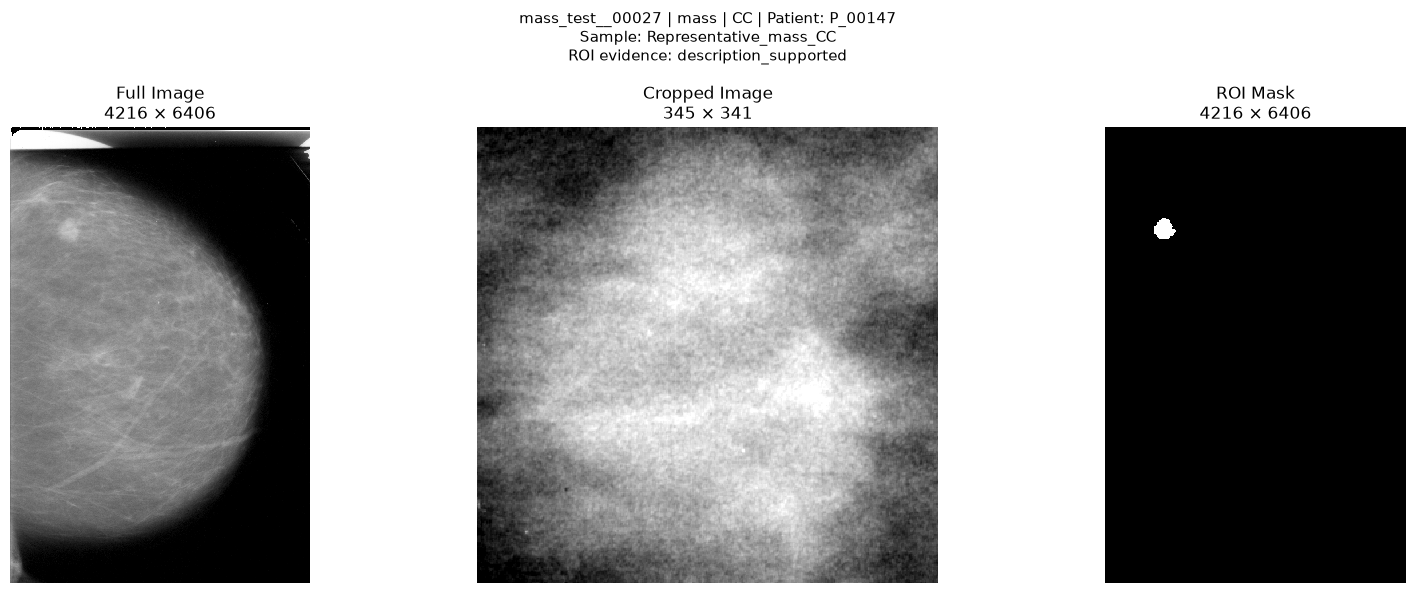

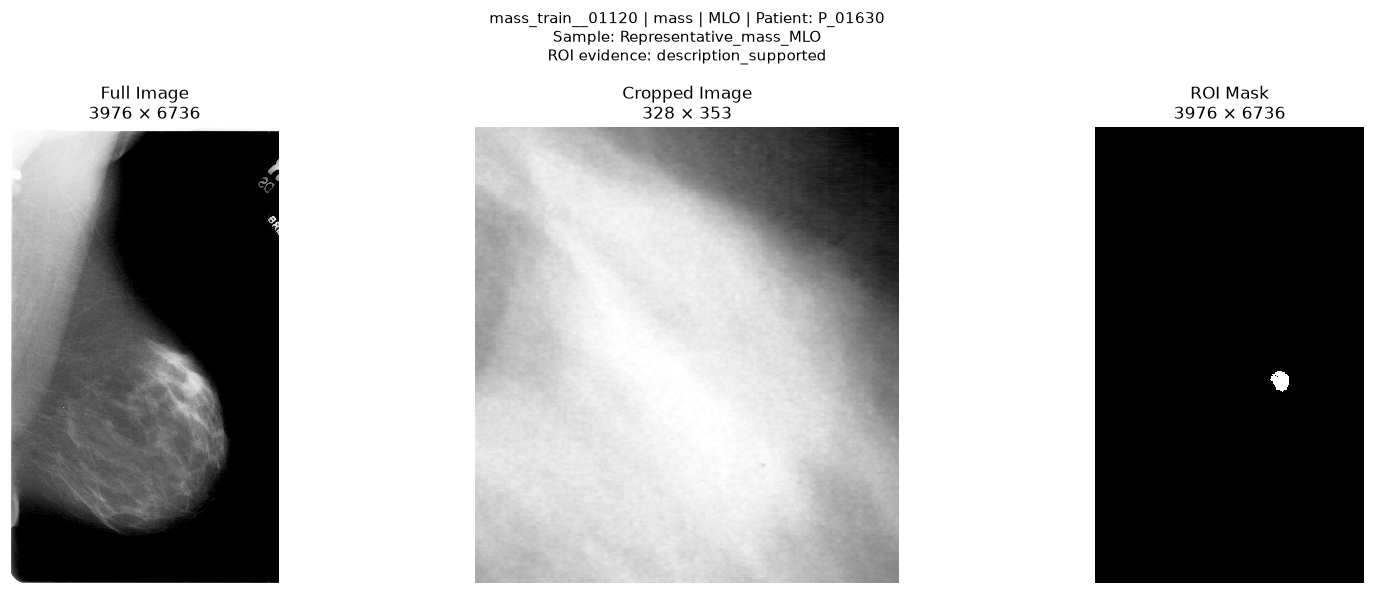

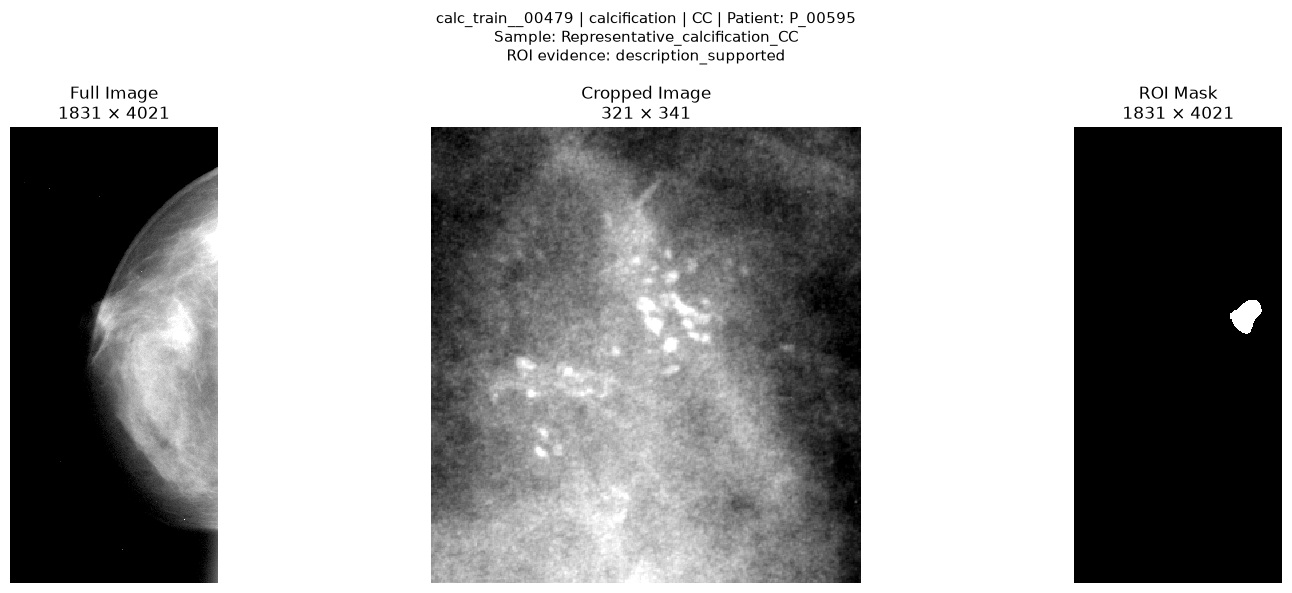

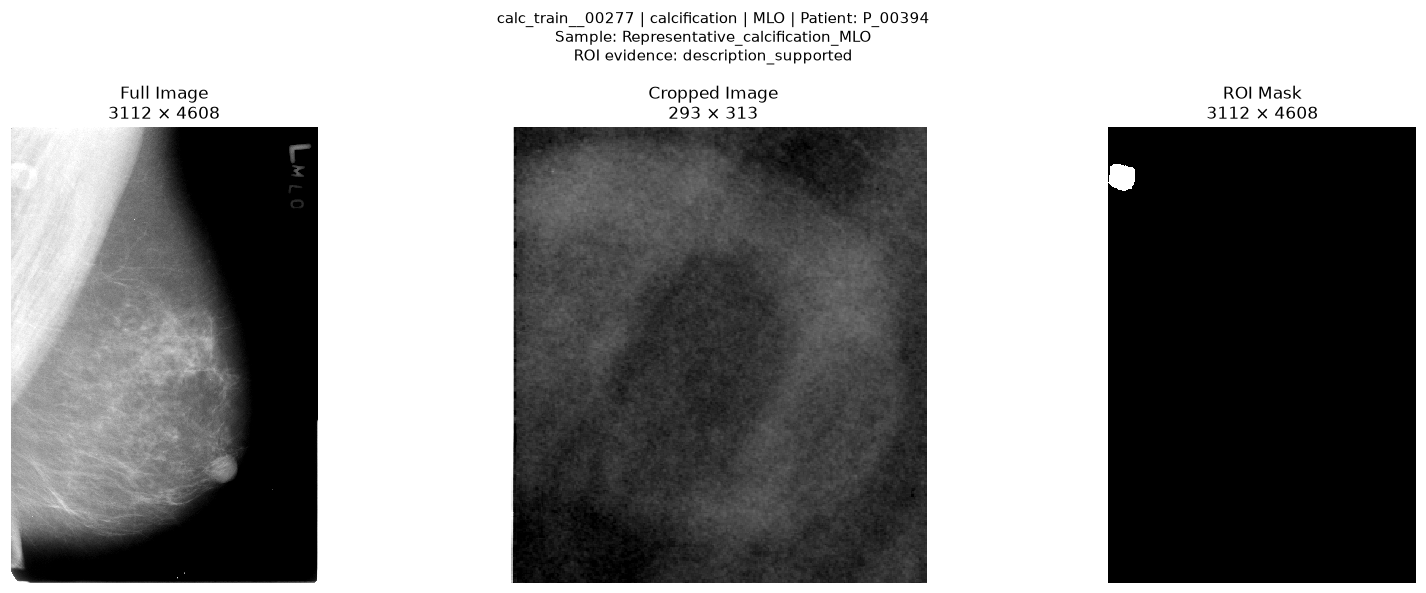

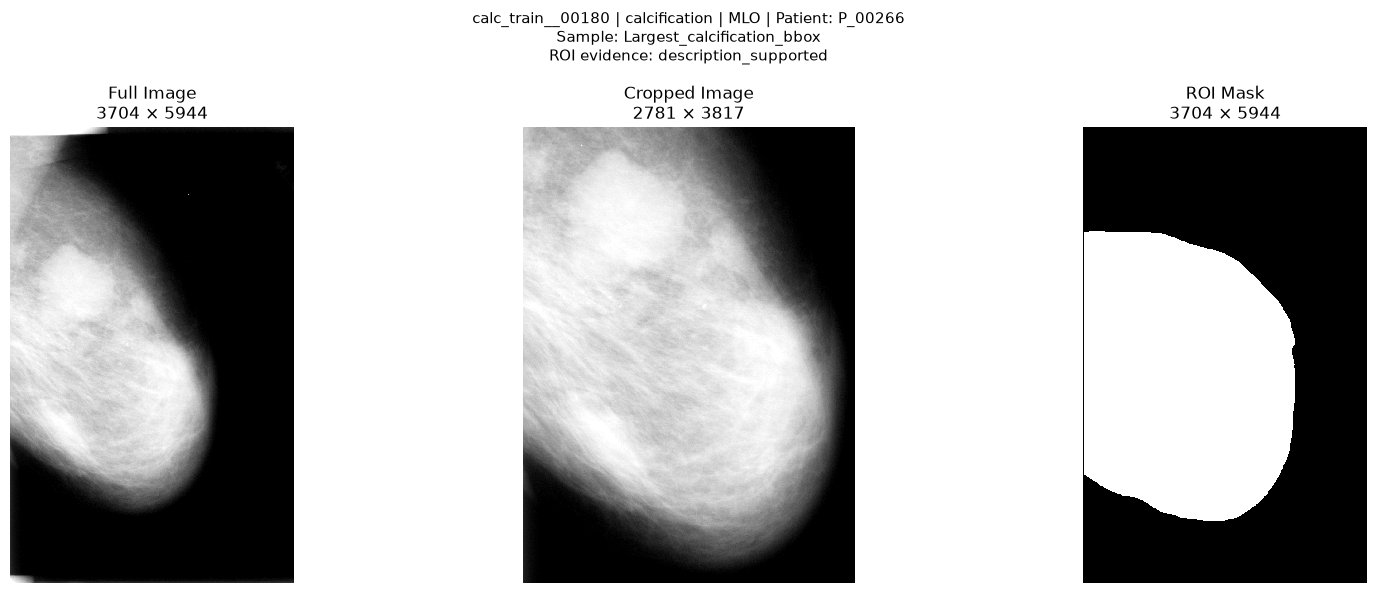

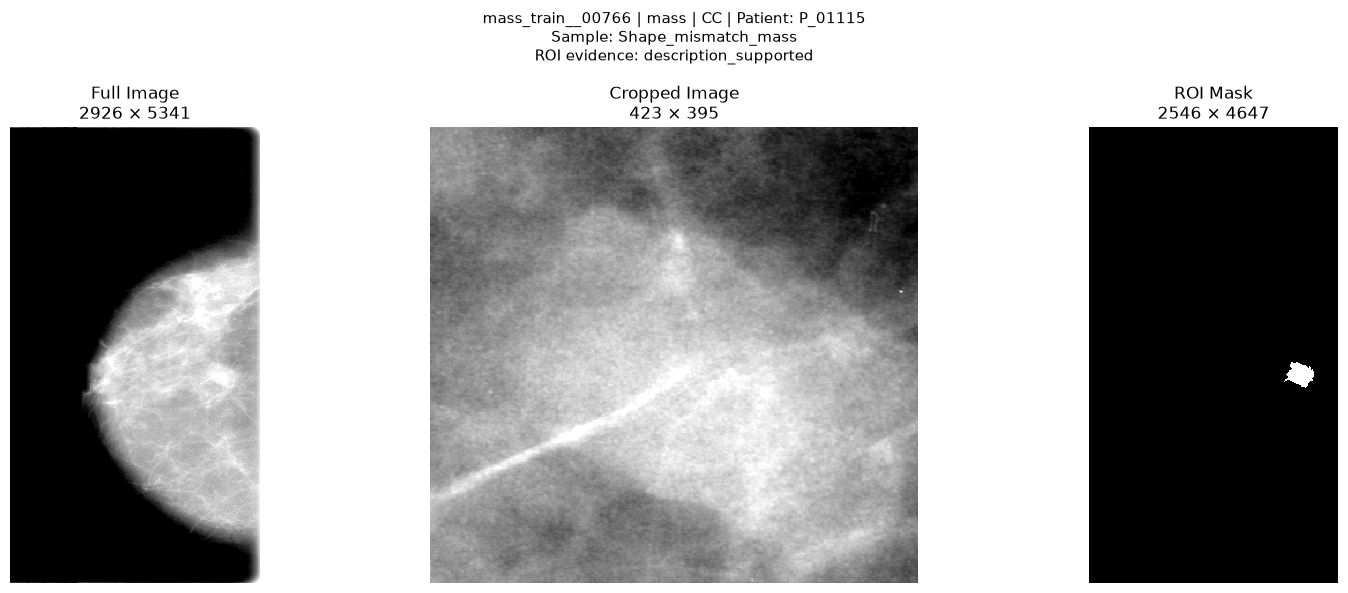

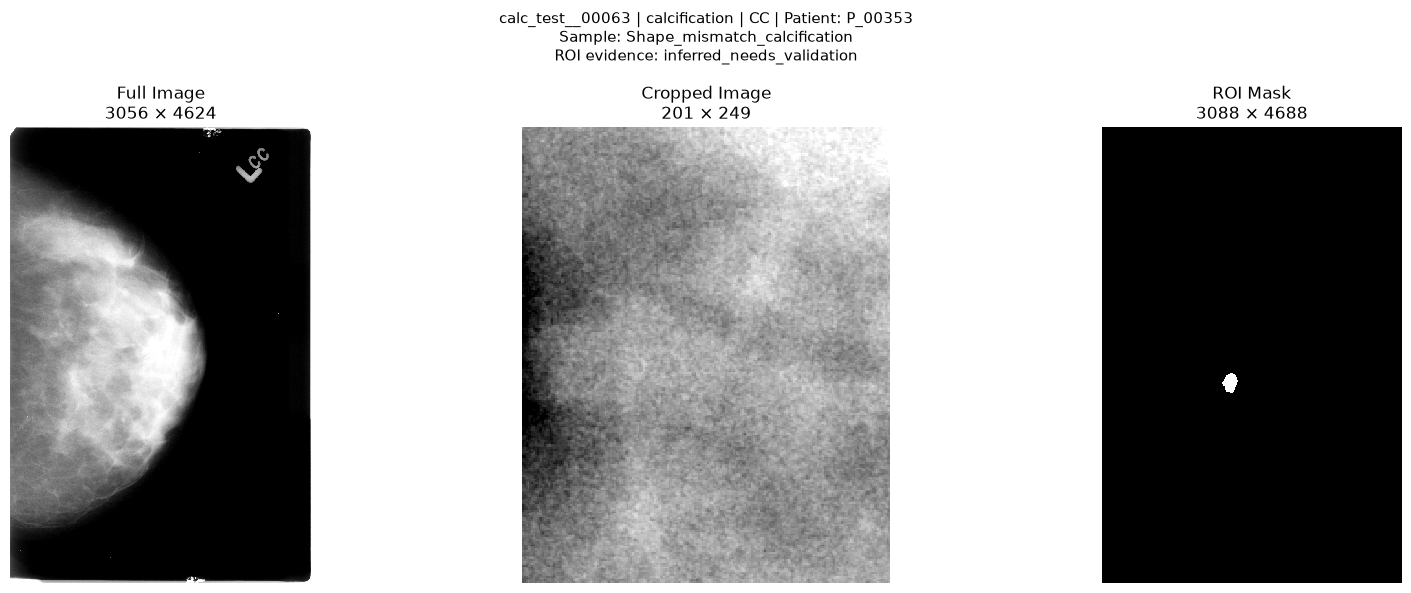

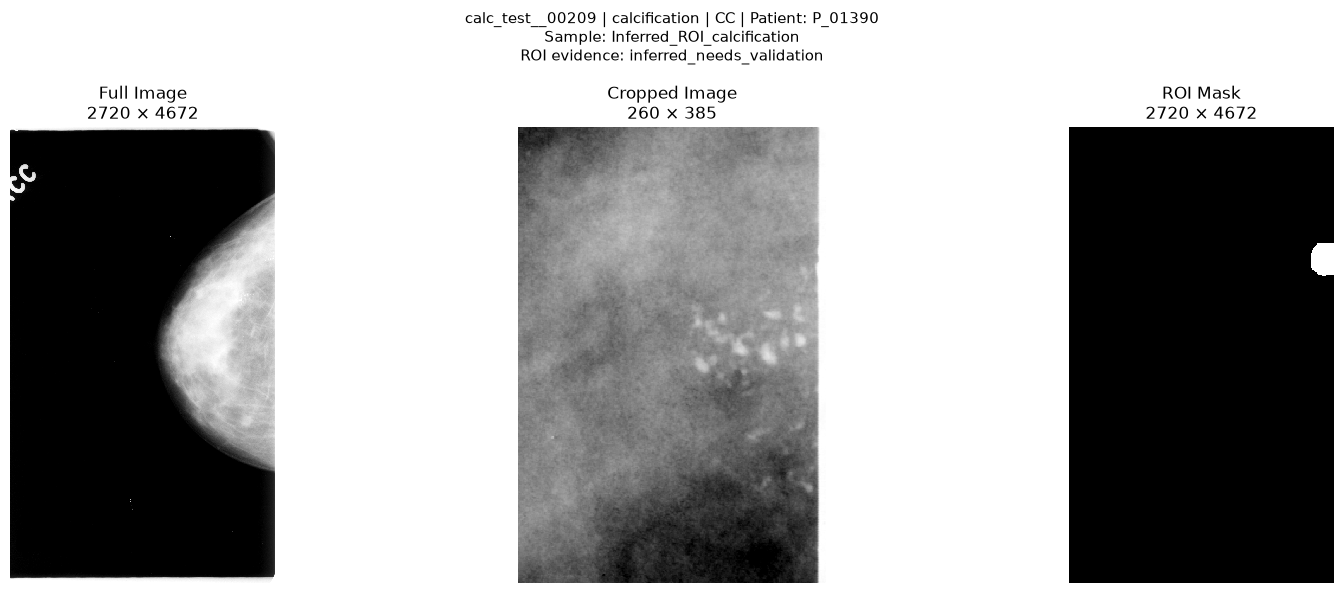

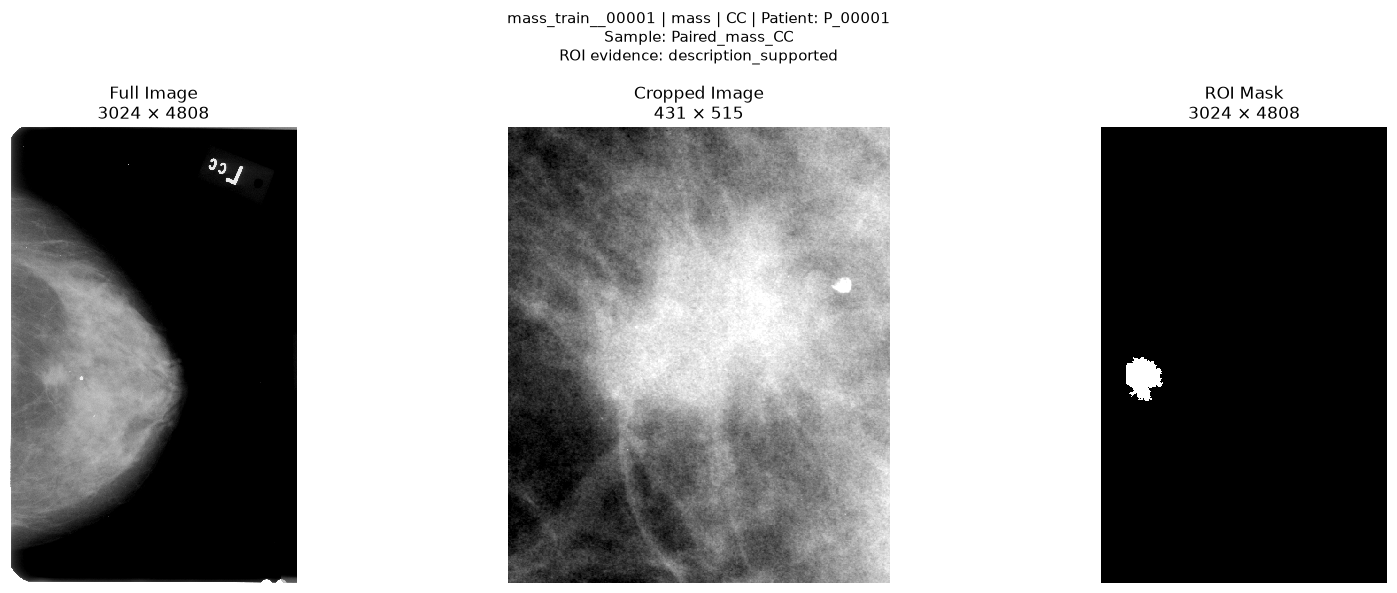

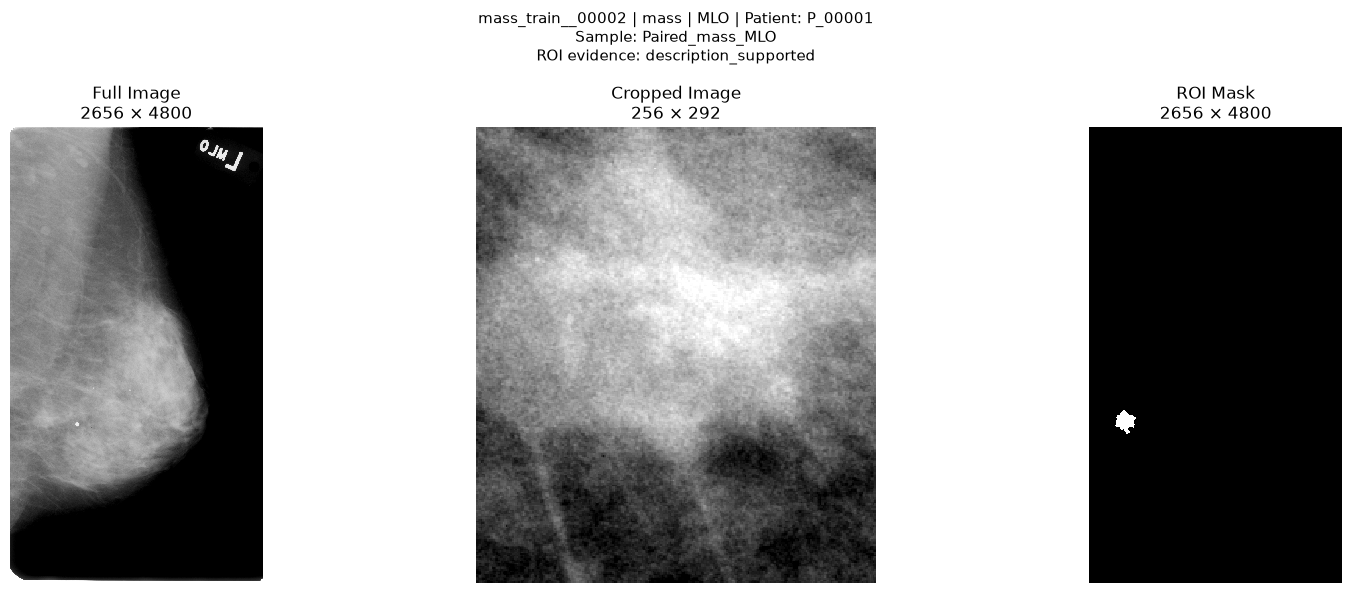

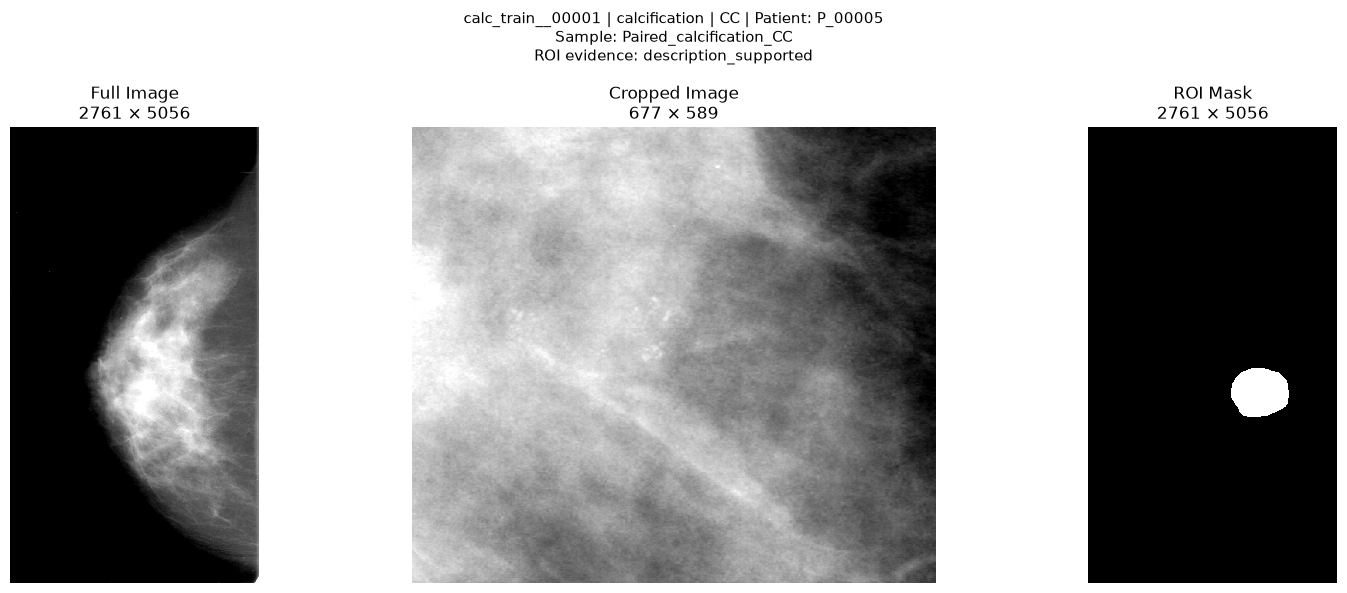

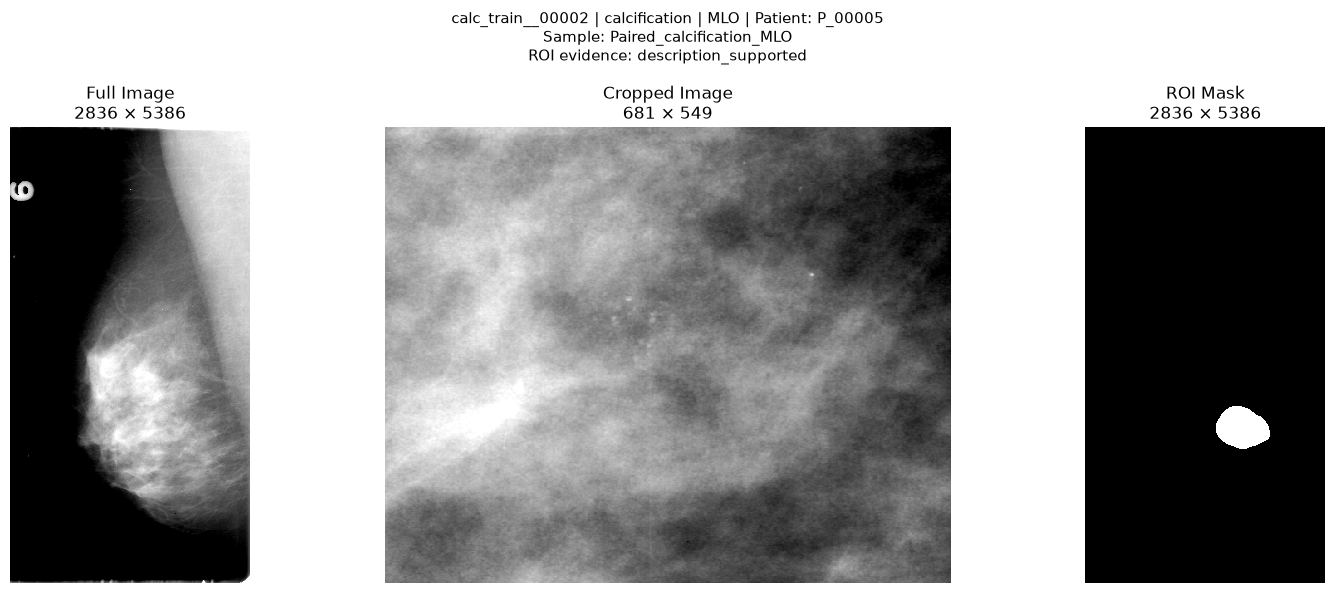

=== IMAGE READ RESULTS ===


,image_role,read_status,count
0,cropped_image,success,12
1,full_image,success,12
2,roi_mask,success,12


In [38]:
# 04.6.4 — Hiển thị ảnh và ROI Mask

def get_verified_image_path(annotation_id, image_role):

    matched = visual_image_mapping_df[
        (visual_image_mapping_df["annotation_id"] == annotation_id)
        & (visual_image_mapping_df["image_role"] == image_role)
    ]

    if len(matched) != 1:
        raise ValueError(
            f"{annotation_id}: mapping {image_role} không duy nhất."
        )

    path = Path(matched.iloc[0]["_image_path"])

    if not path.is_file():
        raise FileNotFoundError(path)

    return path


def get_verified_roi_path(annotation_id):

    matched = visual_roi_mapping_df[
        visual_roi_mapping_df["annotation_id"] == annotation_id
    ]

    if len(matched) != 1:
        raise ValueError(
            f"{annotation_id}: ROI mapping không duy nhất."
        )

    path = Path(matched.iloc[0]["_image_path"])

    if not path.is_file():
        raise FileNotFoundError(path)

    return path


visual_inspection_records = []


def render_dicom_panel(
    ax,
    annotation_id,
    image_role,
    file_path,
    title,
    is_mask=False
):

    record = {
        "annotation_id": annotation_id,
        "image_role": image_role,
        "file_path": str(file_path),
        "read_status": "success",
        "original_shape": None,
        "photometric": None,
        "error": None
    }

    try:

        arr, original_shape, photometric = read_dicom_preview(
            file_path,
            is_mask=is_mask
        )

        ax.imshow(
            arr,
            cmap="gray",
            interpolation="nearest",
            vmin=0 if is_mask else None,
            vmax=1 if is_mask else None
        )

        ax.set_title(
            f"{title}\n"
            f"{original_shape[1]} × {original_shape[0]}"
        )

        record["original_shape"] = str(original_shape)
        record["photometric"] = photometric

    except Exception as e:

        record["read_status"] = "read_error"
        record["error"] = f"{type(e).__name__}: {e}"

        ax.set_title(
            f"{title}\n{type(e).__name__}"
        )

    ax.axis("off")

    visual_inspection_records.append(record)


for _, sample in sample_plan_df.iterrows():

    annotation_id = sample["annotation_id"]

    full_path = get_verified_image_path(
        annotation_id, "full_image"
    )

    crop_path = get_verified_image_path(
        annotation_id, "cropped_image"
    )

    roi_path = get_verified_roi_path(annotation_id)

    fig, axes = plt.subplots(1, 3, figsize=(17, 6))

    fig.suptitle(
        f'{annotation_id} | {sample["lesion_type"]} | '
        f'{sample["image_view"]} | Patient: {sample["patient_id"]}\n'
        f'Sample: {sample["sample_reason"]}\n'
        f'ROI evidence: {sample["final_review_status"]}',
        fontsize=11
    )

    render_dicom_panel(
        axes[0],
        annotation_id,
        "full_image",
        full_path,
        "Full Image"
    )

    render_dicom_panel(
        axes[1],
        annotation_id,
        "cropped_image",
        crop_path,
        "Cropped Image"
    )

    render_dicom_panel(
        axes[2],
        annotation_id,
        "roi_mask",
        roi_path,
        "ROI Mask",
        is_mask=True
    )

    plt.tight_layout()
    plt.show()
    plt.close(fig)


visual_inspection_results_df = pd.DataFrame(
    visual_inspection_records
)

print("=== IMAGE READ RESULTS ===")

display(
    visual_inspection_results_df.groupby(
        ["image_role", "read_status"],
        dropna=False
    ).size().reset_index(name="count")
)

In [39]:
# 04.6.5 — Tổng hợp kết quả trực quan

print("=== VISUAL INSPECTION SUMMARY ===")

print("Số annotation được chọn:", len(sample_plan_df))

print("\nPhân bố mẫu theo loại tổn thương và góc chụp:")

display(
    sample_plan_df.groupby(
        ["lesion_type", "image_view"]
    ).size().reset_index(name="sample_count")
)

print("\nPhân bố theo lý do chọn mẫu:")

display(
    sample_plan_df["sample_reason"]
    .value_counts()
    .rename_axis("sample_reason")
    .reset_index(name="sample_count")
)

print("\nPhân bố bằng chứng ROI:")

display(
    sample_plan_df.groupby(
        ["final_review_status", "mask_quality_status"],
        dropna=False
    ).size().reset_index(name="sample_count")
)

print("\nKết quả đọc các file DICOM:")

display(
    visual_inspection_results_df.groupby(
        ["image_role", "read_status"],
        dropna=False
    ).size().reset_index(name="file_count")
)

print("\nCác file đọc không thành công:")

display(
    visual_inspection_results_df[
        visual_inspection_results_df["read_status"] != "success"
    ]
)

=== VISUAL INSPECTION SUMMARY ===
Số annotation được chọn: 12

Phân bố mẫu theo loại tổn thương và góc chụp:


,lesion_type,image_view,sample_count
0,calcification,CC,4
1,calcification,MLO,3
2,mass,CC,3
3,mass,MLO,2



Phân bố theo lý do chọn mẫu:


,sample_reason,sample_count
0,Representative_mass_CC,1
1,Representative_mass_MLO,1
2,Representative_calcification_CC,1
3,Representative_calcification_MLO,1
4,Largest_calcification_bbox,1
5,Shape_mismatch_mass,1
6,Shape_mismatch_calcification,1
7,Inferred_ROI_calcification,1
8,Paired_mass_CC,1
9,Paired_mass_MLO,1



Phân bố bằng chứng ROI:


,final_review_status,mask_quality_status,sample_count
0,description_supported,shape_mismatch,1
1,description_supported,structurally_valid,9
2,inferred_needs_validation,shape_mismatch,1
3,inferred_needs_validation,structurally_valid,1



Kết quả đọc các file DICOM:


,image_role,read_status,file_count
0,cropped_image,success,12
1,full_image,success,12
2,roi_mask,success,12



Các file đọc không thành công:


,annotation_id,image_role,file_path,read_status,original_shape,photometric,error


### Kết luận 04.6

Đã thực hiện khảo sát trực quan trên **12 annotation** đại diện cho hai nhóm tổn thương **Mass** và **Calcification**, bao gồm các góc chụp **CC** và **MLO**.

Bộ mẫu được lựa chọn dựa trên kích thước Bounding Box, tình trạng chất lượng ROI Mask, trạng thái bằng chứng phân loại và khả năng ghép cặp CC/MLO ở cấp candidate.

Mỗi annotation được liên kết với ba thành phần: **Full Image**, **Cropped Image** và **ROI Mask**. Tổng cộng **36 file DICOM** đã được đọc thành công, không ghi nhận lỗi giải mã trong các mẫu được kiểm tra.

Bộ mẫu có bao gồm các trường hợp ROI Mask `structurally_valid`, `shape_mismatch` và `inferred_needs_validation` nhằm khảo sát cả những trường hợp thông thường và những trường hợp cần thận trọng khi khai thác nhãn.

Kết quả kiểm tra trực quan được sử dụng làm bằng chứng bổ sung cho việc đánh giá tính khả thi của annotation và ROI Mask.

#### Giới hạn:
* Việc đọc thành công DICOM không đồng nghĩa với việc mọi liên kết ảnh đã được xác minh về mặt lâm sàng.
* Bounding Box đã được xác minh khớp chính xác với foreground trong ROI Mask.
* Chưa xác minh spatial alignment giữa ROI Mask và Full Image.
* Chưa sử dụng trực tiếp Bounding Box trong ROI Mask làm ground truth trên Full Image.
* Các trường hợp `inferred_needs_validation` vẫn cần được phân biệt với nhóm có bằng chứng trực tiếp.

### 4.7.1 — Tổng hợp dữ liệu phục vụ đánh giá localization
### Mục đích:
hợp nhất annotation, Full Image, Cropped Image, ROI Mask và các thông tin kiểm định đã có thành một bảng ở cấp annotation.

In [40]:
# 04.7.1 — Xây dựng bảng đánh giá localization

# 1. Metadata ở cấp annotation
metadata_cols = [
    "annotation_id",
    "lesion_candidate_id",
    "review_group_id",
    "patient_id",
    "lesion_type",
    "image_view",
    "source_split",
    "pathology"
]

metadata_cols = [
    col for col in metadata_cols
    if col in nb04_lesion_image_mapping_df.columns
]

annotation_meta_df = (
    nb04_lesion_image_mapping_df[metadata_cols]
    .copy()
)

# Kiểm tra metadata có nhất quán giữa Full và Crop
metadata_check = (
    annotation_meta_df
    .groupby("annotation_id")
    .nunique(dropna=False)
)

if (metadata_check > 1).any().any():
    raise ValueError(
        "Metadata không nhất quán giữa các quan hệ ảnh."
    )

annotation_meta_df = (
    annotation_meta_df
    .drop_duplicates(subset="annotation_id")
    .reset_index(drop=True)
)

# 2. Chọn riêng các trường hình học ROI
roi_feature_cols = [
    "annotation_id",
    "mask_quality_status",
    "roi_mask_file_path",
    "mask_rows",
    "mask_columns",
    "full_rows",
    "full_columns",
    "bbox_x_min",
    "bbox_y_min",
    "bbox_x_max",
    "bbox_y_max",
    "bbox_width",
    "bbox_height",
    "bbox_area",
    "nonzero_pixel_count",
    "spatial_alignment_verified"
]

# Chỉ lấy các cột thực sự có trong bảng
roi_feature_cols = [
    col for col in roi_feature_cols
    if col in bbox_half_open_df.columns
]

required_roi_cols = [
    "annotation_id",
    "mask_quality_status",
    "roi_mask_file_path",
    "mask_rows",
    "mask_columns",
    "full_rows",
    "full_columns",
    "bbox_x_min",
    "bbox_y_min",
    "bbox_x_max",
    "bbox_y_max",
    "bbox_width",
    "bbox_height",
    "bbox_area"
]

missing_roi_cols = (
    set(required_roi_cols)
    - set(roi_feature_cols)
)

if missing_roi_cols:
    raise ValueError(
        f"Thiếu cột ROI geometry: {missing_roi_cols}"
    )

roi_features_df = bbox_half_open_df[
    roi_feature_cols
].copy()

if roi_features_df["annotation_id"].duplicated().any():
    raise ValueError("ROI geometry có annotation bị trùng.")

# 3. Tách Full Image và Cropped Image
def get_image_role_table(role, prefix):

    cols = [
        "annotation_id",
        "_image_path",
        "SOPInstanceUID",
        "SeriesDescription",
        "final_review_status"
    ]

    cols = [
        col for col in cols
        if col in visual_image_mapping_df.columns
    ]

    result = visual_image_mapping_df.loc[
        visual_image_mapping_df["image_role"] == role,
        cols
    ].copy()

    if result["annotation_id"].duplicated().any():
        raise ValueError(
            f"{role} có annotation bị trùng."
        )

    rename_cols = {
        col: f"{prefix}_{col.lstrip('_')}"
        for col in result.columns
        if col != "annotation_id"
    }

    return result.rename(columns=rename_cols)


full_info_df = get_image_role_table(
    "full_image", "full"
)

crop_info_df = get_image_role_table(
    "cropped_image", "crop"
)

# 4. Tách thông tin ROI Mask
roi_mapping_cols = [
    "annotation_id",
    "_image_path",
    "SOPInstanceUID",
    "SeriesDescription",
    "final_review_status",
    "physical_roi_status"
]

roi_mapping_cols = [
    col for col in roi_mapping_cols
    if col in visual_roi_mapping_df.columns
]

roi_info_df = visual_roi_mapping_df[
    roi_mapping_cols
].copy()

roi_info_df = roi_info_df.rename(columns={
    "_image_path": "roi_image_path",
    "SOPInstanceUID": "roi_sop_instance_uid",
    "SeriesDescription": "roi_series_description",
    "final_review_status": "roi_review_status",
    "physical_roi_status": "roi_physical_status"
})

# 5. Ghép các bảng theo annotation_id
localization_audit_df = (
    annotation_meta_df
    .merge(
        roi_features_df,
        on="annotation_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        full_info_df,
        on="annotation_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        crop_info_df,
        on="annotation_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        roi_info_df,
        on="annotation_id",
        how="left",
        validate="one_to_one"
    )
)

# 6. Kiểm tra kết quả
print("=== LOCALIZATION AUDIT TABLE ===")
print("Shape:", localization_audit_df.shape)

print(
    "Unique annotations:",
    localization_audit_df["annotation_id"].nunique()
)

display(
    localization_audit_df[
        [
            "annotation_id",
            "lesion_candidate_id",
            "patient_id",
            "lesion_type",
            "image_view",
            "mask_quality_status",
            "bbox_width",
            "bbox_height",
            "bbox_area"
        ]
    ].head(10)
)

# 7. Kiểm tra tính đầy đủ
mapping_cols = [
    "full_image_path",
    "crop_image_path",
    "roi_image_path"
]

print("\n=== MAPPING COMPLETENESS ===")

display(
    pd.DataFrame({
        "component": [
            "Full Image",
            "Cropped Image",
            "ROI Mask"
        ],
        "available": [
            localization_audit_df[col].notna().sum()
            for col in mapping_cols
        ],
        "total": [
            len(localization_audit_df)
        ] * 3
    })
)

# 8. Kiểm tra dữ liệu hình học
assert len(localization_audit_df) == 3568

assert localization_audit_df[
    "annotation_id"
].is_unique

assert localization_audit_df[
    "bbox_area"
].notna().all()

print("\n[OK] Localization audit table đã được tạo.")

=== LOCALIZATION AUDIT TABLE ===
Shape: (3568, 36)
Unique annotations: 3568


,annotation_id,lesion_candidate_id,patient_id,lesion_type,image_view,mask_quality_status,bbox_width,bbox_height,bbox_area
0,calc_train__00001,LCAND_000004,P_00005,calcification,CC,structurally_valid,637,549,349713
1,calc_train__00002,LCAND_000004,P_00005,calcification,MLO,structurally_valid,641,509,326269
2,calc_train__00003,LCAND_000005,P_00007,calcification,CC,structurally_valid,537,641,344217
3,calc_train__00004,LCAND_000005,P_00007,calcification,MLO,structurally_valid,721,649,467929
4,calc_train__00005,NaN,P_00008,calcification,CC,structurally_valid,137,121,16577
5,calc_train__00006,NaN,P_00008,calcification,CC,structurally_valid,137,129,17673
6,calc_train__00007,NaN,P_00008,calcification,CC,structurally_valid,105,73,7665
7,calc_train__00008,NaN,P_00008,calcification,MLO,structurally_valid,97,89,8633
8,calc_train__00009,NaN,P_00008,calcification,MLO,structurally_valid,89,105,9345
9,calc_train__00010,NaN,P_00008,calcification,MLO,structurally_valid,105,81,8505



=== MAPPING COMPLETENESS ===


,component,available,total
0,Full Image,3568,3568
1,Cropped Image,3568,3568
2,ROI Mask,3568,3568



[OK] Localization audit table đã được tạo.


In [41]:
# 04.7.2 — So sánh kích thước ROI, Crop và Full Image

from pathlib import Path
import pandas as pd
import numpy as np
import pydicom

# 1. Hàm đọc kích thước từ DICOM header
def read_dicom_dimensions(file_path):

    try:
        ds = pydicom.dcmread(
            str(file_path),
            stop_before_pixels=True,
            specific_tags=[
                "Rows",
                "Columns",
                "SOPInstanceUID",
                "PhotometricInterpretation"
            ]
        )

        return {
            "crop_rows": int(ds.Rows),
            "crop_columns": int(ds.Columns),
            "crop_sop_uid_header": str(
                ds.get("SOPInstanceUID", "")
            ),
            "crop_photometric": str(
                ds.get("PhotometricInterpretation", "")
            ),
            "crop_header_status": "success"
        }

    except Exception as e:

        return {
            "crop_rows": np.nan,
            "crop_columns": np.nan,
            "crop_sop_uid_header": None,
            "crop_photometric": None,
            "crop_header_status": type(e).__name__
        }


# 2. Lấy đường dẫn Cropped Image đã kiểm định
crop_source_df = visual_image_mapping_df[
    visual_image_mapping_df["image_role"] == "cropped_image"
][
    ["annotation_id", "_image_path", "SOPInstanceUID"]
].copy()

if crop_source_df["annotation_id"].duplicated().any():
    raise ValueError("Cropped Image có annotation bị trùng.")

crop_header_records = []

for i, (_, row) in enumerate(crop_source_df.iterrows()):

    result = read_dicom_dimensions(row["_image_path"])

    crop_header_records.append({
        "annotation_id": row["annotation_id"],
        "crop_sop_uid_mapping": row["SOPInstanceUID"],
        **result
    })

    if (i + 1) % 500 == 0:
        print(f"Đã đọc header: {i + 1}/{len(crop_source_df)}")


crop_dimension_df = pd.DataFrame(crop_header_records)


# 3. Tạo bảng so sánh ba thành phần
dimension_audit_df = localization_audit_df[
    [
        "annotation_id",
        "lesion_type",
        "image_view",
        "mask_quality_status",
        "mask_rows",
        "mask_columns",
        "full_rows",
        "full_columns"
    ]
].merge(
    crop_dimension_df,
    on="annotation_id",
    how="left",
    validate="one_to_one"
)


# 4. Kiểm tra SOP UID có khớp mapping không
dimension_audit_df["crop_sop_uid_match"] = (
    dimension_audit_df["crop_sop_uid_mapping"].astype(str)
    == dimension_audit_df["crop_sop_uid_header"].astype(str)
)


# 5. So sánh kích thước, giữ riêng trường hợp header lỗi
def compare_shape(row, rows_a, cols_a, rows_b, cols_b):

    values = [
        row[rows_a], row[cols_a],
        row[rows_b], row[cols_b]
    ]

    if any(pd.isna(v) for v in values):
        return "not_comparable"

    if values[0] == values[2] and values[1] == values[3]:
        return "match"

    return "mismatch"


dimension_audit_df["mask_crop_status"] = (
    dimension_audit_df.apply(
        lambda row: compare_shape(
            row,
            "mask_rows", "mask_columns",
            "crop_rows", "crop_columns"
        ),
        axis=1
    )
)

dimension_audit_df["mask_full_status"] = (
    dimension_audit_df.apply(
        lambda row: compare_shape(
            row,
            "mask_rows", "mask_columns",
            "full_rows", "full_columns"
        ),
        axis=1
    )
)

dimension_audit_df["crop_full_status"] = (
    dimension_audit_df.apply(
        lambda row: compare_shape(
            row,
            "crop_rows", "crop_columns",
            "full_rows", "full_columns"
        ),
        axis=1
    )
)

dimension_audit_df["all_three_shapes_match"] = (
    dimension_audit_df["mask_crop_status"].eq("match")
    & dimension_audit_df["mask_full_status"].eq("match")
    & dimension_audit_df["crop_full_status"].eq("match")
)


# 6. Tổng hợp header
print("\n=== CROP HEADER STATUS ===")

display(
    dimension_audit_df["crop_header_status"]
    .value_counts(dropna=False)
    .rename_axis("header_status")
    .reset_index(name="annotation_count")
)

print("\n=== CROP SOP UID VALIDATION ===")

display(
    dimension_audit_df["crop_sop_uid_match"]
    .value_counts(dropna=False)
    .rename_axis("sop_uid_match")
    .reset_index(name="annotation_count")
)


# 7. Tổng hợp ba phép so sánh kích thước
print("\n=== THREE-WAY SHAPE COMPARISON ===")

comparison_cols = [
    "mask_crop_status",
    "mask_full_status",
    "crop_full_status"
]

comparison_summary = []

for col in comparison_cols:

    counts = dimension_audit_df[col].value_counts()

    for status in ["match", "mismatch", "not_comparable"]:

        comparison_summary.append({
            "comparison": col,
            "status": status,
            "annotation_count": int(counts.get(status, 0))
        })

display(pd.DataFrame(comparison_summary))


# 8. Phân tích theo loại tổn thương
print("\n=== SHAPE COMPARISON BY LESION TYPE ===")

display(
    dimension_audit_df.groupby("lesion_type").agg(
        annotation_count=("annotation_id", "size"),
        mask_crop_match=(
            "mask_crop_status",
            lambda x: (x == "match").sum()
        ),
        mask_crop_mismatch=(
            "mask_crop_status",
            lambda x: (x == "mismatch").sum()
        ),
        mask_full_match=(
            "mask_full_status",
            lambda x: (x == "match").sum()
        ),
        crop_full_match=(
            "crop_full_status",
            lambda x: (x == "match").sum()
        )
    ).reset_index()
)


# 9. Danh sách trường hợp cần rà soát
dimension_exception_df = dimension_audit_df[
    (dimension_audit_df["mask_crop_status"] != "match")
    | (dimension_audit_df["mask_full_status"] != "match")
    | (~dimension_audit_df["crop_sop_uid_match"])
].copy()

print("\n=== DIMENSION EXCEPTIONS ===")

display(
    dimension_exception_df[
        [
            "annotation_id",
            "lesion_type",
            "image_view",
            "mask_rows",
            "mask_columns",
            "crop_rows",
            "crop_columns",
            "full_rows",
            "full_columns",
            "mask_crop_status",
            "mask_full_status",
            "crop_full_status",
            "crop_sop_uid_match"
        ]
    ].head(30)
)

Đã đọc header: 500/3568
Đã đọc header: 1000/3568
Đã đọc header: 1500/3568
Đã đọc header: 2000/3568
Đã đọc header: 2500/3568
Đã đọc header: 3000/3568
Đã đọc header: 3500/3568

=== CROP HEADER STATUS ===


,header_status,annotation_count
0,success,3568



=== CROP SOP UID VALIDATION ===


,sop_uid_match,annotation_count
0,True,3568



=== THREE-WAY SHAPE COMPARISON ===


,comparison,status,annotation_count
0,mask_crop_status,match,0
1,mask_crop_status,mismatch,3568
2,mask_crop_status,not_comparable,0
3,mask_full_status,match,3488
4,mask_full_status,mismatch,80
5,mask_full_status,not_comparable,0
6,crop_full_status,match,0
7,crop_full_status,mismatch,3568
8,crop_full_status,not_comparable,0



=== SHAPE COMPARISON BY LESION TYPE ===


,lesion_type,annotation_count,mask_crop_match,mask_crop_mismatch,mask_full_match,crop_full_match
0,calcification,1872,0,1872,1870,0
1,mass,1696,0,1696,1618,0



=== DIMENSION EXCEPTIONS ===


,annotation_id,lesion_type,image_view,mask_rows,mask_columns,crop_rows,crop_columns,full_rows,full_columns,mask_crop_status,mask_full_status,crop_full_status,crop_sop_uid_match
0,calc_train__00001,calcification,CC,5056,2761,589,677,5056,2761,mismatch,match,mismatch,True
1,calc_train__00002,calcification,MLO,5386,2836,549,681,5386,2836,mismatch,match,mismatch,True
2,calc_train__00003,calcification,CC,5356,2986,681,577,5356,2986,mismatch,match,mismatch,True
3,calc_train__00004,calcification,MLO,5491,3166,689,761,5491,3166,mismatch,match,mismatch,True
4,calc_train__00005,calcification,CC,4568,3064,161,177,4568,3064,mismatch,match,mismatch,True
5,calc_train__00006,calcification,CC,4568,3064,169,177,4568,3064,mismatch,match,mismatch,True
6,calc_train__00007,calcification,CC,4568,3064,113,145,4568,3064,mismatch,match,mismatch,True
7,calc_train__00008,calcification,MLO,4528,3056,129,137,4528,3056,mismatch,match,mismatch,True
8,calc_train__00009,calcification,MLO,4528,3056,145,129,4528,3056,mismatch,match,mismatch,True
9,calc_train__00010,calcification,MLO,4528,3056,121,145,4528,3056,mismatch,match,mismatch,True


In [42]:
# 04.7.3 — Bounding Box Coordinate Validation

# Kiểm tra các DataFrame đầu vào
required_objects = ["bbox_half_open_df", "localization_audit_df", "bbox_mask_audit_df"]
missing_objects = [name for name in required_objects if name not in globals()]

if missing_objects:
    raise NameError(f"Thiếu DataFrame cần thiết: {missing_objects}")

bbox_source_df = bbox_half_open_df.copy()

if "annotation_id" not in bbox_source_df.columns:
    raise KeyError("bbox_half_open_df không có cột annotation_id.")


def resolve_column(df, candidates, field_name):
    """Tìm tên cột thực tế từ danh sách tên có thể có."""
    normalized = {
        str(col).strip().lower().replace(" ", "_"): col
        for col in df.columns
    }

    for candidate in candidates:
        key = candidate.strip().lower().replace(" ", "_")
        if key in normalized:
            return normalized[key]

    raise KeyError(
        f"Không tìm thấy cột cho {field_name}. "
        f"Các cột hiện có: {df.columns.tolist()}"
    )

# Tự nhận diện tên cột tọa độ
bbox_columns = {
    "x_min": resolve_column(
        bbox_source_df,
        ["bbox_x_min", "bbox_xmin", "x_min", "xmin", "bbox_min_x"],
        "x_min"
    ),
    "y_min": resolve_column(
        bbox_source_df,
        ["bbox_y_min", "bbox_ymin", "y_min", "ymin", "bbox_min_y"],
        "y_min"
    ),
    "x_max": resolve_column(
        bbox_source_df,
        ["bbox_x_max", "bbox_xmax", "x_max", "xmax", "bbox_max_x"],
        "x_max"
    ),
    "y_max": resolve_column(
        bbox_source_df,
        ["bbox_y_max", "bbox_ymax", "y_max", "ymax", "bbox_max_y"],
        "y_max"
    )
}

# Chuẩn hóa tên cột để các bước sau sử dụng thống nhất
bbox_localization_df = bbox_source_df[
    ["annotation_id"]
].copy()

for standard_name, actual_name in bbox_columns.items():
    bbox_localization_df[standard_name] = pd.to_numeric(
        bbox_source_df[actual_name],
        errors="coerce"
    )

# Bổ sung kích thước ROI Mask từ bảng kiểm tra localization
mask_dimension_columns = ["annotation_id", "mask_rows", "mask_columns"]

missing_dimension_columns = [
    col for col in mask_dimension_columns
    if col not in localization_audit_df.columns
]

if missing_dimension_columns:
    raise KeyError(
        f"Thiếu cột kích thước ROI Mask: {missing_dimension_columns}"
    )

mask_dimensions_df = (
    localization_audit_df[mask_dimension_columns]
    .drop_duplicates(subset="annotation_id")
)

bbox_localization_df = bbox_localization_df.merge(
    mask_dimensions_df,
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

# Tính lại kích thước Bounding Box theo quy ước upper-exclusive
bbox_localization_df["bbox_width_calculated"] = (
    bbox_localization_df["x_max"] - bbox_localization_df["x_min"]
)

bbox_localization_df["bbox_height_calculated"] = (
    bbox_localization_df["y_max"] - bbox_localization_df["y_min"]
)

bbox_localization_df["bbox_area_calculated"] = (
    bbox_localization_df["bbox_width_calculated"]
    * bbox_localization_df["bbox_height_calculated"]
)

# Kiểm tra tọa độ nằm trong phạm vi ROI Mask
bbox_localization_df["bbox_coordinate_valid"] = (
    bbox_localization_df["x_min"].notna()
    & bbox_localization_df["y_min"].notna()
    & bbox_localization_df["x_max"].notna()
    & bbox_localization_df["y_max"].notna()
    & bbox_localization_df["mask_rows"].notna()
    & bbox_localization_df["mask_columns"].notna()
    & (bbox_localization_df["x_min"] >= 0)
    & (bbox_localization_df["y_min"] >= 0)
    & (bbox_localization_df["x_min"] < bbox_localization_df["x_max"])
    & (bbox_localization_df["y_min"] < bbox_localization_df["y_max"])
    & (bbox_localization_df["x_max"] <= bbox_localization_df["mask_columns"])
    & (bbox_localization_df["y_max"] <= bbox_localization_df["mask_rows"])
)

print("=== BOUNDING BOX COORDINATE VALIDATION ===")
print(f"Tổng annotation: {len(bbox_localization_df):,}")
print(
    "Bounding Box hợp lệ:",
    int(bbox_localization_df["bbox_coordinate_valid"].sum())
)
print(
    "Bounding Box không hợp lệ:",
    int((~bbox_localization_df["bbox_coordinate_valid"]).sum())
)

display(
    bbox_localization_df[
        [
            "annotation_id",
            "x_min", "y_min", "x_max", "y_max",
            "mask_rows", "mask_columns",
            "bbox_width_calculated",
            "bbox_height_calculated",
            "bbox_area_calculated",
            "bbox_coordinate_valid"
        ]
    ].head()
)

=== BOUNDING BOX COORDINATE VALIDATION ===
Tổng annotation: 3,568
Bounding Box hợp lệ: 3568
Bounding Box không hợp lệ: 0


,annotation_id,x_min,y_min,x_max,y_max,mask_rows,mask_columns,bbox_width_calculated,bbox_height_calculated,bbox_area_calculated,bbox_coordinate_valid
0,calc_train__00001,1585,2669,2222,3218,5056,2761,637,549,349713,True
1,calc_train__00002,1540,3294,2181,3803,5386,2836,641,509,326269,True
2,calc_train__00003,1416,1260,1953,1901,5356,2986,537,641,344217,True
3,calc_train__00004,1164,2572,1885,3221,5491,3166,721,649,467929,True
4,calc_train__00005,1568,1904,1705,2025,4568,3064,137,121,16577,True


In [43]:
# Đối chiếu kích thước tính lại với kích thước Bounding Box đã lưu

stored_geometry_columns = {
    "width": ["bbox_width"],
    "height": ["bbox_height"],
    "area": ["bbox_area"]
}

geometry_source = bbox_source_df.copy()

for key, candidates in stored_geometry_columns.items():
    actual_col = resolve_column(
        geometry_source,
        candidates,
        f"stored bbox {key}"
    )

    bbox_localization_df[f"bbox_{key}_stored"] = pd.to_numeric(
        geometry_source[actual_col],
        errors="coerce"
    ).values

bbox_localization_df["geometry_consistent"] = (
    np.isclose(
        bbox_localization_df["bbox_width_calculated"],
        bbox_localization_df["bbox_width_stored"],
        equal_nan=False
    )
    & np.isclose(
        bbox_localization_df["bbox_height_calculated"],
        bbox_localization_df["bbox_height_stored"],
        equal_nan=False
    )
    & np.isclose(
        bbox_localization_df["bbox_area_calculated"],
        bbox_localization_df["bbox_area_stored"],
        equal_nan=False
    )
)

# Lấy kết quả audit foreground đã thực hiện ở Notebook 04.5
audit_columns = [
    col for col in [
        "annotation_id",
        "mask_shape_matches",
        "bbox_matches_foreground",
        "audit_status"
    ]
    if col in bbox_mask_audit_df.columns
]

if "annotation_id" not in audit_columns:
    raise KeyError("bbox_mask_audit_df không có cột annotation_id.")

bbox_audit_subset = (
    bbox_mask_audit_df[audit_columns]
    .drop_duplicates(subset="annotation_id")
)

bbox_localization_df = bbox_localization_df.merge(
    bbox_audit_subset,
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

# Tổng hợp kết quả
bbox_validation_summary = pd.DataFrame([
    {
        "check": "bbox_coordinate_valid",
        "count": int(bbox_localization_df["bbox_coordinate_valid"].sum())
    },
    {
        "check": "geometry_consistent",
        "count": int(bbox_localization_df["geometry_consistent"].sum())
    },
    {
        "check": "bbox_matches_foreground",
        "count": (
            int(bbox_localization_df["bbox_matches_foreground"].fillna(False).sum())
            if "bbox_matches_foreground" in bbox_localization_df.columns
            else np.nan
        )
    },
    {
        "check": "mask_shape_matches",
        "count": (
            int(bbox_localization_df["mask_shape_matches"].fillna(False).sum())
            if "mask_shape_matches" in bbox_localization_df.columns
            else np.nan
        )
    }
])

bbox_validation_summary["total_annotations"] = len(bbox_localization_df)

print("=== BOUNDING BOX VALIDATION SUMMARY ===")
display(bbox_validation_summary)

print("\n=== VALIDATION STATUS ===")
print(
    bbox_localization_df[
        [
            "annotation_id",
            "bbox_coordinate_valid",
            "geometry_consistent"
        ]
    ].head()
)

=== BOUNDING BOX VALIDATION SUMMARY ===


,check,count,total_annotations
0,bbox_coordinate_valid,3568,3568
1,geometry_consistent,3568,3568
2,bbox_matches_foreground,3568,3568
3,mask_shape_matches,3568,3568



=== VALIDATION STATUS ===
       annotation_id  bbox_coordinate_valid  geometry_consistent
0  calc_train__00001                   True                 True
1  calc_train__00002                   True                 True
2  calc_train__00003                   True                 True
3  calc_train__00004                   True                 True
4  calc_train__00005                   True                 True


In [44]:
# 04.7.4 — Annotation and Image Linkage Completeness

if "localization_audit_df" not in globals():
    raise NameError("Chưa có localization_audit_df. Hãy chạy 04.7.1 trước.")

linkage_df = localization_audit_df.drop_duplicates(
    subset="annotation_id"
).copy()

if linkage_df["annotation_id"].duplicated().any():
    raise ValueError("annotation_id vẫn bị trùng sau khi loại bản ghi trùng.")

required_link_columns = [
    "lesion_candidate_id",
    "patient_id",
    "full_image_path",
    "crop_image_path",
    "roi_image_path"
]

missing_columns = [
    col for col in required_link_columns
    if col not in linkage_df.columns
]

if missing_columns:
    raise KeyError(f"Thiếu các cột cần thiết: {missing_columns}")

annotation_linkage_summary = pd.DataFrame([
    {
        "item": "Total annotations",
        "count": len(linkage_df)
    },
    {
        "item": "Annotations with lesion candidate",
        "count": int(linkage_df["lesion_candidate_id"].notna().sum())
    },
    {
        "item": "Annotations without lesion candidate",
        "count": int(linkage_df["lesion_candidate_id"].isna().sum())
    },
    {
        "item": "Unique patients",
        "count": int(linkage_df["patient_id"].nunique())
    },
    {
        "item": "Annotations with Full Image path",
        "count": int(linkage_df["full_image_path"].notna().sum())
    },
    {
        "item": "Annotations with Cropped Image path",
        "count": int(linkage_df["crop_image_path"].notna().sum())
    },
    {
        "item": "Annotations with ROI Mask path",
        "count": int(linkage_df["roi_image_path"].notna().sum())
    }
])

print("=== ANNOTATION AND IMAGE LINKAGE ===")
display(annotation_linkage_summary)

=== ANNOTATION AND IMAGE LINKAGE ===


,item,count
0,Total annotations,3568
1,Annotations with lesion candidate,2945
2,Annotations without lesion candidate,623
3,Unique patients,1566
4,Annotations with Full Image path,3568
5,Annotations with Cropped Image path,3568
6,Annotations with ROI Mask path,3568


In [45]:
# Image reuse analysis

full_image_usage = (
    linkage_df.dropna(subset=["full_image_path"])
    .groupby("full_image_path")["annotation_id"]
    .nunique()
    .rename("annotation_count")
    .reset_index()
)

crop_image_usage = (
    linkage_df.dropna(subset=["crop_image_path"])
    .groupby("crop_image_path")["annotation_id"]
    .nunique()
    .rename("annotation_count")
    .reset_index()
)

full_shared_paths = full_image_usage[
    full_image_usage["annotation_count"] > 1
]

crop_shared_paths = crop_image_usage[
    crop_image_usage["annotation_count"] > 1
]

image_reuse_summary = pd.DataFrame([
    {
        "image_role": "Full Image",
        "total_relations": int(linkage_df["full_image_path"].notna().sum()),
        "unique_paths": int(full_image_usage["full_image_path"].nunique()),
        "shared_paths": len(full_shared_paths),
        "extra_annotation_associations": int(
            (full_image_usage["annotation_count"] - 1).clip(lower=0).sum()
        )
    },
    {
        "image_role": "Cropped Image",
        "total_relations": int(linkage_df["crop_image_path"].notna().sum()),
        "unique_paths": int(crop_image_usage["crop_image_path"].nunique()),
        "shared_paths": len(crop_shared_paths),
        "extra_annotation_associations": int(
            (crop_image_usage["annotation_count"] - 1).clip(lower=0).sum()
        )
    }
])

print("=== IMAGE REUSE SUMMARY ===")
display(image_reuse_summary)

print("\n=== FULL IMAGE SHARED BY MULTIPLE ANNOTATIONS ===")
display(
    full_shared_paths
    .sort_values("annotation_count", ascending=False)
    .head(10)
)

=== IMAGE REUSE SUMMARY ===


,image_role,total_relations,unique_paths,shared_paths,extra_annotation_associations
0,Full Image,3568,3103,293,465
1,Cropped Image,3568,3568,0,0



=== FULL IMAGE SHARED BY MULTIPLE ANNOTATIONS ===


,full_image_path,annotation_count
1148,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,7
114,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,7
915,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,6
933,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,6
2284,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,6
113,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,6
934,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,6
723,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,6
935,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,6
112,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,6


In [46]:
# Patient-level split leakage check

if "source_split" not in linkage_df.columns:
    raise KeyError(
        "Không tìm thấy cột source_split trong localization_audit_df."
    )

patient_split_df = (
    linkage_df.dropna(subset=["patient_id", "source_split"])
    .assign(
        source_split=lambda df: (
            df["source_split"].astype(str).str.strip().str.lower()
        )
    )
    .groupby("patient_id")["source_split"]
    .agg(lambda values: set(values))
    .reset_index(name="splits")
)

train_patients = set(
    patient_split_df.loc[
        patient_split_df["splits"].apply(
            lambda x: "train" in x or "training" in x
        ),
        "patient_id"
    ]
)

test_patients = set(
    patient_split_df.loc[
        patient_split_df["splits"].apply(
            lambda x: "test" in x or "testing" in x
        ),
        "patient_id"
    ]
)

overlap_patients = train_patients.intersection(test_patients)

patient_split_summary = pd.DataFrame([
    {
        "item": "Patients in Train",
        "count": len(train_patients)
    },
    {
        "item": "Patients in Test",
        "count": len(test_patients)
    },
    {
        "item": "Patients appearing in both Train and Test",
        "count": len(overlap_patients)
    },
    {
        "item": "Train-Test patient overlap percentage",
        "count": (
            round(
                len(overlap_patients) / len(train_patients.union(test_patients)) * 100,
                2
            )
            if train_patients.union(test_patients)
            else np.nan
        )
    }
])

print("=== PATIENT-LEVEL SPLIT AUDIT ===")
display(patient_split_summary)

print("\nSố patient xuất hiện ở cả hai tập:", len(overlap_patients))

=== PATIENT-LEVEL SPLIT AUDIT ===


,item,count
0,Patients in Train,1248.00
1,Patients in Test,349.00
2,Patients appearing in both Train and Test,31.00
3,Train-Test patient overlap percentage,1.98



Số patient xuất hiện ở cả hai tập: 31


In [47]:
# 04.7.5 — Localization Feasibility Summary

if "dimension_audit_df" not in globals():
    raise NameError("Chưa có dimension_audit_df. Hãy chạy 04.7.2 trước.")

if "bbox_localization_df" not in globals():
    raise NameError("Chưa có bbox_localization_df. Hãy chạy 04.7.3 trước.")

total_annotations = len(localization_audit_df)

# Đếm trạng thái kích thước từ 04.7.2
mask_crop_match = int(
    (dimension_audit_df["mask_crop_status"] == "match").sum()
)

mask_crop_mismatch = int(
    (dimension_audit_df["mask_crop_status"] == "mismatch").sum()
)

mask_full_match = int(
    (dimension_audit_df["mask_full_status"] == "match").sum()
)

mask_full_mismatch = int(
    (dimension_audit_df["mask_full_status"] == "mismatch").sum()
)

crop_full_match = int(
    (dimension_audit_df["crop_full_status"] == "match").sum()
)

crop_full_mismatch = int(
    (dimension_audit_df["crop_full_status"] == "mismatch").sum()
)

# Kiểm tra trạng thái xác minh không gian
if "spatial_alignment_verified" in localization_audit_df.columns:
    spatial_verified_count = int(
        localization_audit_df["spatial_alignment_verified"]
        .fillna(False)
        .astype(bool)
        .sum()
    )
else:
    spatial_verified_count = 0

# Kiểm tra trạng thái ROI Mask và Bounding Box
roi_available_count = int(
    localization_audit_df["roi_image_path"].notna().sum()
)

bbox_valid_count = int(
    bbox_localization_df["bbox_coordinate_valid"].fillna(False).sum()
)

geometry_consistent_count = int(
    bbox_localization_df["geometry_consistent"].fillna(False).sum()
)

if "bbox_matches_foreground" in bbox_localization_df.columns:
    bbox_foreground_match_count = int(
        bbox_localization_df["bbox_matches_foreground"]
        .fillna(False)
        .astype(bool)
        .sum()
    )
else:
    bbox_foreground_match_count = np.nan

# Tổng hợp
feasibility_rows = [
    {
        "aspect": "ROI Mask path available",
        "count": roi_available_count,
        "interpretation": "Availability of ROI Mask paths"
    },
    {
        "aspect": "Valid Bounding Box coordinates",
        "count": bbox_valid_count,
        "interpretation": "Coordinates satisfy zero-based upper-exclusive bounds"
    },
    {
        "aspect": "Bounding Box geometry consistent",
        "count": geometry_consistent_count,
        "interpretation": "Calculated width, height and area match stored values"
    },
    {
        "aspect": "Bounding Box matches ROI foreground",
        "count": bbox_foreground_match_count,
        "interpretation": "Bounding Box matches foreground extent in ROI Mask"
    },
    {
        "aspect": "ROI Mask - Cropped Image shape match",
        "count": mask_crop_match,
        "interpretation": "Shape equality only; not a spatial alignment test"
    },
    {
        "aspect": "ROI Mask - Full Image shape match",
        "count": mask_full_match,
        "interpretation": "Shape equality only; does not prove spatial alignment"
    },
    {
        "aspect": "ROI Mask - Full Image shape mismatch",
        "count": mask_full_mismatch,
        "interpretation": "Different dimensions; requires separate handling"
    },
    {
        "aspect": "Cropped Image - Full Image shape match",
        "count": crop_full_match,
        "interpretation": "Cropped Image is expected to be smaller than Full Image"
    },
    {
        "aspect": "Spatial alignment verified",
        "count": spatial_verified_count,
        "interpretation": "Verified geometric correspondence between ROI and Full Image"
    }
]

localization_feasibility_df = pd.DataFrame(feasibility_rows)
localization_feasibility_df["total_annotations"] = total_annotations
localization_feasibility_df["percentage"] = (
    localization_feasibility_df["count"] / total_annotations * 100
).round(2)

print("=== LOCALIZATION FEASIBILITY SUMMARY ===")
display(localization_feasibility_df)

=== LOCALIZATION FEASIBILITY SUMMARY ===


,aspect,count,interpretation,total_annotations,percentage
0,ROI Mask path available,3568,Availability of ROI Mask paths,3568,100.00
1,Valid Bounding Box coordinates,3568,Coordinates satisfy zero-based upper-exclusive...,3568,100.00
2,Bounding Box geometry consistent,3568,"Calculated width, height and area match stored...",3568,100.00
3,Bounding Box matches ROI foreground,3568,Bounding Box matches foreground extent in ROI ...,3568,100.00
4,ROI Mask - Cropped Image shape match,0,Shape equality only; not a spatial alignment test,3568,0.00
5,ROI Mask - Full Image shape match,3488,Shape equality only; does not prove spatial al...,3568,97.76
6,ROI Mask - Full Image shape mismatch,80,Different dimensions; requires separate handling,3568,2.24
7,Cropped Image - Full Image shape match,0,Cropped Image is expected to be smaller than F...,3568,0.00
8,Spatial alignment verified,0,Verified geometric correspondence between ROI ...,3568,0.00


In [48]:
# ROI Mask role evidence summary

roi_status_col = None

for candidate in ["roi_review_status", "final_review_status"]:
    if candidate in localization_audit_df.columns:
        roi_status_col = candidate
        break

if roi_status_col is None:
    print("Không tìm thấy cột trạng thái đánh giá vai trò ROI Mask.")
    roi_review_summary_df = pd.DataFrame()
else:
    roi_review_summary_df = (
        localization_audit_df[roi_status_col]
        .fillna("missing_status")
        .astype(str)
        .value_counts()
        .rename_axis("roi_evidence_status")
        .reset_index(name="count")
    )

    roi_review_summary_df["percentage"] = (
        roi_review_summary_df["count"] / total_annotations * 100
    ).round(2)

    print("=== ROI MASK ROLE EVIDENCE ===")
    display(roi_review_summary_df)

=== ROI MASK ROLE EVIDENCE ===


,roi_evidence_status,count,percentage
0,description_supported,3248,91.03
1,inferred_needs_validation,305,8.55
2,pair_pattern_supported,15,0.42


In [49]:
# Inspect annotations whose ROI Mask and Full Image dimensions differ

mask_full_mismatch_df = dimension_audit_df.loc[
    dimension_audit_df["mask_full_status"] == "mismatch"
].copy()

print("=== ROI MASK / FULL IMAGE SHAPE MISMATCH ===")
print(f"Số annotation: {len(mask_full_mismatch_df):,}")

display(
    mask_full_mismatch_df.head(20)
)

=== ROI MASK / FULL IMAGE SHAPE MISMATCH ===
Số annotation: 80


,annotation_id,lesion_type,image_view,mask_quality_status,mask_rows,mask_columns,full_rows,full_columns,crop_sop_uid_mapping,crop_rows,crop_columns,crop_sop_uid_header,crop_photometric,crop_header_status,crop_sop_uid_match,mask_crop_status,mask_full_status,crop_full_status,all_three_shapes_match
1608,calc_test__00063,calcification,CC,shape_mismatch,4688,3088,4624,3056,1.3.6.1.4.1.9590.100.1.2.255903786311558830411...,249,201,1.3.6.1.4.1.9590.100.1.2.255903786311558830411...,MONOCHROME2,success,True,mismatch,mismatch,mismatch,False
1609,calc_test__00064,calcification,MLO,shape_mismatch,4624,3080,4640,3072,1.3.6.1.4.1.9590.100.1.2.700243681129782753286...,217,225,1.3.6.1.4.1.9590.100.1.2.700243681129782753286...,MONOCHROME2,success,True,mismatch,mismatch,mismatch,False
1914,mass_train__00043,mass,CC,shape_mismatch,4686,3133,5386,3601,1.3.6.1.4.1.9590.100.1.2.389184866111370162184...,275,318,1.3.6.1.4.1.9590.100.1.2.389184866111370162184...,MONOCHROME2,success,True,mismatch,mismatch,mismatch,False
1915,mass_train__00044,mass,MLO,shape_mismatch,4686,3016,5386,3466,1.3.6.1.4.1.9590.100.1.2.154386266212783052338...,267,346,1.3.6.1.4.1.9590.100.1.2.154386266212783052338...,MONOCHROME2,success,True,mismatch,mismatch,mismatch,False
1965,mass_train__00094,mass,CC,shape_mismatch,4686,2951,5386,3391,1.3.6.1.4.1.9590.100.1.2.372660613111699220607...,344,319,1.3.6.1.4.1.9590.100.1.2.372660613111699220607...,MONOCHROME2,success,True,mismatch,mismatch,mismatch,False
1966,mass_train__00095,mass,MLO,shape_mismatch,4686,2990,5386,3436,1.3.6.1.4.1.9590.100.1.2.214172940012777387410...,306,337,1.3.6.1.4.1.9590.100.1.2.214172940012777387410...,MONOCHROME2,success,True,mismatch,mismatch,mismatch,False
2060,mass_train__00189,mass,CC,shape_mismatch,4686,3212,5386,3691,1.3.6.1.4.1.9590.100.1.2.338641089413468629239...,539,698,1.3.6.1.4.1.9590.100.1.2.338641089413468629239...,MONOCHROME2,success,True,mismatch,mismatch,mismatch,False
2076,mass_train__00205,mass,MLO,shape_mismatch,4543,2951,5221,3391,1.3.6.1.4.1.9590.100.1.2.398290919610189278736...,428,316,1.3.6.1.4.1.9590.100.1.2.398290919610189278736...,MONOCHROME2,success,True,mismatch,mismatch,mismatch,False
2129,mass_train__00258,mass,CC,shape_mismatch,4608,2664,5296,3061,1.3.6.1.4.1.9590.100.1.2.289316828412546373600...,369,440,1.3.6.1.4.1.9590.100.1.2.289316828412546373600...,MONOCHROME2,success,True,mismatch,mismatch,mismatch,False
2130,mass_train__00259,mass,MLO,shape_mismatch,4608,2990,5296,3436,1.3.6.1.4.1.9590.100.1.2.151723137113192519033...,374,399,1.3.6.1.4.1.9590.100.1.2.151723137113192519033...,MONOCHROME2,success,True,mismatch,mismatch,mismatch,False


In [50]:
# 04.7.6 — Localization Feasibility Conclusions

def safe_percentage(count, total):
    if total == 0 or pd.isna(count):
        return np.nan
    return round(float(count) / total * 100, 2)


conclusion_rows = [
    {
        "aspect": "ROI Mask availability",
        "result": f"{roi_available_count:,}/{total_annotations:,}",
        "conclusion": (
            "ROI Mask paths are available for the annotation records."
            if roi_available_count == total_annotations
            else "Some annotation records do not have an ROI Mask path."
        )
    },
    {
        "aspect": "Bounding Box validity",
        "result": f"{bbox_valid_count:,}/{total_annotations:,}",
        "conclusion": (
            "Bounding Box coordinates satisfy the validated "
            "zero-based upper-exclusive convention."
            if bbox_valid_count == total_annotations
            else "Some Bounding Box coordinates require further review."
        )
    },
    {
        "aspect": "Bounding Box and ROI foreground",
        "result": (
            f"{int(bbox_foreground_match_count):,}/{total_annotations:,}"
            if not pd.isna(bbox_foreground_match_count)
            else "Not available"
        ),
        "conclusion": (
            "Bounding Box coordinates match the foreground extent "
            "within the ROI Mask coordinate space."
            if (
                not pd.isna(bbox_foreground_match_count)
                and bbox_foreground_match_count == total_annotations
            )
            else "Some Bounding Box and foreground relationships require review."
        )
    },
    {
        "aspect": "ROI Mask and Full Image dimensions",
        "result": f"{mask_full_match:,} match / {mask_full_mismatch:,} mismatch",
        "conclusion": (
            "Most ROI Masks have dimensions equal to their Full Images, "
            "but shape equality does not establish spatial alignment."
        )
    },
    {
        "aspect": "Spatial alignment",
        "result": f"{spatial_verified_count:,}/{total_annotations:,}",
        "conclusion": (
            "Spatial correspondence has not yet been verified for all annotations."
            if spatial_verified_count < total_annotations
            else "Spatial correspondence has been verified for all annotations."
        )
    },
    {
        "aspect": "Patient-level Train-Test overlap",
        "result": (
            f"{len(overlap_patients):,} patients"
            if "overlap_patients" in globals()
            else "Not available"
        ),
        "conclusion": (
            "A patient-level split should be constructed for the final experiments."
            if (
                "overlap_patients" in globals()
                and len(overlap_patients) > 0
            )
            else "No patient overlap was detected in the checked split."
        )
    }
]

localization_conclusion_df = pd.DataFrame(conclusion_rows)

print("=== LOCALIZATION FEASIBILITY CONCLUSIONS ===")
display(localization_conclusion_df)

=== LOCALIZATION FEASIBILITY CONCLUSIONS ===


,aspect,result,conclusion
0,ROI Mask availability,"3,568/3,568",ROI Mask paths are available for the annotatio...
1,Bounding Box validity,"3,568/3,568",Bounding Box coordinates satisfy the validated...
2,Bounding Box and ROI foreground,"3,568/3,568",Bounding Box coordinates match the foreground ...
3,ROI Mask and Full Image dimensions,"3,488 match / 80 mismatch",Most ROI Masks have dimensions equal to their ...
4,Spatial alignment,"0/3,568",Spatial correspondence has not yet been verifi...
5,Patient-level Train-Test overlap,31 patients,A patient-level split should be constructed fo...


In [51]:
# 04.7.7 — Patient-level Train/Test Split

from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

split_source_df = localization_audit_df.copy()

required_cols = ["annotation_id", "patient_id", "lesion_type"]

missing_cols = [
    col for col in required_cols
    if col not in split_source_df.columns
]

if missing_cols:
    raise KeyError(f"Thiếu cột: {missing_cols}")

if split_source_df["patient_id"].isna().any():
    raise ValueError(
        "Có annotation thiếu patient_id. Không thể tạo split an toàn."
    )

if split_source_df["annotation_id"].duplicated().any():
    raise ValueError("annotation_id bị trùng.")

split_source_df["lesion_type"] = (
    split_source_df["lesion_type"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Tạo một dòng cho mỗi bệnh nhân
patient_level_df = (
    split_source_df
    .groupby("patient_id")
    .agg(
        annotation_count=("annotation_id", "nunique"),
        has_mass=(
            "lesion_type",
            lambda x: x.eq("mass").any()
        ),
        has_calcification=(
            "lesion_type",
            lambda x: x.eq("calcification").any()
        )
    )
    .reset_index()
)

patient_level_df["patient_profile"] = np.select(
    [
        patient_level_df["has_mass"] & patient_level_df["has_calcification"],
        patient_level_df["has_mass"],
        patient_level_df["has_calcification"]
    ],
    [
        "mass_and_calcification",
        "mass_only",
        "calcification_only"
    ],
    default="unknown"
)

# Kiểm tra strata trước khi phân chia
profile_counts = patient_level_df["patient_profile"].value_counts()

print("=== PATIENT PROFILE COUNTS ===")
display(profile_counts.rename_axis("patient_profile").reset_index(name="patients"))

if (profile_counts < 2).any():
    raise ValueError(
        "Có patient_profile chỉ xuất hiện một lần. "
        "Cần xử lý strata hiếm trước khi stratified split."
    )

# Chia ở cấp patient, không chia trực tiếp từng annotation
train_patients, test_patients = train_test_split(
    patient_level_df["patient_id"],
    test_size=0.20,
    random_state=42,
    stratify=patient_level_df["patient_profile"]
)

patient_level_df["experiment_split"] = np.where(
    patient_level_df["patient_id"].isin(test_patients),
    "test",
    "train"
)

patient_level_assignment_df = patient_level_df[
    [
        "patient_id",
        "patient_profile",
        "annotation_count",
        "has_mass",
        "has_calcification",
        "experiment_split"
    ]
].copy()

print("=== PATIENT-LEVEL ASSIGNMENT ===")
print("Total patients:", len(patient_level_assignment_df))
display(
    patient_level_assignment_df["experiment_split"]
    .value_counts()
    .rename_axis("experiment_split")
    .reset_index(name="patient_count")
)

=== PATIENT PROFILE COUNTS ===


,patient_profile,patients
0,mass_only,813
1,calcification_only,674
2,mass_and_calcification,79


=== PATIENT-LEVEL ASSIGNMENT ===
Total patients: 1566


,experiment_split,patient_count
0,train,1252
1,test,314


In [52]:
# Gán split mới về annotation và kiểm tra leakage

annotation_split_df = split_source_df.merge(
    patient_level_assignment_df[
        ["patient_id", "experiment_split"]
    ],
    on="patient_id",
    how="left",
    validate="many_to_one"
)

if annotation_split_df["experiment_split"].isna().any():
    raise ValueError("Có annotation chưa được gán experiment_split.")

# Một patient chỉ được thuộc một split
patient_split_counts = (
    annotation_split_df
    .groupby("patient_id")["experiment_split"]
    .nunique()
)

leaked_patients = patient_split_counts[
    patient_split_counts > 1
].index.tolist()

# Kiểm tra giao giữa hai tập
new_train_patients = set(
    patient_level_assignment_df.loc[
        patient_level_assignment_df["experiment_split"] == "train",
        "patient_id"
    ]
)

new_test_patients = set(
    patient_level_assignment_df.loc[
        patient_level_assignment_df["experiment_split"] == "test",
        "patient_id"
    ]
)

new_overlap = new_train_patients.intersection(new_test_patients)

split_summary_df = (
    annotation_split_df
    .groupby("experiment_split")
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("patient_id", "nunique")
    )
    .reset_index()
)

print("=== ANNOTATION-LEVEL SPLIT SUMMARY ===")
display(split_summary_df)

print("Patients assigned to multiple splits:", len(leaked_patients))
print("Train-Test patient overlap:", len(new_overlap))

assert len(leaked_patients) == 0
assert len(new_overlap) == 0

print("[PASS] No patient-level leakage in the new assignment.")

=== ANNOTATION-LEVEL SPLIT SUMMARY ===


,experiment_split,annotation_count,patient_count
0,test,683,314
1,train,2885,1252


Patients assigned to multiple splits: 0
Train-Test patient overlap: 0
[PASS] No patient-level leakage in the new assignment.


In [53]:
# Kiểm tra phân bố Mass/Calcification sau khi chia

split_lesion_distribution_df = (
    annotation_split_df
    .groupby(["experiment_split", "lesion_type"])
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("patient_id", "nunique")
    )
    .reset_index()
)

print("=== LESION DISTRIBUTION BY NEW SPLIT ===")
display(split_lesion_distribution_df)

# Kiểm tra patient profile trong từng tập
split_profile_df = (
    patient_level_assignment_df
    .groupby(["experiment_split", "patient_profile"])
    .size()
    .rename("patient_count")
    .reset_index()
)

print("=== PATIENT PROFILE BY NEW SPLIT ===")
display(split_profile_df)

=== LESION DISTRIBUTION BY NEW SPLIT ===


,experiment_split,lesion_type,annotation_count,patient_count
0,test,calcification,362,151
1,test,mass,321,179
2,train,calcification,1510,602
3,train,mass,1375,713


=== PATIENT PROFILE BY NEW SPLIT ===


,experiment_split,patient_profile,patient_count
0,test,calcification_only,135
1,test,mass_and_calcification,16
2,test,mass_only,163
3,train,calcification_only,539
4,train,mass_and_calcification,63
5,train,mass_only,650


In [54]:

# 04.7.8 — KIỂM TRA METADATA DICOM VÀ KHẢ NĂNG CĂN CHỈNH KHÔNG GIAN

import pydicom
from IPython.display import display

# 1. KIỂM TRA DỮ LIỆU ĐẦU VÀO

if "localization_audit_df" not in globals():
    raise NameError(
        "Không tìm thấy localization_audit_df. "
        "Hãy chạy 04.7.1 trước."
    )

required_columns = [
    "annotation_id",
    "full_image_path",
    "roi_image_path"
]

missing_columns = [
    col for col in required_columns
    if col not in localization_audit_df.columns
]

if missing_columns:
    raise KeyError(
        f"Thiếu các cột cần thiết: {missing_columns}"
    )

if localization_audit_df["annotation_id"].duplicated().any():
    raise ValueError(
        "annotation_id bị trùng trong localization_audit_df."
    )

print("=" * 72)
print("04.7.8 — KIỂM TRA METADATA DICOM VÀ CĂN CHỈNH KHÔNG GIAN")
print("=" * 72)

print("Tổng số annotation:", len(localization_audit_df))

# 2. XÁC ĐỊNH CÁC DICOM TAG CẦN KIỂM TRA

SPATIAL_TAGS = [
    "FrameOfReferenceUID",
    "ImagePositionPatient",
    "ImageOrientationPatient",
    "PixelSpacing",
    "ImagerPixelSpacing",
    "NominalScannedPixelSpacing",
    "PresentationPixelSpacing",
    "DetectorElementSpacing",
    "ImagePlanePixelSpacing",
    "PixelAspectRatio",
    "PatientOrientation",
    "PlanePositionSequence",
    "PlaneOrientationSequence",
    "PixelMeasuresSequence",
    "SharedFunctionalGroupsSequence",
    "PerFrameFunctionalGroupsSequence"
]

# Các thuộc tính nhận dạng và mô tả ảnh.

IDENTIFICATION_TAGS = [
    "PatientID",
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "SOPInstanceUID",
    "SOPClassUID",
    "Modality",
    "Rows",
    "Columns",
    "ImageLaterality",
    "Laterality",
    "ViewPosition",
    "ImageType",
    "PhotometricInterpretation",
    "SeriesDescription",
    "Manufacturer",
    "ManufacturerModelName"
]

# Các thuộc tính liên quan đến nguồn gốc và tham chiếu ảnh.

REFERENCE_TAGS = [
    "DerivationDescription",
    "DerivationImageSequence",
    "SourceImageSequence",
    "ReferencedImageSequence",
    "ReferencedSOPClassUID",
    "ReferencedSOPInstanceUID",
    "ReferencedFrameNumber"
]

AUDIT_TAGS = list(dict.fromkeys(
    SPATIAL_TAGS
    + IDENTIFICATION_TAGS
    + REFERENCE_TAGS
))

# 3. XÂY DỰNG DANH SÁCH FILE DICOM VẬT LÝ DUY NHẤT

def normalize_file_key(value):
    return str(Path(str(value))).casefold()

# Lấy đường dẫn Full Image.

full_path_df = (
    localization_audit_df[
        ["annotation_id", "full_image_path"]
    ]
    .rename(columns={"full_image_path": "file_path"})
    .assign(image_role="full_image")
)

# Lấy đường dẫn ROI Mask.

roi_path_df = (
    localization_audit_df[
        ["annotation_id", "roi_image_path"]
    ]
    .rename(columns={"roi_image_path": "file_path"})
    .assign(image_role="roi_mask")
)

# Kết hợp các quan hệ annotation và đường dẫn ảnh.

path_role_df = pd.concat(
    [full_path_df, roi_path_df],
    ignore_index=True
).dropna(subset=["file_path"]).copy()

path_role_df["file_key"] = (
    path_role_df["file_path"].map(normalize_file_key)
)

path_role_df = path_role_df.drop_duplicates(
    subset=["annotation_id", "image_role", "file_key"]
)

# Loại bỏ đường dẫn trùng để mỗi file vật lý chỉ được đọc một lần.

unique_file_df = (
    path_role_df[["file_key", "file_path"]]
    .drop_duplicates(subset="file_key")
    .reset_index(drop=True)
)

print("\n=== THỐNG KÊ FILE DICOM ĐẦU VÀO ===")
print("Tổng quan hệ annotation - ảnh:", len(path_role_df))
print("Số file DICOM vật lý duy nhất:", len(unique_file_df))

display(
    path_role_df.groupby("image_role")
    .agg(
        annotation_relations=("annotation_id", "nunique"),
        unique_files=("file_key", "nunique")
    )
    .reset_index()
)

# 4. XÂY DỰNG HÀM TRÍCH XUẤT DICOM TAG ĐỆ QUY

def collect_tag_values(dataset, target_keywords):
    """
    Thu thập giá trị của các DICOM tag được chỉ định.

    Việc tìm kiếm được thực hiện:
    - Ở cấp dataset chính.
    - Bên trong các sequence.
    - Trong các sequence lồng nhau.
    """

    collected = {
        keyword: []
        for keyword in target_keywords
    }

    def walk(current_dataset):

        for element in current_dataset:

            keyword = element.keyword

            if keyword in target_keywords:

                if element.VR == "SQ":
                    collected[keyword].append(
                        f"Sequence[{len(element.value)} items]"
                    )
                else:
                    collected[keyword].append(element.value)

            if element.VR == "SQ":

                for sequence_item in element.value:
                    walk(sequence_item)

    walk(dataset)

    return collected

def raw_value_to_text(value, max_length=300):
    """Chuyển giá trị DICOM thành chuỗi để hiển thị trong bảng."""

    if value is None:
        return None

    if isinstance(value, bytes):
        result = f"bytes[{len(value)}]"
    else:
        result = str(value)

    if len(result) > max_length:
        result = result[:max_length] + "..."

    return result

def normalized_numeric_value(value):
    """Chuyển giá trị số DICOM thành tuple số để so sánh."""

    if value is None:
        return None

    if isinstance(value, str):

        text = value.strip()

        if not text:
            return None

        try:
            return (float(text),)
        except ValueError:
            return None

    try:

        values = tuple(float(x) for x in value)

        return values if values else None

    except (TypeError, ValueError):

        try:
            return (float(value),)

        except (TypeError, ValueError):
            return None

def unique_tag_value(values, numeric=False):
    """
    Xác định một giá trị DICOM duy nhất.

    - Không có giá trị: missing.
    - Có nhiều giá trị khác nhau: multiple_distinct_values.
    - Các giá trị giống nhau: available.

    Không tự lựa chọn một giá trị khi metadata có nhiều giá trị
    khác nhau và chưa xác định được giá trị nào cần sử dụng.
    """

    if not values:
        return None, "missing"

    normalized = []

    for value in values:

        item = (
            normalized_numeric_value(value)
            if numeric
            else str(value).strip()
        )

        if item is not None:
            normalized.append(item)

    if not normalized:
        return None, "unreadable"

    if numeric:

        unique_values = []

        for item in normalized:

            is_duplicate = any(
                len(item) == len(existing)
                and np.allclose(
                    item,
                    existing,
                    atol=1e-5,
                    rtol=0
                )
                for existing in unique_values
            )

            if not is_duplicate:
                unique_values.append(item)

    else:

        unique_values = list(dict.fromkeys(normalized))

    if len(unique_values) > 1:
        return None, "multiple_distinct_values"

    return unique_values[0], "available"

# 5. ĐỌC METADATA DICOM HEADER

dicom_header_cache = {}

for file_record in unique_file_df.itertuples(index=False):

    file_key = file_record.file_key
    file_path = Path(str(file_record.file_path))

    header_result = {
        "file_path": str(file_path),
        "read_status": "failed",
        "read_error": None,
        "private_tag_count": np.nan
    }

    try:

        if not file_path.exists():
            raise FileNotFoundError(str(file_path))

        # Chỉ đọc header, dừng trước PixelData.

        ds = pydicom.dcmread(
            str(file_path),
            stop_before_pixels=True,
            force=True
        )

        collected = collect_tag_values(
            ds,
            set(AUDIT_TAGS)
        )

        header_result["read_status"] = "success"

        # Đếm số private tag ở cấp dataset chính.

        header_result["private_tag_count"] = sum(
            1
            for element in ds
            if element.tag.is_private
        )

        # Lưu trạng thái và giá trị của từng tag.

        for keyword in AUDIT_TAGS:

            values = collected.get(keyword, [])

            header_result[f"has_{keyword}"] = len(values) > 0

            header_result[f"count_{keyword}"] = len(values)

            header_result[f"values_{keyword}"] = [
                raw_value_to_text(value)
                for value in values
            ]

            # Giữ nguyên giá trị gốc để sử dụng khi so sánh.

            header_result[f"raw_{keyword}"] = values

            header_result[f"value_{keyword}"] = (
                raw_value_to_text(values[0])
                if values
                else None
            )

    except Exception as exc:

        header_result["read_error"] = (
            type(exc).__name__ + ": " + str(exc)
        )

        for keyword in AUDIT_TAGS:

            header_result[f"has_{keyword}"] = False
            header_result[f"count_{keyword}"] = 0
            header_result[f"values_{keyword}"] = []
            header_result[f"raw_{keyword}"] = []
            header_result[f"value_{keyword}"] = None

    dicom_header_cache[file_key] = header_result

# 6. TỔNG HỢP TRẠNG THÁI ĐỌC DICOM HEADER

dicom_header_inventory_df = pd.DataFrame([
    {
        "file_key": file_key,
        "file_path": result["file_path"],
        "read_status": result["read_status"],
        "read_error": result["read_error"],
        "private_tag_count": result["private_tag_count"]
    }
    for file_key, result in dicom_header_cache.items()
])

header_success_count = int(
    dicom_header_inventory_df["read_status"]
    .eq("success")
    .sum()
)

header_failure_count = int(
    dicom_header_inventory_df["read_status"]
    .ne("success")
    .sum()
)

header_read_summary_df = pd.DataFrame([
    {
        "item": "Tổng số file vật lý duy nhất",
        "count": len(dicom_header_inventory_df)
    },
    {
        "item": "Số file đọc header thành công",
        "count": header_success_count
    },
    {
        "item": "Số file đọc header thất bại",
        "count": header_failure_count
    }
])

print("\n=== KẾT QUẢ ĐỌC DICOM HEADER ===")
display(header_read_summary_df)

header_role_df = path_role_df.merge(
    dicom_header_inventory_df[
        ["file_key", "read_status"]
    ],
    on="file_key",
    how="left",
    validate="many_to_one"
)

print("\n=== TRẠNG THÁI ĐỌC HEADER THEO VAI TRÒ ẢNH ===")

display(
    header_role_df.groupby(
        ["image_role", "read_status"]
    )
    .agg(
        annotation_relations=("annotation_id", "nunique"),
        unique_files=("file_key", "nunique")
    )
    .reset_index()
)

if header_failure_count > 0:

    print("\n=== DANH SÁCH FILE KHÔNG ĐỌC ĐƯỢC HEADER ===")

    display(
        dicom_header_inventory_df.loc[
            dicom_header_inventory_df["read_status"] != "success",
            ["file_path", "read_error"]
        ].head(30)
    )

# 7. THỐNG KÊ MỨC ĐỘ HIỆN DIỆN CỦA CÁC DICOM TAG

tag_presence_rows = []

for file_record in path_role_df.itertuples(index=False):

    header = dicom_header_cache.get(
        file_record.file_key,
        {}
    )

    for keyword in AUDIT_TAGS:

        tag_presence_rows.append({

            "image_role": file_record.image_role,
            "file_key": file_record.file_key,
            "keyword": keyword,

            "present": bool(
                header.get(f"has_{keyword}", False)
            ),

            "value_count": int(
                header.get(f"count_{keyword}", 0)
            )

        })

dicom_tag_presence_df = pd.DataFrame(tag_presence_rows)

# Chỉ tính một lần trên mỗi file vật lý duy nhất.

unique_tag_presence_df = (
    dicom_tag_presence_df
    .drop_duplicates(
        subset=["image_role", "file_key", "keyword"]
    )
)

dicom_tag_availability_df = (
    unique_tag_presence_df
    .groupby(["image_role", "keyword"])
    .agg(
        unique_files=("file_key", "nunique"),
        files_with_tag=("present", "sum")
    )
    .reset_index()
)

dicom_tag_availability_df["files_without_tag"] = (
    dicom_tag_availability_df["unique_files"]
    - dicom_tag_availability_df["files_with_tag"]
)

dicom_tag_availability_df["percentage"] = (
    dicom_tag_availability_df["files_with_tag"]
    / dicom_tag_availability_df["unique_files"]
    * 100
).round(2)

print("\n=== MỨC ĐỘ HIỆN DIỆN CỦA DICOM TAG ===")

display(
    dicom_tag_availability_df.sort_values(
        ["keyword", "image_role"]
    )
)

print("\n=== SO SÁNH DICOM TAG GIỮA FULL IMAGE VÀ ROI MASK ===")

dicom_tag_comparison_df = (
    dicom_tag_availability_df
    .pivot(
        index="keyword",
        columns="image_role",
        values="percentage"
    )
    .reset_index()
)

display(dicom_tag_comparison_df)

# 8. XÂY DỰNG CÁC HÀM TRUY XUẤT VÀ SO SÁNH METADATA

def get_raw_values(file_key, keyword):

    header = dicom_header_cache.get(file_key, {})

    return header.get(f"raw_{keyword}", [])


def get_single_text(file_key, keyword):

    values = get_raw_values(file_key, keyword)

    value, status = unique_tag_value(
        values,
        numeric=False
    )

    if status != "available":
        return None, status

    return str(value).strip(), status


def get_single_numeric(file_key, keyword):

    values = get_raw_values(file_key, keyword)

    value, status = unique_tag_value(
        values,
        numeric=True
    )

    if status != "available":
        return None, status

    return value, status


def get_dimensions(file_key):

    rows, rows_status = get_single_numeric(
        file_key, "Rows"
    )

    columns, columns_status = get_single_numeric(
        file_key, "Columns"
    )

    if (
        rows_status != "available"
        or columns_status != "available"
    ):
        return None, None

    return int(rows[0]), int(columns[0])


def compare_text(a, b):

    if a is None or b is None:
        return "not_comparable"

    return (
        "match"
        if str(a).strip() == str(b).strip()
        else "mismatch"
    )


def compare_numeric(a, b, atol=1e-5):

    if a is None or b is None:
        return "not_comparable"

    if len(a) != len(b):
        return "mismatch"

    return (
        "match"
        if np.allclose(
            a,
            b,
            atol=atol,
            rtol=0
        )
        else "mismatch"
    )


def choose_common_spacing(full_key, roi_key):

    # Chỉ đối chiếu cùng một loại Pixel Spacing tag giữa Full Image và ROI Mask.

    spacing_candidates = [
        "PixelSpacing",
        "ImagerPixelSpacing",
        "NominalScannedPixelSpacing",
        "PresentationPixelSpacing",
        "DetectorElementSpacing",
        "ImagePlanePixelSpacing"
    ]

    for keyword in spacing_candidates:

        full_value, full_status = get_single_numeric(
            full_key, keyword
        )

        roi_value, roi_status = get_single_numeric(
            roi_key, keyword
        )

        if (
            full_status == "available"
            and roi_status == "available"
        ):

            return (
                keyword,
                full_value,
                roi_value,
                "available"
            )

    return None, None, None, "not_comparable"

# 9. ĐỐI CHIẾU GEOMETRY GIỮA FULL IMAGE VÀ ROI MASK

geometry_rows = []

for annotation in localization_audit_df.itertuples(index=False):

    annotation_id = annotation.annotation_id

    full_key = normalize_file_key(
        annotation.full_image_path
    )

    roi_key = normalize_file_key(
        annotation.roi_image_path
    )

    full_header = dicom_header_cache.get(
        full_key, {}
    )

    roi_header = dicom_header_cache.get(
        roi_key, {}
    )

    # Đọc kích thước từ DICOM header.

    full_rows, full_columns = get_dimensions(full_key)

    roi_rows, roi_columns = get_dimensions(roi_key)

    # Thu thập thông tin nhận dạng.

    full_patient, _ = get_single_text(full_key, "PatientID")
    roi_patient, _ = get_single_text(roi_key, "PatientID")

    full_study, _ = get_single_text(full_key, "StudyInstanceUID")
    roi_study, _ = get_single_text(roi_key, "StudyInstanceUID")

    full_series, _ = get_single_text(full_key, "SeriesInstanceUID")
    roi_series, _ = get_single_text(roi_key, "SeriesInstanceUID")

    full_sop, _ = get_single_text(full_key, "SOPInstanceUID")
    roi_sop, _ = get_single_text(roi_key, "SOPInstanceUID")

    full_frame, full_frame_status = get_single_text(
        full_key, "FrameOfReferenceUID"
    )

    roi_frame, roi_frame_status = get_single_text(
        roi_key, "FrameOfReferenceUID"
    )

    # Thu thập thông tin vị trí và hướng ảnh.

    full_position, full_position_status = get_single_numeric(
        full_key, "ImagePositionPatient"
    )

    roi_position, roi_position_status = get_single_numeric(
        roi_key, "ImagePositionPatient"
    )

    full_orientation, full_orientation_status = get_single_numeric(
        full_key, "ImageOrientationPatient"
    )

    roi_orientation, roi_orientation_status = get_single_numeric(
        roi_key, "ImageOrientationPatient"
    )

    # Tìm thuộc tính Pixel Spacing hiện diện ở cả hai ảnh.

    spacing_source, full_spacing, roi_spacing, spacing_status = (
        choose_common_spacing(full_key, roi_key)
    )

    # Đối chiếu thông tin nhận dạng.

    same_patient_id = compare_text(
        full_patient, roi_patient
    )

    same_study_uid = compare_text(
        full_study, roi_study
    )

    same_series_uid = compare_text(
        full_series, roi_series
    )

    same_frame_uid = compare_text(
        full_frame, roi_frame
    )

    # Đối chiếu thông tin không gian.

    same_position = compare_numeric(
        full_position, roi_position
    )

    same_orientation = compare_numeric(
        full_orientation, roi_orientation
    )

    same_spacing = compare_numeric(
        full_spacing, roi_spacing
    )

    # Kiểm tra hai ảnh có cùng mặt phẳng hình học hay không.

    same_plane = "not_comparable"
    plane_offset_mm = np.nan

    if (
        full_position is not None
        and roi_position is not None
        and full_orientation is not None
        and roi_orientation is not None
        and len(full_position) == 3
        and len(roi_position) == 3
        and len(full_orientation) == 6
        and len(roi_orientation) == 6
    ):

        full_normal = np.cross(
            np.asarray(full_orientation[:3], dtype=float),
            np.asarray(full_orientation[3:], dtype=float)
        )

        roi_normal = np.cross(
            np.asarray(roi_orientation[:3], dtype=float),
            np.asarray(roi_orientation[3:], dtype=float)
        )

        full_norm = np.linalg.norm(full_normal)
        roi_norm = np.linalg.norm(roi_normal)

        if full_norm > 0 and roi_norm > 0:

            full_normal /= full_norm
            roi_normal /= roi_norm

            parallel_planes = (
                abs(
                    float(
                        np.dot(full_normal, roi_normal)
                    )
                ) >= 0.9999
            )

            position_difference = (
                np.asarray(roi_position, dtype=float)
                - np.asarray(full_position, dtype=float)
            )

            plane_offset_mm = abs(
                float(
                    np.dot(position_difference, full_normal)
                )
            )

            same_plane = (
                "match"
                if parallel_planes and plane_offset_mm <= 0.1
                else "mismatch"
            )

    # Đối chiếu kích thước ma trận ảnh.

    if all(
        value is not None
        for value in [
            full_rows,
            full_columns,
            roi_rows,
            roi_columns
        ]
    ):

        same_dimensions = (
            "match"
            if (
                full_rows == roi_rows
                and full_columns == roi_columns
            )
            else "mismatch"
        )

    else:

        same_dimensions = "not_comparable"

    # Xác định mức độ đầy đủ của metadata không gian.

    geometry_tags_available = (
        full_position is not None
        and roi_position is not None
        and full_orientation is not None
        and roi_orientation is not None
        and full_spacing is not None
        and roi_spacing is not None
    )

    same_frame_available = (
        same_frame_uid == "match"
    )

    # Hai ảnh có cùng phép ánh xạ tọa độ pixel khi:
    # - Cùng Frame of Reference.
    # - Cùng vị trí.
    # - Cùng hướng.
    # - Cùng loại Pixel Spacing và giá trị tương ứng.

    same_pixel_coordinate_transform = (
        same_frame_available
        and same_position == "match"
        and same_orientation == "match"
        and same_spacing == "match"
    )

    if (
        full_header.get("read_status") != "success"
        or roi_header.get("read_status") != "success"
    ):

        geometry_status = "header_read_error"

    elif same_frame_uid == "mismatch":

        geometry_status = "frame_of_reference_mismatch"

    elif same_frame_uid == "not_comparable":

        geometry_status = "frame_of_reference_unavailable"

    elif not geometry_tags_available:

        geometry_status = "incomplete_spatial_metadata"

    elif same_plane == "mismatch":

        geometry_status = "different_or_unverified_plane"

    elif same_pixel_coordinate_transform:

        geometry_status = "same_pixel_coordinate_transform"

    elif same_plane == "match":

        geometry_status = "geometry_transform_candidate"

    else:

        geometry_status = "geometry_not_established"

    geometry_rows.append({

        "annotation_id": annotation_id,
        "patient_id": getattr(annotation, "patient_id", None),
        "lesion_type": getattr(annotation, "lesion_type", None),
        "image_view": getattr(annotation, "image_view", None),

        "full_image_path": str(annotation.full_image_path),
        "roi_image_path": str(annotation.roi_image_path),

        "full_read_status": full_header.get("read_status"),
        "roi_read_status": roi_header.get("read_status"),

        "full_rows": full_rows,
        "full_columns": full_columns,
        "roi_rows": roi_rows,
        "roi_columns": roi_columns,

        "full_patient_id": full_patient,
        "roi_patient_id": roi_patient,

        "full_study_uid": full_study,
        "roi_study_uid": roi_study,

        "full_series_uid": full_series,
        "roi_series_uid": roi_series,

        "full_sop_uid": full_sop,
        "roi_sop_uid": roi_sop,

        "full_frame_uid": full_frame,
        "roi_frame_uid": roi_frame,

        "full_frame_uid_status": full_frame_status,
        "roi_frame_uid_status": roi_frame_status,

        "spacing_source": spacing_source,

        "same_patient_id": same_patient_id,
        "same_study_uid": same_study_uid,
        "same_series_uid": same_series_uid,
        "same_frame_uid": same_frame_uid,

        "same_pixel_spacing": same_spacing,
        "same_position": same_position,
        "same_orientation": same_orientation,

        "same_plane": same_plane,
        "plane_offset_mm": plane_offset_mm,

        "same_pixel_dimensions": same_dimensions,

        "geometry_tags_available": geometry_tags_available,

        "same_pixel_coordinate_transform": bool(
            same_pixel_coordinate_transform
        ),

        "geometry_evidence_status": geometry_status

    })

dicom_geometry_pair_df = pd.DataFrame(geometry_rows)

# 10. TỔNG HỢP BẰNG CHỨNG METADATA KHÔNG GIAN

dicom_geometry_summary_df = (
    dicom_geometry_pair_df[
        "geometry_evidence_status"
    ]
    .value_counts(dropna=False)
    .rename_axis("geometry_evidence_status")
    .reset_index(name="annotation_count")
)

dicom_geometry_summary_df["percentage"] = (
    dicom_geometry_summary_df["annotation_count"]
    / len(dicom_geometry_pair_df)
    * 100
).round(2)

print("\n=== TỔNG HỢP BẰNG CHỨNG GEOMETRY ===")
display(dicom_geometry_summary_df)

# 11. KIỂM TRA MỨC ĐỘ ĐẦY ĐỦ CỦA SPATIAL TAGS

spatial_availability_rows = []

for field, label in [
    ("full_frame_uid", "FrameOfReferenceUID của Full Image"),
    ("roi_frame_uid", "FrameOfReferenceUID của ROI Mask"),
    ("same_pixel_spacing", "Pixel Spacing tương ứng giữa hai ảnh"),
    ("same_position", "ImagePositionPatient"),
    ("same_orientation", "ImageOrientationPatient")
]:

    if field in dicom_geometry_pair_df.columns:

        if field.startswith("same_"):

            count = int(
                dicom_geometry_pair_df[field]
                .eq("match")
                .sum()
            )

        else:

            count = int(
                dicom_geometry_pair_df[field]
                .notna()
                .sum()
            )

    else:

        count = 0

    spatial_availability_rows.append({

        "spatial_metadata": label,
        "available_or_matching_count": count,
        "total_annotations": len(dicom_geometry_pair_df)

    })

dicom_spatial_availability_df = pd.DataFrame(
    spatial_availability_rows
)

dicom_spatial_availability_df["percentage"] = (
    dicom_spatial_availability_df["available_or_matching_count"]
    / dicom_spatial_availability_df["total_annotations"]
    * 100
).round(2)

print("\n=== MỨC ĐỘ ĐẦY ĐỦ CỦA SPATIAL TAGS ===")
display(dicom_spatial_availability_df)

# 12. ĐỐI CHIẾU THÔNG TIN NHẬN DẠNG ẢNH

uid_comparison_rows = []

for field in [
    "same_patient_id",
    "same_study_uid",
    "same_series_uid",
    "same_frame_uid"
]:

    counts = (
        dicom_geometry_pair_df[field]
        .value_counts(dropna=False)
    )

    for status, count in counts.items():

        uid_comparison_rows.append({

            "attribute": field,
            "status": status,
            "annotation_count": int(count)

        })

dicom_uid_comparison_df = pd.DataFrame(
    uid_comparison_rows
)

print("\n=== ĐỐI CHIẾU PATIENT, STUDY, SERIES VÀ FRAME UID ===")
display(dicom_uid_comparison_df)

# 13. KIỂM TRA RIÊNG CÁC TRƯỜNG HỢP KHÁC KÍCH THƯỚC

if "dimension_audit_df" not in globals():

    raise NameError(
        "Không tìm thấy dimension_audit_df. "
        "Hãy chạy 04.7.2 trước."
    )

required_dimension_columns = [
    "annotation_id",
    "mask_full_status"
]

missing_dimension_columns = [
    col for col in required_dimension_columns
    if col not in dimension_audit_df.columns
]

if missing_dimension_columns:

    raise KeyError(
        f"Thiếu cột trong dimension_audit_df: "
        f"{missing_dimension_columns}"
    )

dimension_subset_df = (
    dimension_audit_df[
        required_dimension_columns
    ]
    .drop_duplicates("annotation_id")
)

if dimension_subset_df["annotation_id"].duplicated().any():

    raise ValueError(
        "annotation_id bị trùng trong dimension_audit_df."
    )

dicom_geometry_pair_df = dicom_geometry_pair_df.merge(
    dimension_subset_df,
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

dicom_geometry_mismatch_df = (
    dicom_geometry_pair_df[
        dicom_geometry_pair_df["mask_full_status"] == "mismatch"
    ]
    .copy()
)

print("\n=== CÁC TRƯỜNG HỢP ROI MASK VÀ FULL IMAGE KHÁC KÍCH THƯỚC ===")

print(
    "Tổng số annotation khác kích thước:",
    len(dicom_geometry_mismatch_df)
)

mismatch_columns = [
    "annotation_id",
    "lesion_type",
    "image_view",
    "full_rows",
    "full_columns",
    "roi_rows",
    "roi_columns",
    "same_patient_id",
    "same_study_uid",
    "same_frame_uid",
    "same_pixel_spacing",
    "same_position",
    "same_orientation",
    "same_plane",
    "plane_offset_mm",
    "geometry_evidence_status"
]

display(
    dicom_geometry_mismatch_df[
        mismatch_columns
    ].sort_values("annotation_id")
)

# 14. PHÂN BỐ BẰNG CHỨNG GEOMETRY TRONG NHÓM KHÁC KÍCH THƯỚC
print("\n=== PHÂN BỐ BẰNG CHỨNG GEOMETRY TRONG NHÓM KHÁC KÍCH THƯỚC ===")

display(
    dicom_geometry_mismatch_df[
        "geometry_evidence_status"
    ]
    .value_counts(dropna=False)
    .rename_axis("geometry_evidence_status")
    .reset_index(name="annotation_count")
)

# 15. KIỂM TRA METADATA CỦA MỘT SỐ ANNOTATION ĐẠI DIỆN

representative_ids = [
    "calc_train__00001",
    "mass_train__00043",
    "calc_test__00063"
]

representative_rows = []

representative_tags = [
    "PatientID",
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "SOPInstanceUID",
    "SOPClassUID",
    "FrameOfReferenceUID",
    "Modality",
    "Rows",
    "Columns",
    "SeriesDescription",
    "ImageType",
    "PixelSpacing",
    "ImagerPixelSpacing",
    "NominalScannedPixelSpacing",
    "PresentationPixelSpacing",
    "ImagePositionPatient",
    "ImageOrientationPatient",
    "ImagePosition",
    "ImageOrientation",
    "PatientOrientation",
    "ViewPosition",
    "ImageLaterality",
    "Laterality",
    "PlanePositionSequence",
    "PlaneOrientationSequence",
    "PixelMeasuresSequence",
    "SharedFunctionalGroupsSequence",
    "PerFrameFunctionalGroupsSequence",
    "SourceImageSequence",
    "ReferencedImageSequence",
    "DerivationDescription"
]

for annotation_id in representative_ids:

    selected = localization_audit_df[
        localization_audit_df["annotation_id"] == annotation_id
    ]

    if selected.empty:
        continue

    annotation = selected.iloc[0]

    for role, path_column in [
        ("full_image", "full_image_path"),
        ("roi_mask", "roi_image_path")
    ]:

        file_key = normalize_file_key(
            annotation[path_column]
        )

        header = dicom_header_cache.get(
            file_key, {}
        )

        item = {

            "annotation_id": annotation_id,
            "image_role": role,
            "read_status": header.get("read_status")

        }

        for keyword in representative_tags:

            item[keyword] = header.get(
                f"value_{keyword}"
            )

        representative_rows.append(item)


dicom_representative_header_df = pd.DataFrame(
    representative_rows
)

print("\n=== METADATA CỦA CÁC ANNOTATION ĐẠI DIỆN ===")

if not dicom_representative_header_df.empty:

    display(
        dicom_representative_header_df.T
    )

else:

    print("Không tìm thấy annotation đại diện.")

# 16. TỔNG KẾT KẾT QUẢ KIỂM TRA
same_transform_count = int(
    dicom_geometry_pair_df[
        "same_pixel_coordinate_transform"
    ].sum()
)

geometry_candidate_count = int(
    dicom_geometry_pair_df[
        "geometry_evidence_status"
    ]
    .eq("geometry_transform_candidate")
    .sum()
)

print("\n" + "=" * 72)
print("04.7.8 — TỔNG KẾT KẾT QUẢ KIỂM TRA")
print("=" * 72)

print(
    "Tổng số annotation:",
    len(dicom_geometry_pair_df)
)

print(
    "Tổng số file DICOM vật lý duy nhất:",
    len(unique_file_df)
)

print(
    "Số file đọc header thành công:",
    header_success_count
)

print(
    "Số file đọc header thất bại:",
    header_failure_count
)

print(
    "Số ROI Mask khác kích thước Full Image:",
    len(dicom_geometry_mismatch_df)
)

print(
    "Số cặp có cùng phép ánh xạ tọa độ pixel theo metadata:",
    same_transform_count
)

print(
    "Số cặp có cơ sở xem xét phép biến đổi hình học:",
    geometry_candidate_count
)

print("\nPhân bố bằng chứng hình học:")

for row in dicom_geometry_summary_df.itertuples(index=False):

    print(
        f"- {row.geometry_evidence_status}: "
        f"{row.annotation_count:,} "
        f"({row.percentage:.2f}%)"
    )

print("\nLƯU Ý KHI DIỄN GIẢI:")
print("- Đây là bước kiểm tra tính đầy đủ và nhất quán của metadata.")
print("- Hai ảnh cùng kích thước không đồng nghĩa với đã căn chỉnh không gian.")
print("- Trường hợp có ứng viên phép biến đổi chưa được xem là đã xác minh.")
print("- Không có ROI Mask nào bị resize hoặc chuyển đổi tọa độ.")
print("- Chưa có trường hợp nào được tự động xác nhận Spatial Alignment.")


04.7.8 — KIỂM TRA METADATA DICOM VÀ CĂN CHỈNH KHÔNG GIAN
Tổng số annotation: 3568

=== THỐNG KÊ FILE DICOM ĐẦU VÀO ===
Tổng quan hệ annotation - ảnh: 7136
Số file DICOM vật lý duy nhất: 6671


,image_role,annotation_relations,unique_files
0,full_image,3568,3103
1,roi_mask,3568,3568



=== KẾT QUẢ ĐỌC DICOM HEADER ===


,item,count
0,Tổng số file vật lý duy nhất,6671
1,Số file đọc header thành công,6671
2,Số file đọc header thất bại,0



=== TRẠNG THÁI ĐỌC HEADER THEO VAI TRÒ ẢNH ===


,image_role,read_status,annotation_relations,unique_files
0,full_image,success,3568,3103
1,roi_mask,success,3568,3568


... (13 outputs left out)

,geometry_evidence_status,annotation_count
0,frame_of_reference_unavailable,80



=== METADATA CỦA CÁC ANNOTATION ĐẠI DIỆN ===


,0,1,2,3,4,5
annotation_id,calc_train__00001,calc_train__00001,mass_train__00043,mass_train__00043,calc_test__00063,calc_test__00063
image_role,full_image,roi_mask,full_image,roi_mask,full_image,roi_mask
read_status,success,success,success,success,success,success
PatientID,Calc-Training_P_00005_RIGHT_CC,Calc-Training_P_00005_RIGHT_CC_1,Mass-Training_P_00059_LEFT_CC,Mass-Training_P_00059_LEFT_CC_1,P_00353_LEFT_CC.dcm,P_00353_LEFT_CC_2.dcm
StudyInstanceUID,1.3.6.1.4.1.9590.100.1.2.408909860712120272633...,1.3.6.1.4.1.9590.100.1.2.328778919012412769218...,1.3.6.1.4.1.9590.100.1.2.244333476513014374236...,1.3.6.1.4.1.9590.100.1.2.401398924711581741339...,1.3.6.1.4.1.9590.100.1.2.145734018111291645519...,1.3.6.1.4.1.9590.100.1.2.744192784106505862092...
SeriesInstanceUID,1.3.6.1.4.1.9590.100.1.2.474143160103683865197...,1.3.6.1.4.1.9590.100.1.2.393344010211719049419...,1.3.6.1.4.1.9590.100.1.2.625206026136029804180...,1.3.6.1.4.1.9590.100.1.2.203970065112706924324...,1.3.6.1.4.1.9590.100.1.2.374083122712703142909...,1.3.6.1.4.1.9590.100.1.2.205190631511822103222...
SOPInstanceUID,1.3.6.1.4.1.9590.100.1.2.378776769711002686209...,1.3.6.1.4.1.9590.100.1.2.338899151111305765125...,1.3.6.1.4.1.9590.100.1.2.149448703613306056141...,1.3.6.1.4.1.9590.100.1.2.316002410127422623099...,1.3.6.1.4.1.9590.100.1.2.178548908611422996611...,1.3.6.1.4.1.9590.100.1.2.421949052912525436420...
SOPClassUID,1.2.840.10008.5.1.4.1.1.7,1.2.840.10008.5.1.4.1.1.7,1.2.840.10008.5.1.4.1.1.7,1.2.840.10008.5.1.4.1.1.7,1.2.840.10008.5.1.4.1.1.7,1.2.840.10008.5.1.4.1.1.7
FrameOfReferenceUID,None,None,None,None,None,None
Modality,MG,MG,MG,MG,MG,MG



04.7.8 — TỔNG KẾT KẾT QUẢ KIỂM TRA
Tổng số annotation: 3568
Tổng số file DICOM vật lý duy nhất: 6671
Số file đọc header thành công: 6671
Số file đọc header thất bại: 0
Số ROI Mask khác kích thước Full Image: 80
Số cặp có cùng phép ánh xạ tọa độ pixel theo metadata: 0
Số cặp có cơ sở xem xét phép biến đổi hình học: 0

Phân bố bằng chứng hình học:
- frame_of_reference_unavailable: 3,568 (100.00%)

LƯU Ý KHI DIỄN GIẢI:
- Đây là bước kiểm tra tính đầy đủ và nhất quán của metadata.
- Hai ảnh cùng kích thước không đồng nghĩa với đã căn chỉnh không gian.
- Trường hợp có ứng viên phép biến đổi chưa được xem là đã xác minh.
- Không có ROI Mask nào bị resize hoặc chuyển đổi tọa độ.
- Chưa có trường hợp nào được tự động xác nhận Spatial Alignment.


In [55]:
# 04.8 — ĐÁNH GIÁ VÀ SO SÁNH PHẠM VI NGHIÊN CỨU

from IPython.display import display

# 1. KIỂM TRA CÁC BẢNG ĐẦU VÀO

required_objects = [
    "localization_audit_df",
    "annotation_master_df",
    "dimension_audit_df",
    "bbox_localization_df",
    "patient_level_assignment_df"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Thiếu các DataFrame cần thiết: {missing_objects}"
    )

required_columns = [
    "annotation_id",
    "patient_id",
    "lesion_type"
]

missing_columns = [
    col for col in required_columns
    if col not in localization_audit_df.columns
]

if missing_columns:
    raise KeyError(
        f"Thiếu cột trong localization_audit_df: {missing_columns}"
    )

if localization_audit_df["annotation_id"].duplicated().any():
    raise ValueError(
        "annotation_id bị trùng trong localization_audit_df."
    )

if annotation_master_df["annotation_id"].duplicated().any():
    raise ValueError(
        "annotation_id bị trùng trong annotation_master_df."
    )

if patient_level_assignment_df["patient_id"].duplicated().any():
    raise ValueError(
        "patient_id bị trùng trong patient_level_assignment_df."
    )

print("=" * 72)
print("04.8 — ĐÁNH GIÁ PHẠM VI NGHIÊN CỨU")
print("=" * 72)

print("Tổng annotation:", len(localization_audit_df))
print("Số bệnh nhân:", localization_audit_df["patient_id"].nunique())

# 2. CHUẨN HÓA THÔNG TIN ANNOTATION

scope_source_df = localization_audit_df.copy()

scope_source_df["lesion_type"] = (
    scope_source_df["lesion_type"]
    .astype("string")
    .str.strip()
    .str.lower()
)

valid_lesion_types = {"mass", "calcification"}

unexpected_types = (
    set(scope_source_df["lesion_type"].dropna())
    - valid_lesion_types
)

if unexpected_types:
    raise ValueError(
        f"Phát hiện lesion_type ngoài phạm vi: {unexpected_types}"
    )

if scope_source_df["patient_id"].isna().any():
    raise ValueError(
        "Có annotation thiếu patient_id."
    )

# Kiểm tra các trường cần cho phân tích candidate.
candidate_columns = [
    "lesion_candidate_id",
    "review_group_id"
]

available_candidate_columns = [
    col for col in candidate_columns
    if col in scope_source_df.columns
]

print("\n=== KIỂM TRA THÀNH PHẦN ANNOTATION ===")

display(
    scope_source_df["lesion_type"]
    .value_counts(dropna=False)
    .rename_axis("lesion_type")
    .reset_index(name="annotation_count")
)

# 3. LẤY PATHOLOGY VÀ LESION DESCRIPTORS

# Các trường metadata cần dùng.
detail_fields = [
    "pathology",
    "assessment",
    "subtlety",
    "mass_shape",
    "mass_margins",
    "calc_type",
    "calc_distribution"
]

def normalize_column_name(column_name):
    """Chuẩn hóa tên cột, loại bỏ tiền tố raw__ nếu có."""

    name = str(column_name).strip().lower()

    while name.startswith("raw__"):
        name = name[5:]

    return name

def find_source_column(df, target):
    """Tìm cột metadata tương ứng với tên chuẩn hóa."""

    candidates = [
        col for col in df.columns
        if normalize_column_name(col) == target
    ]

    if not candidates:
        return None

    preferred = f"raw__{target}"

    if preferred in candidates:
        return preferred

    if target in candidates:
        return target

    return candidates[0]

detail_mapping = {
    field: find_source_column(annotation_master_df, field)
    for field in detail_fields
}

detail_mapping = {
    field: source_column
    for field, source_column in detail_mapping.items()
    if source_column is not None
}

if "pathology" not in detail_mapping:
    raise KeyError(
        "Không tìm thấy pathology trong annotation_master_df."
    )

scope_detail_source_df = (
    annotation_master_df[
        ["annotation_id"] + list(detail_mapping.values())
    ]
    .copy()
    .rename(columns={
        source_column: field
        for field, source_column in detail_mapping.items()
    })
)

# Ghép metadata theo annotation_id.
scope_comparison_base_df = (
    scope_source_df
    .drop(columns=detail_fields, errors="ignore")
    .merge(
        scope_detail_source_df,
        on="annotation_id",
        how="left",
        validate="one_to_one"
    )
)

# Chuẩn hóa giá trị thiếu.
for field in detail_fields:

    if field not in scope_comparison_base_df.columns:
        scope_comparison_base_df[field] = pd.NA

    scope_comparison_base_df[field] = (
        scope_comparison_base_df[field]
        .astype("string")
        .str.strip()
        .replace({
            "": pd.NA,
            "nan": pd.NA,
            "None": pd.NA
        })
    )

print("\n=== NGUỒN PATHOLOGY VÀ DESCRIPTOR ===")

display(
    pd.DataFrame([
        {
            "field": field,
            "source_column": detail_mapping.get(
                field, "Không có trong nguồn"
            ),
            "available_count": int(
                scope_comparison_base_df[field].notna().sum()
            )
        }
        for field in detail_fields
    ])
)

# 4. GẮN PATIENT-LEVEL EXPERIMENT SPLIT

required_split_columns = [
    "patient_id",
    "experiment_split"
]

missing_split_columns = [
    col for col in required_split_columns
    if col not in patient_level_assignment_df.columns
]

if missing_split_columns:
    raise KeyError(
        f"Thiếu cột trong patient_level_assignment_df: "
        f"{missing_split_columns}"
    )

scope_comparison_base_df = (
    scope_comparison_base_df
    .drop(columns=["experiment_split"], errors="ignore")
    .merge(
        patient_level_assignment_df[
            ["patient_id", "experiment_split"]
        ],
        on="patient_id",
        how="left",
        validate="many_to_one"
    )
)

if scope_comparison_base_df["experiment_split"].isna().any():
    raise ValueError(
        "Có annotation chưa được gán experiment_split."
    )

# 5. GHÉP KẾT QUẢ DIMENSION VÀ BOUNDING BOX AUDIT

dimension_columns = [
    "annotation_id",
    "mask_full_status"
]

bbox_columns = [
    "annotation_id",
    "bbox_coordinate_valid",
    "geometry_consistent",
    "bbox_matches_foreground",
    "bbox_width_calculated",
    "bbox_height_calculated",
    "bbox_area_calculated"
]

missing_dimension = [
    col for col in dimension_columns
    if col not in dimension_audit_df.columns
]

if missing_dimension:
    raise KeyError(
        f"Thiếu cột trong dimension_audit_df: {missing_dimension}"
    )

missing_bbox = [
    col for col in bbox_columns
    if col not in bbox_localization_df.columns
]

if missing_bbox:
    raise KeyError(
        f"Thiếu cột trong bbox_localization_df: {missing_bbox}"
    )

dimension_subset_df = (
    dimension_audit_df[dimension_columns]
    .drop_duplicates("annotation_id")
)

bbox_subset_df = (
    bbox_localization_df[bbox_columns]
    .drop_duplicates("annotation_id")
)

if dimension_subset_df["annotation_id"].duplicated().any():
    raise ValueError(
        "annotation_id bị trùng trong dimension_audit_df."
    )

if bbox_subset_df["annotation_id"].duplicated().any():
    raise ValueError(
        "annotation_id bị trùng trong bbox_localization_df."
    )

scope_comparison_base_df = (
    scope_comparison_base_df
    .merge(
        dimension_subset_df,
        on="annotation_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        bbox_subset_df,
        on="annotation_id",
        how="left",
        validate="one_to_one"
    )
)

if scope_comparison_base_df["mask_full_status"].isna().any():
    raise ValueError(
        "Có annotation chưa có kết quả so sánh kích thước ROI Mask–Full Image."
    )

# 6. ĐỊNH NGHĨA BA PHƯƠNG ÁN NGHIÊN CỨU

scope_definitions = {
    "Mass": ["mass"],
    "Calcification": ["calcification"],
    "Mass + Calcification": ["mass", "calcification"]
}

def get_scope_group(df, lesion_types):
    return df[
        df["lesion_type"].isin(lesion_types)
    ].copy()

def count_patient_overlap(df, split_column):
    """
    Đếm số bệnh nhân xuất hiện trong cả Train và Test.

    Giá trị source_split dùng để kiểm tra split ban đầu.
    experiment_split dùng để kiểm tra split mới.
    """

    if split_column not in df.columns:
        return np.nan

    temp = df.dropna(
        subset=["patient_id", split_column]
    ).copy()

    temp[split_column] = (
        temp[split_column]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    patient_splits = (
        temp.groupby("patient_id")[split_column]
        .agg(lambda values: set(values))
    )

    overlap_count = 0

    for splits in patient_splits:

        has_train = any(
            "train" in value for value in splits
        )

        has_test = any(
            "test" in value for value in splits
        )

        if has_train and has_test:
            overlap_count += 1

    return overlap_count

# 7. SO SÁNH QUY MÔ DỮ LIỆU VÀ BỆNH NHÂN

mass_patients = set(
    scope_comparison_base_df.loc[
        scope_comparison_base_df["lesion_type"] == "mass",
        "patient_id"
    ].dropna()
)

calc_patients = set(
    scope_comparison_base_df.loc[
        scope_comparison_base_df["lesion_type"] == "calcification",
        "patient_id"
    ].dropna()
)
shared_lesion_patients = mass_patients.intersection(
    calc_patients
)
composition_rows = []

for scope_name, lesion_types in scope_definitions.items():

    group = get_scope_group(
        scope_comparison_base_df,
        lesion_types
    )

    candidate_df = (
        group.dropna(subset=["lesion_candidate_id"])
        if "lesion_candidate_id" in group.columns
        else group.iloc[0:0]
    )

    row = {
        "scope": scope_name,

        "annotation_count": group["annotation_id"].nunique(),

        "patient_count": group["patient_id"].nunique(),

        "patients_with_both_lesion_types": (
            len(shared_lesion_patients)
            if scope_name == "Mass + Calcification"
            else 0
        ),

        "candidate_count": (
            candidate_df["lesion_candidate_id"].nunique()
            if "lesion_candidate_id" in group.columns
            else np.nan
        ),

        "patients_with_candidate": (
            candidate_df["patient_id"].nunique()
            if "lesion_candidate_id" in group.columns
            else np.nan
        ),

        "annotations_without_candidate": (
            int(group["lesion_candidate_id"].isna().sum())
            if "lesion_candidate_id" in group.columns
            else np.nan
        ),

        "review_group_count": (
            group["review_group_id"].dropna().nunique()
            if "review_group_id" in group.columns
            else np.nan
        ),

        "original_split_patient_overlap": count_patient_overlap(
            group,
            "source_split"
        ),

        "new_experiment_split_patient_overlap": count_patient_overlap(
            group,
            "experiment_split"
        )
    }

    composition_rows.append(row)

scope_composition_comparison_df = pd.DataFrame(
    composition_rows
)

print("\n=== SO SÁNH QUY MÔ VÀ SỐ LƯỢNG BỆNH NHÂN ===")
display(scope_composition_comparison_df)

print("\n=== BỆNH NHÂN XUẤT HIỆN Ở CẢ HAI LOẠI TỔN THƯƠNG ===")
print("Số bệnh nhân:", len(shared_lesion_patients))

# 8. SO SÁNH PHÂN BỐ PATHOLOGY

pathology_distribution_df = (
    scope_comparison_base_df
    .groupby(
        ["lesion_type", "pathology"],
        dropna=False
    )
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("patient_id", "nunique")
    )
    .reset_index()
)

pathology_distribution_df["percentage_within_type"] = (
    pathology_distribution_df["annotation_count"]
    / pathology_distribution_df.groupby("lesion_type")[
        "annotation_count"
    ].transform("sum")
    * 100
).round(2)

print("\n=== PHÂN BỐ PATHOLOGY THEO LOẠI TỔN THƯƠNG ===")

display(
    pathology_distribution_df.sort_values(
        ["lesion_type", "pathology"],
        na_position="last"
    )
)

# 9. SO SÁNH MỨC ĐỘ ĐẦY ĐỦ CỦA LESION DESCRIPTORS

descriptor_specification = {
    "mass": [
        "assessment",
        "subtlety",
        "mass_shape",
        "mass_margins"
    ],
    "calcification": [
        "assessment",
        "subtlety",
        "calc_type",
        "calc_distribution"
    ]
}

descriptor_rows = []

for lesion_type, descriptors in descriptor_specification.items():

    group = scope_comparison_base_df[
        scope_comparison_base_df["lesion_type"] == lesion_type
    ].copy()

    for descriptor in descriptors:

        values = group[descriptor]

        missing_mask = (
            values.isna()
            | values.astype("string")
            .str.strip()
            .eq("")
            .fillna(False)
        )

        total = len(group)
        missing_count = int(missing_mask.sum())
        available_count = total - missing_count

        descriptor_rows.append({

            "lesion_type": lesion_type,
            "descriptor": descriptor,

            "total_annotations": total,
            "available_count": available_count,
            "missing_count": missing_count,

            "completeness_percentage": round(
                available_count / total * 100,
                2
            ) if total else np.nan,

            "missing_percentage": round(
                missing_count / total * 100,
                2
            ) if total else np.nan

        })

descriptor_comparison_df = pd.DataFrame(
    descriptor_rows
)

print("\n=== MỨC ĐỘ ĐẦY ĐỦ CỦA LESION DESCRIPTORS ===")
display(descriptor_comparison_df)

# 10. SO SÁNH ROI MASK VÀ BOUNDING BOX

localization_rows = []

for scope_name, lesion_types in scope_definitions.items():

    group = get_scope_group(
        scope_comparison_base_df,
        lesion_types
    )

    total = group["annotation_id"].nunique()

    mask_match_count = int(
        group["mask_full_status"].eq("match").sum()
    )

    mask_mismatch_count = int(
        group["mask_full_status"].eq("mismatch").sum()
    )

    if "spatial_alignment_verified" in group.columns:

        spatial_verified_count = int(
            group["spatial_alignment_verified"]
            .fillna(False)
            .astype(bool)
            .sum()
        )

    else:

        spatial_verified_count = np.nan

    localization_rows.append({

        "scope": scope_name,

        "annotation_count": total,

        "full_image_available": (
            int(group["full_image_path"].notna().sum())
            if "full_image_path" in group.columns
            else np.nan
        ),

        "roi_mask_available": (
            int(group["roi_image_path"].notna().sum())
            if "roi_image_path" in group.columns
            else np.nan
        ),

        "valid_bbox_count": int(
            group["bbox_coordinate_valid"]
            .fillna(False)
            .astype(bool)
            .sum()
        ),

        "geometry_consistent_count": int(
            group["geometry_consistent"]
            .fillna(False)
            .astype(bool)
            .sum()
        ),

        "bbox_foreground_match_count": int(
            group["bbox_matches_foreground"]
            .fillna(False)
            .astype(bool)
            .sum()
        ),

        "roi_full_shape_match": mask_match_count,

        "roi_full_shape_mismatch": mask_mismatch_count,

        "roi_full_shape_match_percentage": round(
            mask_match_count / total * 100,
            2
        ) if total else np.nan,

        "roi_full_shape_mismatch_percentage": round(
            mask_mismatch_count / total * 100,
            2
        ) if total else np.nan,

        "spatial_alignment_verified": spatial_verified_count

    })

localization_scope_comparison_df = pd.DataFrame(
    localization_rows
)

print("\n=== SO SÁNH ROI MASK VÀ BOUNDING BOX ===")
display(localization_scope_comparison_df)

# 11. THỐNG KÊ KÍCH THƯỚC BOUNDING BOX

bbox_measure_columns = {
    "bbox_width_calculated": "width",
    "bbox_height_calculated": "height",
    "bbox_area_calculated": "area"
}

bbox_statistics_rows = []

for lesion_type in ["mass", "calcification"]:

    group = scope_comparison_base_df[
        scope_comparison_base_df["lesion_type"] == lesion_type
    ]

    for column, measure_name in bbox_measure_columns.items():

        values = pd.to_numeric(
            group[column],
            errors="coerce"
        ).dropna()

        if values.empty:
            continue

        bbox_statistics_rows.append({

            "lesion_type": lesion_type,
            "bbox_measure": measure_name,

            "count": len(values),
            "mean": round(values.mean(), 2),
            "median": round(values.median(), 2),
            "q1": round(values.quantile(0.25), 2),
            "q3": round(values.quantile(0.75), 2),
            "maximum": round(values.max(), 2)
        })

bbox_characteristics_df = pd.DataFrame(
    bbox_statistics_rows
)

print("\n=== ĐẶC ĐIỂM KÍCH THƯỚC BOUNDING BOX ===")
display(bbox_characteristics_df)

# 12. SO SÁNH BẰNG CHỨNG VỀ VAI TRÒ ROI MASK

roi_evidence_comparison_df = pd.DataFrame()

if "visual_roi_mapping_df" in globals():

    roi_status_column = next(
        (
            col for col in [
                "final_review_status",
                "roi_review_status"
            ]
            if col in visual_roi_mapping_df.columns
        ),
        None
    )

    if roi_status_column is not None:

        roi_evidence_source_df = (
            visual_roi_mapping_df[
                ["annotation_id", roi_status_column]
            ]
            .drop_duplicates("annotation_id")
            .rename(columns={
                roi_status_column: "roi_evidence_status"
            })
        )

        if roi_evidence_source_df["annotation_id"].duplicated().any():
            raise ValueError(
                "ROI mapping có annotation_id trùng."
            )

        roi_evidence_source_df = roi_evidence_source_df.merge(
            scope_comparison_base_df[
                ["annotation_id", "lesion_type"]
            ],
            on="annotation_id",
            how="left",
            validate="one_to_one"
        )

        roi_evidence_comparison_df = (
            roi_evidence_source_df
            .groupby(
                ["lesion_type", "roi_evidence_status"],
                dropna=False
            )
            .agg(
                annotation_count=("annotation_id", "nunique")
            )
            .reset_index()
        )

        roi_evidence_comparison_df["percentage_within_type"] = (
            roi_evidence_comparison_df["annotation_count"]
            / roi_evidence_comparison_df.groupby("lesion_type")[
                "annotation_count"
            ].transform("sum")
            * 100
        ).round(2)

        print("\n=== BẰNG CHỨNG XÁC ĐỊNH VAI TRÒ ROI MASK ===")
        display(roi_evidence_comparison_df)

    else:

        print(
            "\nKhông tìm thấy cột trạng thái bằng chứng trong ROI mapping."
        )

else:

    print(
        "\nKhông có visual_roi_mapping_df; bỏ qua bảng bằng chứng ROI."
    )

# 13. SO SÁNH PATIENT-LEVEL DATA LEAKAGE

split_comparison_rows = []

for scope_name, lesion_types in scope_definitions.items():

    group = get_scope_group(
        scope_comparison_base_df,
        lesion_types
    )

    split_comparison_rows.append({

        "scope": scope_name,

        "original_source_split_overlap": count_patient_overlap(
            group,
            "source_split"
        ),

        "new_experiment_split_overlap": count_patient_overlap(
            group,
            "experiment_split"
        ),

        "train_patients": group.loc[
            group["experiment_split"] == "train",
            "patient_id"
        ].nunique(),

        "test_patients": group.loc[
            group["experiment_split"] == "test",
            "patient_id"
        ].nunique(),

        "train_annotations": group.loc[
            group["experiment_split"] == "train",
            "annotation_id"
        ].nunique(),

        "test_annotations": group.loc[
            group["experiment_split"] == "test",
            "annotation_id"
        ].nunique()

    })

split_scope_comparison_df = pd.DataFrame(
    split_comparison_rows
)

print("\n=== SO SÁNH PATIENT-LEVEL DATA LEAKAGE ===")
display(split_scope_comparison_df)

# 14. BẢNG SO SÁNH TỔNG HỢP BA PHƯƠNG ÁN

overall_scope_comparison_df = (
    scope_composition_comparison_df
    .merge(
        localization_scope_comparison_df,
        on="scope",
        how="left",
        validate="one_to_one",
        suffixes=("", "_localization")
    )
    .merge(
        split_scope_comparison_df[
            [
                "scope",
                "train_patients",
                "test_patients",
                "train_annotations",
                "test_annotations"
            ]
        ],
        on="scope",
        how="left",
        validate="one_to_one"
    )
)

print("\n=== BẢNG SO SÁNH TỔNG HỢP BA PHƯƠNG ÁN ===")
display(overall_scope_comparison_df)


# 15. MA TRẬN BẰNG CHỨNG ĐÁNH GIÁ PHẠM VI
# ================================================================

mass_composition = scope_composition_comparison_df.loc[
    scope_composition_comparison_df["scope"] == "Mass"
].iloc[0]

calc_composition = scope_composition_comparison_df.loc[
    scope_composition_comparison_df["scope"] == "Calcification"
].iloc[0]

combined_composition = scope_composition_comparison_df.loc[
    scope_composition_comparison_df["scope"] == "Mass + Calcification"
].iloc[0]

mass_localization = localization_scope_comparison_df.loc[
    localization_scope_comparison_df["scope"] == "Mass"
].iloc[0]

calc_localization = localization_scope_comparison_df.loc[
    localization_scope_comparison_df["scope"] == "Calcification"
].iloc[0]

combined_localization = localization_scope_comparison_df.loc[
    localization_scope_comparison_df["scope"] == "Mass + Calcification"
].iloc[0]

mass_missing_descriptors = int(
    descriptor_comparison_df.loc[
        descriptor_comparison_df["lesion_type"] == "mass",
        "missing_count"
    ].sum()
)

calc_missing_descriptors = int(
    descriptor_comparison_df.loc[
        descriptor_comparison_df["lesion_type"] == "calcification",
        "missing_count"
    ].sum()
)

scope_evidence_matrix_df = pd.DataFrame([

    {
        "criterion": "Quy mô annotation",
        "mass": int(mass_composition["annotation_count"]),
        "calcification": int(calc_composition["annotation_count"]),
        "combined": int(combined_composition["annotation_count"]),
        "interpretation": "So sánh số lượng annotation."
    },

    {
        "criterion": "Số bệnh nhân",
        "mass": int(mass_composition["patient_count"]),
        "calcification": int(calc_composition["patient_count"]),
        "combined": int(combined_composition["patient_count"]),
        "interpretation": "Mass có số bệnh nhân nhiều hơn Calcification."
    },

    {
        "criterion": "Lesion candidates",
        "mass": int(mass_composition["candidate_count"]),
        "calcification": int(calc_composition["candidate_count"]),
        "combined": int(combined_composition["candidate_count"]),
        "interpretation": "Mass có số candidate nhiều hơn."
    },

    {
        "criterion": "Review groups",
        "mass": int(mass_composition["review_group_count"]),
        "calcification": int(calc_composition["review_group_count"]),
        "combined": int(combined_composition["review_group_count"]),
        "interpretation": "Calcification có nhiều nhóm cần rà soát hơn."
    },

    {
        "criterion": "Tổng lượt descriptor thiếu",
        "mass": mass_missing_descriptors,
        "calcification": calc_missing_descriptors,
        "combined": mass_missing_descriptors + calc_missing_descriptors,
        "interpretation": (
            "Tổng lượt thiếu trên các descriptor được khảo sát; "
            "không phải số annotation thiếu duy nhất."
        )
    },

    {
        "criterion": "ROI-Full shape mismatch",
        "mass": int(mass_localization["roi_full_shape_mismatch"]),
        "calcification": int(calc_localization["roi_full_shape_mismatch"]),
        "combined": int(combined_localization["roi_full_shape_mismatch"]),
        "interpretation": "Cần ghi nhận riêng trước khi xây dựng Localization dataset."
    },

    {
        "criterion": "Spatial Alignment verified",
        "mass": int(mass_localization["spatial_alignment_verified"]),
        "calcification": int(calc_localization["spatial_alignment_verified"]),
        "combined": int(combined_localization["spatial_alignment_verified"]),
        "interpretation": "Chưa có trường hợp nào được xác minh."
    },

    {
        "criterion": "Patient overlap sau split mới",
        "mass": int(mass_composition["new_experiment_split_patient_overlap"]),
        "calcification": int(calc_composition["new_experiment_split_patient_overlap"]),
        "combined": int(combined_composition["new_experiment_split_patient_overlap"]),
        "interpretation": "Patient-level overlap đã được kiểm soát."
    }

])

print("\n=== MA TRẬN BẰNG CHỨNG ĐÁNH GIÁ PHẠM VI ===")
display(scope_evidence_matrix_df)

# 16. KIỂM TRA TÍNH NHẤT QUÁN

assert len(scope_comparison_base_df) == 3568

assert (
    scope_comparison_base_df["annotation_id"].nunique()
    == 3568
)

assert (
    scope_comparison_base_df["lesion_type"].value_counts().to_dict()
    == {
        "calcification": 1872,
        "mass": 1696
    }
)

assert len(shared_lesion_patients) == 79

assert (
    count_patient_overlap(
        scope_comparison_base_df,
        "experiment_split"
    ) == 0
)

assert (
    int(
        scope_comparison_base_df["mask_full_status"]
        .eq("mismatch")
        .sum()
    ) == 80
)

assert (
    int(
        scope_comparison_base_df["mask_full_status"]
        .eq("match")
        .sum()
    ) == 3488
)

print("\n" + "=" * 72)
print("HOÀN THÀNH 04.8 — ĐÁNH GIÁ PHẠM VI NGHIÊN CỨU")
print("=" * 72)

print("Tổng annotation:", len(scope_comparison_base_df))
print("Mass:", 1696)
print("Calcification:", 1872)
print("Bệnh nhân xuất hiện ở cả hai loại:", len(shared_lesion_patients))
print("Patient overlap sau split mới:", 0)
print("ROI Mask - Full Image shape mismatch:", 80)
print("ROI Mask - Full Image shape match:", 3488)
print("\nCác bảng kết quả chính:")
print("- scope_composition_comparison_df")
print("- pathology_distribution_df")
print("- descriptor_comparison_df")
print("- localization_scope_comparison_df")
print("- bbox_characteristics_df")
print("- roi_evidence_comparison_df")
print("- split_scope_comparison_df")
print("- overall_scope_comparison_df")
print("- scope_evidence_matrix_df")

04.8 — ĐÁNH GIÁ PHẠM VI NGHIÊN CỨU
Tổng annotation: 3568
Số bệnh nhân: 1566

=== KIỂM TRA THÀNH PHẦN ANNOTATION ===


,lesion_type,annotation_count
0,calcification,1872
1,mass,1696



=== NGUỒN PATHOLOGY VÀ DESCRIPTOR ===


,field,source_column,available_count
0,pathology,raw__pathology,3568
1,assessment,raw__assessment,3568
2,subtlety,raw__subtlety,3568
3,mass_shape,mass_shape,1692
4,mass_margins,mass_margins,1636
5,calc_type,calc_type,1848
6,calc_distribution,calc_distribution,1433



=== SO SÁNH QUY MÔ VÀ SỐ LƯỢNG BỆNH NHÂN ===


,scope,annotation_count,patient_count,patients_with_both_lesion_types,candidate_count,patients_with_candidate,annotations_without_candidate,review_group_count,original_split_patient_overlap,new_experiment_split_patient_overlap
0,Mass,1696,892,0,1152,874,122,32,0,0
1,Calcification,1872,753,0,837,704,501,108,0,0
2,Mass + Calcification,3568,1566,79,1989,1516,623,140,31,0


... (13 outputs left out)

,scope,annotation_count,patient_count,patients_with_both_lesion_types,candidate_count,patients_with_candidate,annotations_without_candidate,review_group_count,original_split_patient_overlap,new_experiment_split_patient_overlap,...,bbox_foreground_match_count,roi_full_shape_match,roi_full_shape_mismatch,roi_full_shape_match_percentage,roi_full_shape_mismatch_percentage,spatial_alignment_verified,train_patients,test_patients,train_annotations,test_annotations
0,Mass,1696,892,0,1152,874,122,32,0,0,...,1696,1618,78,95.40,4.60,0,713,179,1375,321
1,Calcification,1872,753,0,837,704,501,108,0,0,...,1872,1870,2,99.89,0.11,0,602,151,1510,362
2,Mass + Calcification,3568,1566,79,1989,1516,623,140,31,0,...,3568,3488,80,97.76,2.24,0,1252,314,2885,683



=== MA TRẬN BẰNG CHỨNG ĐÁNH GIÁ PHẠM VI ===


,criterion,mass,calcification,combined,interpretation
0,Quy mô annotation,1696,1872,3568,So sánh số lượng annotation.
1,Số bệnh nhân,892,753,1566,Mass có số bệnh nhân nhiều hơn Calcification.
2,Lesion candidates,1152,837,1989,Mass có số candidate nhiều hơn.
3,Review groups,32,108,140,Calcification có nhiều nhóm cần rà soát hơn.
4,Tổng lượt descriptor thiếu,64,463,527,Tổng lượt thiếu trên các descriptor được khảo ...
5,ROI-Full shape mismatch,78,2,80,Cần ghi nhận riêng trước khi xây dựng Localiza...
6,Spatial Alignment verified,0,0,0,Chưa có trường hợp nào được xác minh.
7,Patient overlap sau split mới,0,0,0,Patient-level overlap đã được kiểm soát.



HOÀN THÀNH 04.8 — ĐÁNH GIÁ PHẠM VI NGHIÊN CỨU
Tổng annotation: 3568
Mass: 1696
Calcification: 1872
Bệnh nhân xuất hiện ở cả hai loại: 79
Patient overlap sau split mới: 0
ROI Mask - Full Image shape mismatch: 80
ROI Mask - Full Image shape match: 3488

Các bảng kết quả chính:
- scope_composition_comparison_df
- pathology_distribution_df
- descriptor_comparison_df
- localization_scope_comparison_df
- bbox_characteristics_df
- roi_evidence_comparison_df
- split_scope_comparison_df
- overall_scope_comparison_df
- scope_evidence_matrix_df


In [56]:
# 04.9 — TỔNG HỢP KẾT QUẢ VÀ XÁC ĐỊNH PHẠM VI NGHIÊN CỨU

# 1. KIỂM TRA KẾT QUẢ TỪ CÁC PHẦN TRƯỚC

required_objects = [
    "scope_comparison_base_df",
    "scope_composition_comparison_df",
    "descriptor_comparison_df",
    "localization_scope_comparison_df",
    "split_scope_comparison_df",
    "pathology_distribution_df",
    "overall_scope_comparison_df",
    "scope_evidence_matrix_df"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Thiếu các DataFrame từ 04.8: {missing_objects}"
    )

if scope_comparison_base_df["annotation_id"].duplicated().any():
    raise ValueError(
        "annotation_id bị trùng trong scope_comparison_base_df."
    )

print("=" * 72)
print("04.9 — TỔNG HỢP KẾT QUẢ VÀ XÁC ĐỊNH PHẠM VI NGHIÊN CỨU")
print("=" * 72)

# 2. XÁC ĐỊNH PHẠM VI ĐƯỢC ĐỀ XUẤT

# Có thể thay đổi sau khi xem kết quả so sánh ở 04.8:
# "mass"           : Chỉ nghiên cứu Mass
# "calcification"  : Chỉ nghiên cứu Calcification
# "both"           : Kết hợp Mass và Calcification

recommended_scope = "mass"

scope_name_mapping = {
    "mass": "Mass",
    "calcification": "Calcification",
    "both": "Mass + Calcification"
}

if recommended_scope not in scope_name_mapping:
    raise ValueError(
        "recommended_scope chỉ nhận: mass, calcification hoặc both."
    )

selected_scope_name = scope_name_mapping[recommended_scope]

selected_lesion_types = {
    "mass": ["mass"],
    "calcification": ["calcification"],
    "both": ["mass", "calcification"]
}[recommended_scope]

selected_scope_df = scope_comparison_base_df[
    scope_comparison_base_df["lesion_type"].isin(
        selected_lesion_types
    )
].copy()

print("\n=== PHẠM VI ĐƯỢC ĐỀ XUẤT ===")
print("Phạm vi:", selected_scope_name)
print("Số annotation:", selected_scope_df["annotation_id"].nunique())
print("Số bệnh nhân:", selected_scope_df["patient_id"].nunique())

# 3. TỔNG HỢP CÁC PHÁT HIỆN QUAN TRỌNG TỪ EDA

total_annotations = (
    scope_comparison_base_df["annotation_id"].nunique()
)

total_patients = (
    scope_comparison_base_df["patient_id"].nunique()
)

total_candidates = (
    scope_comparison_base_df["lesion_candidate_id"].nunique()
)

total_review_groups = (
    scope_comparison_base_df["review_group_id"].dropna().nunique()
)

full_image_unique = (
    scope_comparison_base_df["full_image_path"].nunique()
)

crop_image_unique = (
    scope_comparison_base_df["crop_image_path"].nunique()
)

roi_mask_unique = (
    scope_comparison_base_df["roi_image_path"].nunique()
)

bbox_valid_count = int(
    scope_comparison_base_df["bbox_coordinate_valid"]
    .fillna(False)
    .astype(bool)
    .sum()
)

bbox_geometry_count = int(
    scope_comparison_base_df["geometry_consistent"]
    .fillna(False)
    .astype(bool)
    .sum()
)

bbox_foreground_count = int(
    scope_comparison_base_df["bbox_matches_foreground"]
    .fillna(False)
    .astype(bool)
    .sum()
)

shape_match_count = int(
    scope_comparison_base_df["mask_full_status"]
    .eq("match")
    .sum()
)

shape_mismatch_count = int(
    scope_comparison_base_df["mask_full_status"]
    .eq("mismatch")
    .sum()
)

spatial_verified_count = (
    int(
        scope_comparison_base_df["spatial_alignment_verified"]
        .fillna(False)
        .astype(bool)
        .sum()
    )
    if "spatial_alignment_verified" in scope_comparison_base_df.columns
    else 0
)

initial_overlap = int(
    scope_composition_comparison_df.loc[
        scope_composition_comparison_df["scope"] == "Mass + Calcification",
        "original_split_patient_overlap"
    ].iloc[0]
)

new_overlap = int(
    scope_composition_comparison_df.loc[
        scope_composition_comparison_df["scope"] == "Mass + Calcification",
        "new_experiment_split_patient_overlap"
    ].iloc[0]
)

eda_summary_df = pd.DataFrame([

    {
        "aspect": "Tổng annotation",
        "result": total_annotations,
        "interpretation": "Số bản ghi annotation được khảo sát."
    },

    {
        "aspect": "Unique patients",
        "result": total_patients,
        "interpretation": "Số bệnh nhân duy nhất."
    },

    {
        "aspect": "Lesion candidates",
        "result": total_candidates,
        "interpretation": "Số nhóm lesion candidate."
    },

    {
        "aspect": "Review groups",
        "result": total_review_groups,
        "interpretation": "Số nhóm cần rà soát thêm."
    },

    {
        "aspect": "Unique Full Images",
        "result": full_image_unique,
        "interpretation": "Số Full Image duy nhất."
    },

    {
        "aspect": "Unique Cropped Images",
        "result": crop_image_unique,
        "interpretation": "Số Cropped Image duy nhất."
    },

    {
        "aspect": "Unique ROI Masks",
        "result": roi_mask_unique,
        "interpretation": "Số ROI Mask duy nhất."
    },

    {
        "aspect": "Bounding Box hợp lệ",
        "result": f"{bbox_valid_count}/{total_annotations}",
        "interpretation": "Bounding Box hợp lệ trong hệ tọa độ ROI Mask."
    },

    {
        "aspect": "Bounding Box nhất quán về hình học",
        "result": f"{bbox_geometry_count}/{total_annotations}",
        "interpretation": "Width, Height và Area được tính nhất quán."
    },

    {
        "aspect": "Bounding Box khớp foreground",
        "result": f"{bbox_foreground_count}/{total_annotations}",
        "interpretation": "Bounding Box khớp vùng foreground của ROI Mask."
    },

    {
        "aspect": "ROI Mask và Full Image cùng kích thước",
        "result": f"{shape_match_count}/{total_annotations}",
        "interpretation": "Chỉ xác nhận kích thước, không xác nhận Spatial Alignment."
    },

    {
        "aspect": "ROI Mask và Full Image khác kích thước",
        "result": f"{shape_mismatch_count}/{total_annotations}",
        "interpretation": "Được ghi nhận riêng khi xây dựng Localization dataset."
    },

    {
        "aspect": "Spatial Alignment verified",
        "result": f"{spatial_verified_count}/{total_annotations}",
        "interpretation": "Số trường hợp đã xác minh căn chỉnh không gian."
    },

    {
        "aspect": "Patient overlap trong split ban đầu",
        "result": initial_overlap,
        "interpretation": "Số bệnh nhân xuất hiện ở cả Train và Test ban đầu."
    },

    {
        "aspect": "Patient overlap trong split mới",
        "result": new_overlap,
        "interpretation": "Số bệnh nhân xuất hiện ở cả Train và Test sau khi chia lại."
    }

])

print("\n=== TỔNG HỢP NHỮNG PHÁT HIỆN CHÍNH ===")
display(eda_summary_df)

# 4. ĐÁNH GIÁ ƯU ĐIỂM VÀ HẠN CHẾ CỦA CBIS-DDSM

data_strengths_limitations_df = pd.DataFrame([

    {
        "category": "Quy mô dữ liệu",

        "strength": (
            "Có 3.568 annotation từ 1.566 bệnh nhân, "
            "bao gồm Mass và Calcification."
        ),

        "limitation": (
            "Quy mô bệnh nhân, số candidate và mức độ phức tạp "
            "khác nhau giữa hai loại tổn thương."
        )
    },

    {
        "category": "Annotation",

        "strength": (
            "Có pathology, assessment, subtlety "
            "và các descriptor chuyên biệt."
        ),

        "limitation": (
            "Một số descriptor bị thiếu, đặc biệt là "
            "Calc Distribution."
        )
    },

    {
        "category": "ROI Mask",

        "strength": (
            "3.568 ROI Mask đọc được; các mask đều có dữ liệu foreground."
        ),

        "limitation": (
            "80 trường hợp có kích thước khác Full Image; "
            "mức độ bằng chứng về vai trò ROI Mask chưa đồng đều."
        )
    },

    {
        "category": "Bounding Box",

        "strength": (
            "3.568 Bounding Box hợp lệ và khớp foreground ROI Mask."
        ),

        "limitation": (
            "Tọa độ được xác nhận trong hệ tọa độ ROI Mask, "
            "chưa được xác minh trên Full Image."
        )
    },

    {
        "category": "DICOM metadata",

        "strength": (
            "6.671/6.671 file DICOM đọc header thành công."
        ),

        "limitation": (
            "Không có đủ spatial tags để xác minh trực tiếp "
            "quan hệ tọa độ giữa ROI Mask và Full Image."
        )
    },

    {
        "category": "Patient-level split",

        "strength": (
            "Đã xây dựng lại Train/Test theo patient_id, "
            "không còn patient overlap."
        ),

        "limitation": (
            "Cần tạo Validation ở cấp patient_id trong giai đoạn thực nghiệm."
        )
    },

    {
        "category": "Candidate grouping",

        "strength": (
            "Đã xây dựng lesion candidate và review group "
            "để tổ chức các annotation liên quan."
        ),

        "limitation": (
            "Candidate grouping mang tính tổ chức dữ liệu, "
            "không đồng nghĩa với xác nhận lâm sàng."
        )
    },

    {
        "category": "Visual Inspection",

        "strength": (
            "Đã chọn 12 annotation đại diện và đọc thành công 36 file DICOM."
        ),

        "limitation": (
            "Cần phân biệt kết quả đọc file thành công với "
            "kết luận quan sát hình ảnh."
        )
    }

])

print("\n=== ƯU ĐIỂM VÀ HẠN CHẾ CỦA DỮ LIỆU ===")
display(data_strengths_limitations_df)

# 5. TỔNG HỢP CĂN CỨ CHO PHẠM VI ĐƯỢC ĐỀ XUẤT

mass_row = scope_composition_comparison_df.loc[
    scope_composition_comparison_df["scope"] == "Mass"
].iloc[0]

calc_row = scope_composition_comparison_df.loc[
    scope_composition_comparison_df["scope"] == "Calcification"
].iloc[0]

combined_row = scope_composition_comparison_df.loc[
    scope_composition_comparison_df["scope"] == "Mass + Calcification"
].iloc[0]

mass_loc_row = localization_scope_comparison_df.loc[
    localization_scope_comparison_df["scope"] == "Mass"
].iloc[0]

calc_loc_row = localization_scope_comparison_df.loc[
    localization_scope_comparison_df["scope"] == "Calcification"
].iloc[0]

combined_loc_row = localization_scope_comparison_df.loc[
    localization_scope_comparison_df["scope"] == "Mass + Calcification"
].iloc[0]

mass_descriptor_df = descriptor_comparison_df[
    descriptor_comparison_df["lesion_type"] == "mass"
]

calc_descriptor_df = descriptor_comparison_df[
    descriptor_comparison_df["lesion_type"] == "calcification"
]

mass_missing_descriptors = int(
    mass_descriptor_df["missing_count"].sum()
)

calc_missing_descriptors = int(
    calc_descriptor_df["missing_count"].sum()
)

mass_descriptor_missing_rate = round(
    mass_missing_descriptors
    / mass_descriptor_df["total_annotations"].sum()
    * 100,
    2
)

calc_descriptor_missing_rate = round(
    calc_missing_descriptors
    / calc_descriptor_df["total_annotations"].sum()
    * 100,
    2
)

scope_evaluation_summary_df = pd.DataFrame([

    {
        "criterion": "Quy mô annotation",
        "mass": int(mass_row["annotation_count"]),
        "calcification": int(calc_row["annotation_count"]),
        "combined": int(combined_row["annotation_count"]),
        "interpretation": (
            "Calcification có nhiều annotation hơn Mass."
        )
    },

    {
        "criterion": "Số bệnh nhân",
        "mass": int(mass_row["patient_count"]),
        "calcification": int(calc_row["patient_count"]),
        "combined": int(combined_row["patient_count"]),
        "interpretation": (
            "Mass có số bệnh nhân nhiều hơn."
        )
    },

    {
        "criterion": "Lesion candidates",
        "mass": int(mass_row["candidate_count"]),
        "calcification": int(calc_row["candidate_count"]),
        "combined": int(combined_row["candidate_count"]),
        "interpretation": (
            "Mass có số lesion candidate nhiều hơn."
        )
    },

    {
        "criterion": "Review groups",
        "mass": int(mass_row["review_group_count"]),
        "calcification": int(calc_row["review_group_count"]),
        "combined": int(combined_row["review_group_count"]),
        "interpretation": (
            "Calcification có nhiều nhóm cần rà soát hơn."
        )
    },

    {
        "criterion": "Descriptor missing rate (%)",
        "mass": mass_descriptor_missing_rate,
        "calcification": calc_descriptor_missing_rate,
        "combined": np.nan,
        "interpretation": (
            "Mass có tỷ lệ thiếu thấp hơn trên các descriptor được khảo sát."
        )
    },

    {
        "criterion": "ROI-Full shape mismatch",
        "mass": int(mass_loc_row["roi_full_shape_mismatch"]),
        "calcification": int(calc_loc_row["roi_full_shape_mismatch"]),
        "combined": int(combined_loc_row["roi_full_shape_mismatch"]),
        "interpretation": (
            "Mass có nhiều trường hợp khác kích thước hơn."
        )
    },

    {
        "criterion": "ROI-Full shape mismatch (%)",
        "mass": round(
            mass_loc_row["roi_full_shape_mismatch"]
            / mass_loc_row["annotation_count"] * 100,
            2
        ),
        "calcification": round(
            calc_loc_row["roi_full_shape_mismatch"]
            / calc_loc_row["annotation_count"] * 100,
            2
        ),
        "combined": round(
            combined_loc_row["roi_full_shape_mismatch"]
            / combined_loc_row["annotation_count"] * 100,
            2
        ),
        "interpretation": (
            "Tỷ lệ khác kích thước cần được xem xét khi xây dựng Localization dataset."
        )
    },

    {
        "criterion": "Spatial Alignment verified",
        "mass": int(mass_loc_row["spatial_alignment_verified"]),
        "calcification": int(calc_loc_row["spatial_alignment_verified"]),
        "combined": int(combined_loc_row["spatial_alignment_verified"]),
        "interpretation": (
            "Cả ba phương án đều chưa có trường hợp được xác minh."
        )
    },

    {
        "criterion": "Patient overlap sau split mới",
        "mass": int(mass_row["new_experiment_split_patient_overlap"]),
        "calcification": int(calc_row["new_experiment_split_patient_overlap"]),
        "combined": int(combined_row["new_experiment_split_patient_overlap"]),
        "interpretation": (
            "Patient-level leakage đã được kiểm soát bằng split mới."
        )
    }

])

print("\n=== CĂN CỨ ĐÁNH GIÁ PHẠM VI NGHIÊN CỨU ===")
display(scope_evaluation_summary_df)

# 6. ĐỀ XUẤT PHẠM VI NGHIÊN CỨU VÀ LÝ DO

if recommended_scope == "mass":

    recommendation_reasons = [
        (
            f"Mass có {int(mass_row['patient_count']):,} bệnh nhân, "
            f"cao hơn Calcification ({int(calc_row['patient_count']):,})."
        ),

        (
            f"Mass có {int(mass_row['candidate_count']):,} lesion candidates, "
            f"cao hơn Calcification ({int(calc_row['candidate_count']):,})."
        ),

        (
            f"Mass có {int(mass_row['review_group_count']):,} review groups, "
            f"ít hơn Calcification ({int(calc_row['review_group_count']):,})."
        ),

        (
            f"Tỷ lệ thiếu descriptor của Mass là "
            f"{mass_descriptor_missing_rate:.2f}%, "
            f"thấp hơn Calcification ({calc_descriptor_missing_rate:.2f}%)."
        )
    ]

    recommendation_limitations = [
        (
            f"Mass có {int(mass_loc_row['roi_full_shape_mismatch']):,} "
            "trường hợp ROI Mask khác kích thước Full Image."
        ),

        (
            "Spatial Alignment của nhóm Mass chưa được xác minh."
        ),

        (
            "Các trường hợp cùng kích thước vẫn cần được xác minh "
            "trước khi sử dụng Bounding Box trên Full Image."
        ),

        (
            "Khuyến nghị Mass là lựa chọn sơ bộ về phạm vi, "
            "không phải xác nhận dữ liệu đã sẵn sàng huấn luyện Localization."
        )
    ]

elif recommended_scope == "calcification":

    recommendation_reasons = [
        (
            f"Calcification có {int(calc_row['annotation_count']):,} annotation."
        ),

        (
            f"Calcification có {int(calc_row['patient_count']):,} bệnh nhân."
        ),

        (
            f"Chỉ có {int(calc_loc_row['roi_full_shape_mismatch']):,} "
            "trường hợp ROI Mask khác kích thước Full Image."
        ),

        (
            "Calcification có thể là phạm vi tập trung vào một loại tổn thương."
        )
    ]

    recommendation_limitations = [
        (
            f"Calcification có {int(calc_row['review_group_count']):,} "
            "review groups cần rà soát."
        ),

        (
            f"Tỷ lệ thiếu descriptor là {calc_descriptor_missing_rate:.2f}%."
        ),

        (
            "Spatial Alignment vẫn chưa được xác minh."
        ),

        (
            "Các trường hợp cùng kích thước chưa đủ điều kiện "
            "để mặc định sử dụng làm Ground Truth trên Full Image."
        )
    ]

else:

    recommendation_reasons = [
        (
            f"Phương án kết hợp bao gồm {int(combined_row['annotation_count']):,} "
            "annotation từ cả hai loại tổn thương."
        ),

        (
            f"Tập dữ liệu bao phủ {int(combined_row['patient_count']):,} bệnh nhân."
        ),

        (
            "Phương án cho phép khảo sát cả Mass và Calcification."
        ),

        (
            "Hai loại tổn thương có thể được phân tích riêng trong cùng nghiên cứu."
        )
    ]

    recommendation_limitations = [
        (
            "Cần kiểm soát sự khác biệt giữa Mass và Calcification "
            "trong thiết kế thực nghiệm."
        ),

        (
            "Calcification có nhiều review groups và descriptor thiếu hơn."
        ),

        (
            "Có 79 bệnh nhân xuất hiện trong cả hai loại tổn thương."
        ),

        (
            "Spatial Alignment chưa được xác minh cho cả hai nhóm."
        )
    ]

scope_recommendation_df = pd.DataFrame({

    "aspect": [
        "Lý do lựa chọn",
        "Lý do lựa chọn",
        "Lý do lựa chọn",
        "Lý do lựa chọn",
        "Hạn chế cần lưu ý",
        "Hạn chế cần lưu ý",
        "Hạn chế cần lưu ý",
        "Hạn chế cần lưu ý"
    ],

    "content": (
        recommendation_reasons
        + recommendation_limitations
    )

})

print("\n=== ĐỀ XUẤT VÀ CĂN CỨ LỰA CHỌN PHẠM VI ===")
print("Phạm vi đề xuất:", selected_scope_name)
display(scope_recommendation_df)

# 7. XÁC ĐỊNH DỮ LIỆU SỬ DỤNG, LOẠI TRỪ VÀ CẦN RÀ SOÁT

selected_total = selected_scope_df["annotation_id"].nunique()

selected_shape_match = int(
    selected_scope_df["mask_full_status"]
    .eq("match")
    .sum()
)

selected_shape_mismatch = int(
    selected_scope_df["mask_full_status"]
    .eq("mismatch")
    .sum()
)

selected_spatial_verified = (
    int(
        selected_scope_df["spatial_alignment_verified"]
        .fillna(False)
        .astype(bool)
        .sum()
    )
    if "spatial_alignment_verified" in selected_scope_df.columns
    else 0
)

# Xác định trạng thái sử dụng riêng cho Full-Image Localization.
selected_scope_df["localization_data_status"] = np.select(
    [
        selected_scope_df["spatial_alignment_verified"]
        .fillna(False)
        .astype(bool),

        selected_scope_df["mask_full_status"].eq("mismatch"),

        selected_scope_df["mask_full_status"].eq("match")
    ],
    [
        "spatial_alignment_verified",
        "excluded_from_full_image_localization",
        "pending_spatial_alignment_verification"
    ],
    default="requires_review"
)

data_use_policy_df = pd.DataFrame([

    {
        "data_group": selected_scope_name,
        "record_count": selected_total,
        "policy": (
            "Phạm vi nghiên cứu được đề xuất; giữ dữ liệu gốc."
        )
    },

    {
        "data_group": "ROI Mask khác kích thước Full Image",
        "record_count": selected_shape_mismatch,
        "policy": (
            "Không sử dụng làm Ground Truth cho Full-Image Localization "
            "ở giai đoạn hiện tại; không xóa dữ liệu gốc."
        )
    },

    {
        "data_group": "ROI Mask cùng kích thước Full Image",
        "record_count": selected_shape_match,
        "policy": (
            "Giữ trong nhóm chờ xác minh Spatial Alignment; "
            "không mặc định là Ground Truth hợp lệ."
        )
    },

    {
        "data_group": "Spatial Alignment đã xác minh",
        "record_count": selected_spatial_verified,
        "policy": (
            "Chỉ sử dụng làm Ground Truth trên Full Image "
            "khi có bằng chứng xác minh phù hợp."
        )
    },

    {
        "data_group": "Loại tổn thương ngoài phạm vi được đề xuất",
        "record_count": int(
            len(
                scope_comparison_base_df[
                    ~scope_comparison_base_df["lesion_type"].isin(
                        selected_lesion_types
                    )
                ]
            )
        ),
        "policy": (
            "Giữ để phân tích, đối chiếu hoặc mở rộng nghiên cứu; "
            "không đưa vào phạm vi chính hiện tại."
        )
    }

])

print("\n=== CHÍNH SÁCH SỬ DỤNG VÀ RÀ SOÁT DỮ LIỆU ===")
display(data_use_policy_df)

# 8. TỔNG HỢP TẬP DỮ LIỆU THEO PHẠM VI ĐỀ XUẤT

selected_train_patients = selected_scope_df.loc[
    selected_scope_df["experiment_split"] == "train",
    "patient_id"
].nunique()

selected_test_patients = selected_scope_df.loc[
    selected_scope_df["experiment_split"] == "test",
    "patient_id"
].nunique()

selected_train_annotations = selected_scope_df.loc[
    selected_scope_df["experiment_split"] == "train",
    "annotation_id"
].nunique()

selected_test_annotations = selected_scope_df.loc[
    selected_scope_df["experiment_split"] == "test",
    "annotation_id"
].nunique()

selected_split_overlap = count_patient_overlap(
    selected_scope_df,
    "experiment_split"
)

recommended_dataset_summary_df = pd.DataFrame([

    {
        "item": "Phạm vi đề xuất",
        "value": selected_scope_name
    },

    {
        "item": "Tổng annotation",
        "value": selected_total
    },

    {
        "item": "Unique patients",
        "value": selected_scope_df["patient_id"].nunique()
    },

    {
        "item": "Train patients",
        "value": selected_train_patients
    },

    {
        "item": "Test patients",
        "value": selected_test_patients
    },

    {
        "item": "Train annotations",
        "value": selected_train_annotations
    },

    {
        "item": "Test annotations",
        "value": selected_test_annotations
    },

    {
        "item": "Patient overlap",
        "value": selected_split_overlap
    },

    {
        "item": "ROI Mask khác kích thước Full Image",
        "value": selected_shape_mismatch
    },

    {
        "item": "ROI Mask cùng kích thước Full Image",
        "value": selected_shape_match
    },

    {
        "item": "Spatial Alignment đã xác minh",
        "value": selected_spatial_verified
    }

])

print("\n=== TỔNG HỢP TẬP DỮ LIỆU THEO PHẠM VI ĐỀ XUẤT ===")
display(recommended_dataset_summary_df)

# 9. CÁC VẤN ĐỀ CẦN GIẢI QUYẾT TRƯỚC KHI XÂY DỰNG MÔ HÌNH

pre_model_issues_df = pd.DataFrame([

    {
        "issue": "Spatial Alignment",

        "current_status": "Chưa được xác minh",

        "required_action": (
            "Xác định phương pháp kiểm tra quan hệ tọa độ giữa ROI Mask "
            "và ảnh đầu vào trước khi tạo Ground Truth."
        )
    },

    {
        "issue": "80 trường hợp khác kích thước",

        "current_status": "Đã ghi nhận",

        "required_action": (
            "Không sử dụng các trường hợp này làm Ground Truth "
            "cho Full-Image Localization ở giai đoạn hiện tại; "
            "giữ nguyên dữ liệu nguồn."
        )
    },

    {
        "issue": "Patient-level split",

        "current_status": "Đã xây dựng lại; overlap bằng 0",

        "required_action": (
            "Sử dụng experiment_split và tạo Validation theo patient_id "
            "trong giai đoạn thực nghiệm."
        )
    },

    {
        "issue": "Lesion candidate",

        "current_status": "Một số annotation chưa có candidate",

        "required_action": (
            "Xác định đơn vị dữ liệu thực nghiệm là annotation, image hay "
            "lesion candidate; không mặc định chúng tương đương nhau."
        )
    },

    {
        "issue": "Review groups",

        "current_status": "140 nhóm cần rà soát",

        "required_action": (
            "Rà soát các nhóm cần thiết trước khi xây dựng tập dữ liệu; "
            "không xem candidate grouping là xác nhận lâm sàng."
        )
    },

    {
        "issue": "Lesion descriptors",

        "current_status": "Một số descriptor có giá trị thiếu",

        "required_action": (
            "Xác định vai trò của từng descriptor và cách xử lý "
            "giá trị thiếu trong phương pháp nghiên cứu."
        )
    },

    {
        "issue": "Ground Truth Localization",

        "current_status": (
            "Bounding Box khớp foreground trong ROI Mask"
        ),

        "required_action": (
            "Không chuyển Bounding Box sang Full Image "
            "khi chưa xác minh Spatial Alignment."
        )
    }

])

print("\n=== CÁC VẤN ĐỀ CẦN GIẢI QUYẾT TRƯỚC KHI XÂY DỰNG MÔ HÌNH ===")
display(pre_model_issues_df)

# 10. KIỂM TRA TÍNH NHẤT QUÁN CỦA KẾT QUẢ

assert selected_scope_df["annotation_id"].nunique() == selected_total

assert (
    selected_shape_match + selected_shape_mismatch
    == selected_total
)

assert selected_split_overlap == 0

assert selected_spatial_verified == 0

assert (
    selected_scope_df["patient_id"].notna().all()
)

print("\n" + "=" * 72)
print("HOÀN THÀNH 04.9 — TỔNG HỢP VÀ XÁC ĐỊNH PHẠM VI")
print("=" * 72)

print("Phạm vi đề xuất:", selected_scope_name)
print("Tổng annotation:", selected_total)
print("Số bệnh nhân:", selected_scope_df["patient_id"].nunique())

print("Train patients:", selected_train_patients)
print("Test patients:", selected_test_patients)
print("Patient overlap:", selected_split_overlap)

print(
    "Khác kích thước — không dùng cho Full-Image Localization:",
    selected_shape_mismatch
)

print(
    "Cùng kích thước — chờ xác minh Spatial Alignment:",
    selected_shape_match
)

print(
    "Spatial Alignment đã xác minh:",
    selected_spatial_verified
)

print("\nCác DataFrame kết quả chính:")
print("- eda_summary_df")
print("- data_strengths_limitations_df")
print("- scope_evaluation_summary_df")
print("- scope_recommendation_df")
print("- data_use_policy_df")
print("- recommended_dataset_summary_df")
print("- pre_model_issues_df")
print("\nLưu ý: Đây là kết quả tổng hợp và đề xuất phạm vi.")


04.9 — TỔNG HỢP KẾT QUẢ VÀ XÁC ĐỊNH PHẠM VI NGHIÊN CỨU

=== PHẠM VI ĐƯỢC ĐỀ XUẤT ===
Phạm vi: Mass
Số annotation: 1696
Số bệnh nhân: 892

=== TỔNG HỢP NHỮNG PHÁT HIỆN CHÍNH ===


,aspect,result,interpretation
0,Tổng annotation,3568,Số bản ghi annotation được khảo sát.
1,Unique patients,1566,Số bệnh nhân duy nhất.
2,Lesion candidates,1989,Số nhóm lesion candidate.
3,Review groups,140,Số nhóm cần rà soát thêm.
4,Unique Full Images,3103,Số Full Image duy nhất.
5,Unique Cropped Images,3568,Số Cropped Image duy nhất.
6,Unique ROI Masks,3568,Số ROI Mask duy nhất.
7,Bounding Box hợp lệ,3568/3568,Bounding Box hợp lệ trong hệ tọa độ ROI Mask.
8,Bounding Box nhất quán về hình học,3568/3568,"Width, Height và Area được tính nhất quán."
9,Bounding Box khớp foreground,3568/3568,Bounding Box khớp vùng foreground của ROI Mask.



=== ƯU ĐIỂM VÀ HẠN CHẾ CỦA DỮ LIỆU ===


,category,strength,limitation
0,Quy mô dữ liệu,"Có 3.568 annotation từ 1.566 bệnh nhân, bao gồ...","Quy mô bệnh nhân, số candidate và mức độ phức ..."
1,Annotation,"Có pathology, assessment, subtlety và các desc...","Một số descriptor bị thiếu, đặc biệt là Calc D..."
2,ROI Mask,3.568 ROI Mask đọc được; các mask đều có dữ li...,80 trường hợp có kích thước khác Full Image; m...
3,Bounding Box,3.568 Bounding Box hợp lệ và khớp foreground R...,"Tọa độ được xác nhận trong hệ tọa độ ROI Mask,..."
4,DICOM metadata,6.671/6.671 file DICOM đọc header thành công.,Không có đủ spatial tags để xác minh trực tiếp...
5,Patient-level split,"Đã xây dựng lại Train/Test theo patient_id, kh...",Cần tạo Validation ở cấp patient_id trong giai...
6,Candidate grouping,Đã xây dựng lesion candidate và review group đ...,"Candidate grouping mang tính tổ chức dữ liệu, ..."
7,Visual Inspection,Đã chọn 12 annotation đại diện và đọc thành cô...,Cần phân biệt kết quả đọc file thành công với ...



=== CĂN CỨ ĐÁNH GIÁ PHẠM VI NGHIÊN CỨU ===


,criterion,mass,calcification,combined,interpretation
0,Quy mô annotation,1696.00,1872.00,3568.00,Calcification có nhiều annotation hơn Mass.
1,Số bệnh nhân,892.00,753.00,1566.00,Mass có số bệnh nhân nhiều hơn.
2,Lesion candidates,1152.00,837.00,1989.00,Mass có số lesion candidate nhiều hơn.
3,Review groups,32.00,108.00,140.00,Calcification có nhiều nhóm cần rà soát hơn.
4,Descriptor missing rate (%),0.94,6.18,NaN,Mass có tỷ lệ thiếu thấp hơn trên các descript...
5,ROI-Full shape mismatch,78.00,2.00,80.00,Mass có nhiều trường hợp khác kích thước hơn.
6,ROI-Full shape mismatch (%),4.60,0.11,2.24,Tỷ lệ khác kích thước cần được xem xét khi xây...
7,Spatial Alignment verified,0.00,0.00,0.00,Cả ba phương án đều chưa có trường hợp được xá...
8,Patient overlap sau split mới,0.00,0.00,0.00,Patient-level leakage đã được kiểm soát bằng s...


... (5 outputs left out)

,item,value
0,Phạm vi đề xuất,Mass
1,Tổng annotation,1696
2,Unique patients,892
3,Train patients,713
4,Test patients,179
5,Train annotations,1375
6,Test annotations,321
7,Patient overlap,0
8,ROI Mask khác kích thước Full Image,78
9,ROI Mask cùng kích thước Full Image,1618



=== CÁC VẤN ĐỀ CẦN GIẢI QUYẾT TRƯỚC KHI XÂY DỰNG MÔ HÌNH ===


,issue,current_status,required_action
0,Spatial Alignment,Chưa được xác minh,Xác định phương pháp kiểm tra quan hệ tọa độ g...
1,80 trường hợp khác kích thước,Đã ghi nhận,Không sử dụng các trường hợp này làm Ground Tr...
2,Patient-level split,Đã xây dựng lại; overlap bằng 0,Sử dụng experiment_split và tạo Validation the...
3,Lesion candidate,Một số annotation chưa có candidate,Xác định đơn vị dữ liệu thực nghiệm là annotat...
4,Review groups,140 nhóm cần rà soát,Rà soát các nhóm cần thiết trước khi xây dựng ...
5,Lesion descriptors,Một số descriptor có giá trị thiếu,Xác định vai trò của từng descriptor và cách x...
6,Ground Truth Localization,Bounding Box khớp foreground trong ROI Mask,Không chuyển Bounding Box sang Full Image khi ...



HOÀN THÀNH 04.9 — TỔNG HỢP VÀ XÁC ĐỊNH PHẠM VI
Phạm vi đề xuất: Mass
Tổng annotation: 1696
Số bệnh nhân: 892
Train patients: 713
Test patients: 179
Patient overlap: 0
Khác kích thước — không dùng cho Full-Image Localization: 78
Cùng kích thước — chờ xác minh Spatial Alignment: 1618
Spatial Alignment đã xác minh: 0

Các DataFrame kết quả chính:
- eda_summary_df
- data_strengths_limitations_df
- scope_evaluation_summary_df
- scope_recommendation_df
- data_use_policy_df
- recommended_dataset_summary_df
- pre_model_issues_df

Lưu ý: Đây là kết quả tổng hợp và đề xuất phạm vi.


### Quyết định phạm vi nghiên cứu

Nghiên cứu lựa chọn **Mass** làm phạm vi thực nghiệm ban đầu.

- 1.696 annotations từ 892 bệnh nhân.
- 1.152 lesion candidates.
- Patient-level split: 713 Train / 179 Test.
- Patient overlap: 0.

Calcification được giữ lại để phục vụ phân tích và mở rộng nghiên cứu. Các vấn đề về ROI Mask và Spatial Alignment sẽ được xử lý trước khi xây dựng Ground Truth Localization.